# DataSprint 2026: EWS pentru stresul indicelui BET 

## 1. Importuri și setări

In [ ]:
import os, glob, hashlib, warnings

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, fbeta_score, log_loss
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.isotonic import IsotonicRegression

warnings.filterwarnings('ignore')

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HAS_OPTUNA = True
except ImportError:
    HAS_OPTUNA = False

print(f"LightGBM: {HAS_LGB} | Optuna: {HAS_OPTUNA}")

LightGBM: True | Optuna: True


## 2. Configurare (toate constantele într-un singur loc)

In [ ]:
SEED = 42
np.random.seed(SEED)                      # păstrat ca în original (nicio etapă nu folosește RNG-ul global)

# Fișiere
RADACINI_DATE = ('/kaggle/input', '.', '..', 'data', '../input')
FISIER_SUBMISIE = 'submission.csv'
TARGET = 'stress_event_20d'

# Perioade și validare walk-forward
TRAIN_START = pd.Timestamp('2005-01-01')  # înainte lipsesc cursul RON, STOXX600 etc. și regimul economic era altul
GAP_ZILE = 35                             # eticheta la t „vede” ~28 de zile calendaristice înainte -> pauză între train și validare
ANI_OOF = list(range(2010, 2024))
ANI_META = [a for a in ANI_OOF if a >= 2013]
ANI_TUNING = list(range(2015, 2023))
ANI_EXCLUSI_TRAIN = [2020, 2021, 2022]    # scoși din antrenare, rămân în validare
SUBPERIOADE = [('2005', '2009'), ('2010', '2014'), ('2015', '2019'), ('2020', '2023')]

# Selecția variabilelor
PRAG_CORR = 0.7
SCOATE_MANUAL = ['BRENT_vol_20z', 'CUPRU_ret_20z', 'GDELT_conflict_z_365z']

# Modele
GBM_IMPLICIT = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=80,
                    reg_lambda=1.0, colsample_bytree=0.5, subsample=0.8)
N_TRIALS_OPTUNA, N_TRIALS_ALEATOR = 40, 12
GRILA_C_LOGISTIC = [0.001, 0.002, 0.005, 0.02, 0.05]
SEEDURI_GBM_FINAL = (1, 2, 3)
BAZA = ['logistic', 'gbm_tuned', 'hazard']
CANDIDATI = ['gbm_tuned', 'medie', 'rank_avg_cal', 'stacking']   # ordinea contează la egalitate de scor

# Stratul de decizie (Modificările 6–15)
ZILE_CONFIRMARE, ZILE_IESIRE = 2, 3
GRILA_PRAG = [0.05, 0.055, 0.06, 0.065, 0.07]
SCARA = [0.40, 0.36, 0.32]
PROCENT_FINAL = 0.38
E_MUTARE = 1e-5
MU_ALERTA, MU_REST, SPREAD = 0.27, 0.025, 0.5
RANDURI_DE_TAIAT = 10
W_GBM_ALERTA = 2.0
FORTA_PROFIL = 0.5
MEMORIE_ZILE = '5D'
PROFIL = {True:  np.array([0.51, 0.51, 0.68, 1.23, 2.07]),
          False: np.array([0.32, 0.73, 0.82, 1.23, 1.91])}
CENTRE = np.array([0.1, 0.3, 0.5, 0.7, 0.9])

# Zile între finalul perioadei de referință și publicare (aproximări conservatoare)
DECALAJ_PUBLICARE = {
    'CPI_102A': 15, 'CPI_102E': 15, 'HICP_EU_MOM': 20, 'HICP_EU_YOY': 20, 'GSCPI': 5,
    'Unemp_RO': 35, 'Unemp_EU': 35, 'GDP_RO_QoQ': 50, 'GDP_RO_YoY': 50,
    'GOV_Debt_RO': 100, 'HPI_YoY': 100, 'HPI_QoQ': 100,
}
DECALAJ_PREFIX = {'RO_EXPORTS': 50, 'RO_IMPORTS': 50, 'GPRC_': 5}
DECALAJ_IMPLICIT = 60

## 📊 Setări pentru grafice

In [44]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.transforms import offset_copy
import seaborn as sns
from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.decomposition import TruncatedSVD

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.95, rc={
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c8c8c8',
    'grid.color': '#ebebeb', 'grid.linewidth': 0.8, 'axes.titlesize': 13, 'axes.titlepad': 10,
    'axes.labelcolor': '#444444', 'xtick.color': '#555555', 'ytick.color': '#555555',
    'legend.frameon': False, 'figure.dpi': 100, 'axes.axisbelow': True,
    'patch.force_edgecolor': True, 'patch.edgecolor': 'white', 'lines.linewidth': 1.5})

SERII = ['#33638d', '#28ae80', '#ff9a0b', '#7e03a8', '#5bc0eb', '#e0b100', '#f08cae', '#90d743']
sns.set_palette(SERII)
C_NORMAL, C_STRES = '#7fb8da', '#e8577a'
PALETA_Y = {'normal': C_NORMAL, 'stres': C_STRES}
C_GRI, C_TEXT, SUPRAFATA = '#9a9a9a', '#444444', 'white'
ALFA = 0.35
CMAP_SECV = sns.color_palette('rocket_r', as_cmap=True)
CMAP_DISP = sns.color_palette('mako_r', as_cmap=True)
CMAP_DIV = sns.color_palette('coolwarm', as_cmap=True)

CATEGORII = ['Piața locală (BET)', 'Piețe internaționale', 'Curs valutar', 'Dobânzi', 'Energie și mărfuri',
             'Macroeconomie', 'Geopolitică', 'Text (NLP)']
CULOARE_CAT = dict(zip(CATEGORII, SERII))
REGULI_SURSA = [
    (('BET_', 'EUROSTOXX', 'STOXX600', 'DAX', 'SP500', 'NASDAQ100', 'MSCI_EM'), 'Piața de capital'),
    (('VIX', 'VSTOXX', 'MOVE'), 'Volatilitate'), (('FX_',), 'Curs de schimb'), (('ROBOR', 'ROBID'), 'Piața monetară'),
    (('DCOILBRENTEU', 'Gold', 'Copper'), 'Mărfuri și energie'), (('GPR', 'GDELT'), 'Geopolitică'),
    (('CPI_', 'HICP'), 'Prețuri'), (('GSCPI',), 'Lanțuri de aprovizionare'), (('Unemp',), 'Piața muncii'),
    (('RO_EXPORTS', 'RO_IMPORTS'), 'Comerț exterior'), (('GDP',), 'Activitate economică'),
    (('GOV_Debt',), 'Finanțe publice'), (('HPI',), 'Prețuri imobiliare'),
]
REGULI_VARIABILA = [
    (('BET_',), 'Piața locală (BET)'),
    (('EUROSTOXX', 'STOXX600', 'DAX', 'SP500', 'NASDAQ', 'MSCI_EM', 'VIX', 'VSTOXX', 'MOVE'), 'Piețe internaționale'),
    (('RONEUR', 'RONUSD', 'USDEUR'), 'Curs valutar'), (('ROBOR',), 'Dobânzi'),
    (('BRENT', 'AUR', 'CUPRU'), 'Energie și mărfuri'), (('GPRD', 'GDELT', 'GPR_', 'GPRC_'), 'Geopolitică'),
    (('TXT_',), 'Text (NLP)'),
]


def categorie_sursa(col):
    "Categoria unei coloane brute din fișierele competiției."
    return next((cat for pref, cat in REGULI_SURSA if col.startswith(pref)), 'Altele')


def categorie_variabila(col):
    "Categoria unei variabile construite (după prefix); restul sunt macroeconomice."
    return next((cat for pref, cat in REGULI_VARIABILA if col.startswith(pref)), 'Macroeconomie')


def umbreste_stres(ax, serie_y, culoare=C_STRES, alpha=0.13, eticheta='episod de stres'):
    "Umbrește pe axa ax perioadele în care seria binară (index = date) este 1."
    serie_y = serie_y.fillna(0).astype(int)
    if serie_y.sum() == 0:
        return
    schimbari = serie_y.diff().fillna(serie_y.iloc[0])
    starturi, finaluri = serie_y.index[schimbari == 1], serie_y.index[schimbari == -1]
    if len(finaluri) < len(starturi):
        finaluri = finaluri.append(pd.DatetimeIndex([serie_y.index[-1]]))
    for i, (s, f) in enumerate(zip(starturi, finaluri)):
        ax.axvspan(s, f, color=culoare, alpha=alpha, lw=0, label=eticheta if i == 0 else None)


def linie(ax, s, culoare, label=None, alpha_fill=0.12, lw=1.3, baza=None, alpha=1.0):
    "Linie + umplere transparentă sub ea."
    s = s.dropna()
    ax.plot(s.index, s.values, color=culoare, lw=lw, label=label, alpha=alpha)
    ax.fill_between(s.index, s.values, s.min() if baza is None else baza, color=culoare, alpha=alpha_fill, lw=0)


def titlu(fig, text, sub=None):
    "Titlu de figură (bold) + subtitlu, deasupra figurii."
    sus = lambda pt: offset_copy(fig.transFigure, fig=fig, y=pt, units='points')
    fig.text(0.01, 1.0, text, ha='left', va='bottom', fontsize=15, fontweight='bold', color='#222222',
             transform=sus(22 if sub else 6))
    if sub:
        fig.text(0.01, 1.0, sub, ha='left', va='bottom', fontsize=10, color=C_TEXT, transform=sus(6))

## 3. Încărcarea datelor

In [45]:
def gaseste_fisier(nume, radacini=RADACINI_DATE):
    """Caută un fișier recursiv în directoarele uzuale (Kaggle sau local)."""
    for r in radacini:
        if os.path.isdir(r):
            gasite = glob.glob(os.path.join(r, '**', nume), recursive=True)
            if gasite:
                return sorted(gasite, key=len)[0]
    return None


def curata_tabel(df):
    """Parsează coloana Date și transformă în numeric coloanele text (în afară de GPR_Event)."""
    df = df.copy()
    df['Date'] = pd.to_datetime(df['Date'], format='mixed')
    for c in df.columns:
        if c not in ('Date', TARGET, 'GPR_Event') and df[c].dtype == object:
            df[c] = pd.to_numeric(df[c], errors='coerce')
    return df


train_raw = pd.read_csv(gaseste_fisier('train.csv'), low_memory=False)
test_raw = pd.read_csv(gaseste_fisier('test.csv') or gaseste_fisier('test_with_target.csv'), low_memory=False)
sample_sub_raw = pd.read_csv(gaseste_fisier('sample_submission.csv'))
nlp_raw = pd.read_parquet(gaseste_fisier('NLP_DataSprint2026.parquet'))

train = curata_tabel(train_raw)
test = curata_tabel(test_raw.drop(columns=[TARGET], errors='ignore'))   # fișierul de rezervă are și ținta
DATE_SUBMISIE_ORIGINALE = sample_sub_raw['Date'].copy()   # păstrăm textul original al datelor pentru submisie
sample_sub = sample_sub_raw.assign(Date=pd.to_datetime(sample_sub_raw['Date'], format='mixed'))

HISTORICAL_STRESS_RATE = float(train[TARGET].mean())     # baseline-ul BSS din metrica oficială
TRAIN_END = train.Date.max()
print(f"train {train.shape} | test {test.shape} | sample_submission {sample_sub.shape}")

train (8766, 107) | test (992, 105) | sample_submission (992, 3)


## 4. Curățare și aliniere în timp
* un **panou** zilnic calendaristic cu train + test (doar variabilele explicative);
* frecvența reală a fiecărei serii = distanța mediană între observații;
* piețele: `ffill(limit=5)`; seriile lunare/trimestriale: valoarea devine vizibilă abia **la data publicării** (fără look-ahead).

In [46]:
def frecventa_detectata(s):
    """Frecvența reală a unei serii = distanța mediană (în zile) dintre două observații consecutive."""
    idx = s.dropna().index
    if len(idx) < 3:
        return 'insuficient'
    gap = np.median(np.diff(idx.values).astype('timedelta64[D]').astype(int))
    if gap <= 1: return 'zilnică (calendar)'
    if gap <= 4: return 'zilnică (zile lucrătoare)'
    if gap <= 40: return 'lunară'
    if gap <= 120: return 'trimestrială'
    return 'rară'


def aliniaza_la_publicare(s, decalaj_zile, index):
    """As-of join: valoarea devine disponibilă la (data referință + decalaj) și rămâne valabilă până la următoarea publicare."""
    obs = s.dropna()
    obs.index = obs.index + pd.Timedelta(days=decalaj_zile)
    obs = obs[~obs.index.duplicated(keep='last')]
    return obs.reindex(index.union(obs.index)).ffill().reindex(index)


X_cols_raw = [c for c in train.columns if c not in ('Date', TARGET)]
panou = (pd.concat([train[['Date'] + X_cols_raw], test.reindex(columns=['Date'] + X_cols_raw)], ignore_index=True)
         .drop_duplicates('Date').set_index('Date').sort_index())
panou = panou.reindex(pd.date_range(panou.index.min(), panou.index.max(), freq='D'))
y = train.set_index('Date')[TARGET].reindex(panou.index)   # NaN pe perioada de test

# Indicele BET (doar zile de tranzacționare): îl folosim numai pentru ținta modelului hazard
bet = train[['Date', 'BET_Close_RON']].dropna().drop_duplicates('Date').set_index('Date')['BET_Close_RON'].sort_index()

FRECVENTA = {c: frecventa_detectata(panou[c]) for c in panou.columns}
ZILNICE = [c for c in panou.columns if FRECVENTA[c].startswith('zilnică') and c != 'GPR_Event']
COLOANE_RARE = [c for c in panou.columns if FRECVENTA[c] in ('lunară', 'trimestrială')]
for c in panou.columns:
    for prefix, zile in DECALAJ_PREFIX.items():
        if c.startswith(prefix):
            DECALAJ_PUBLICARE[c] = zile

panou_aliniat = panou.copy()
panou_aliniat[ZILNICE] = panou_aliniat[ZILNICE].ffill(limit=5)
for c in COLOANE_RARE:
    panou_aliniat[c] = aliniaza_la_publicare(panou[c], DECALAJ_PUBLICARE.get(c, DECALAJ_IMPLICIT), panou_aliniat.index)
zl = panou_aliniat[panou_aliniat.index.dayofweek < 5]     # zile lucrătoare (ferestrele de piață)
cal = panou_aliniat                                        # calendar complet (geopolitică, macro, text)

### 📊 4.1 Ce date avem: frecvență, perioadă, valori lipsă
„% lipsă” mare nu înseamnă date proaste: o serie lunară are, prin construcție, o singură valoare pe lună.

In [47]:
TEST_START = test.Date.min()
sumar = pd.DataFrame({
    'categorie': [categorie_sursa(c) for c in panou.columns],
    'frecvență_detectată': [FRECVENTA[c] for c in panou.columns],
    'prima_obs': [panou[c].first_valid_index() for c in panou.columns],
    'ultima_obs': [panou[c].last_valid_index() for c in panou.columns],
    '%_lipsă_train': [panou.loc[:TRAIN_END, c].isna().mean() * 100 for c in panou.columns],
}, index=panou.columns)
sumar['prima_obs'] = pd.to_datetime(sumar['prima_obs']).dt.date
sumar['ultima_obs'] = pd.to_datetime(sumar['ultima_obs']).dt.date
print(sumar['frecvență_detectată'].value_counts().to_string())
display(sumar.loc[~sumar.index.str.startswith('GPRC_')].round(1))

frecvență_detectată
lunară                61
zilnică (calendar)    38
trimestrială           5
rară                   1


,categorie,frecvență_detectată,prima_obs,ultima_obs,%_lipsă_train
BET_Close_RON,Piața de capital,zilnică (calendar),2000-01-05,2023-12-29,31.6
EUROSTOXX_Close,Piața de capital,zilnică (calendar),2007-03-30,2026-09-18,52.1
STOXX600_Close,Piața de capital,zilnică (calendar),2004-04-26,2026-09-18,43.5
DAX_Close,Piața de capital,zilnică (calendar),2000-01-03,2026-09-18,30.5
SP500_Close,Piața de capital,zilnică (calendar),2000-01-03,2026-09-18,31.1
...,...,...,...,...,...
GDP_RO_QoQ,Activitate economică,trimestrială,2000-03-31,2026-06-30,98.9
GDP_RO_YoY,Activitate economică,trimestrială,2000-03-31,2026-06-30,98.9
GOV_Debt_RO,Finanțe publice,trimestrială,2000-03-31,2026-06-30,98.9
HPI_YoY,Prețuri imobiliare,trimestrială,2010-03-31,2026-06-30,99.4


### 📊 4.2 Harta disponibilității datelor în timp

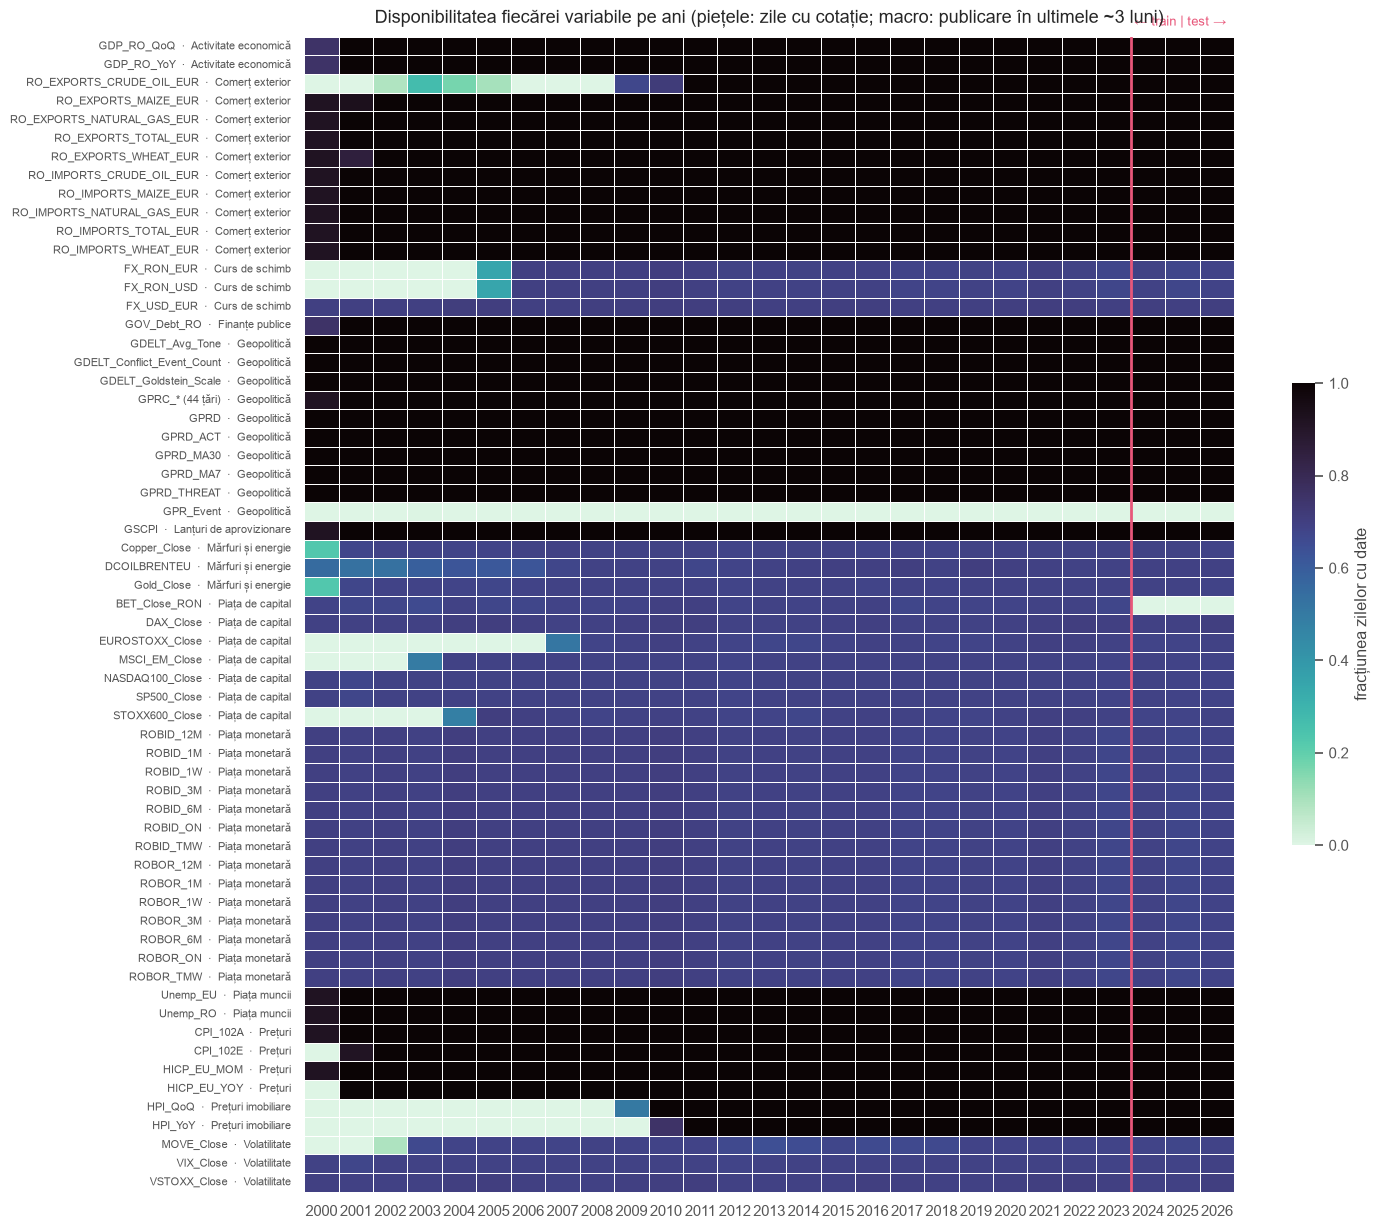

In [48]:
fara_gprc = [c for c in panou.columns if not c.startswith('GPRC_')]
disponibil = panou[fara_gprc].notna().copy()
# pentru seriile lunare/trimestriale, „disponibil” = a existat o publicare în ultimele 100 de zile
for c in fara_gprc:
    if FRECVENTA[c] in ('lunară', 'trimestrială'):
        disponibil[c] = panou[c].notna().astype(float).rolling(100, min_periods=1).max().astype(bool)
disponibil['GPRC_* (44 țări)'] = panou[[c for c in panou.columns if c.startswith('GPRC_')]].notna().any(axis=1).astype(float).rolling(40, min_periods=1).max().astype(bool)
cat_coloana = {c: (sumar['categorie'].get(c) if c in sumar.index else 'Geopolitică') for c in disponibil.columns}
ordine_disp = sorted(disponibil.columns, key=lambda c: (cat_coloana[c], c))
harta = disponibil[ordine_disp].groupby(disponibil.index.year).mean().T

fig, ax = plt.subplots(figsize=(15, 15))
sns.heatmap(harta, cmap=CMAP_DISP, vmin=0, vmax=1, cbar_kws={'label': 'fracțiunea zilelor cu date', 'shrink': 0.4},
            linewidths=0.4, linecolor=SUPRAFATA, ax=ax)
ax.set_yticks(np.arange(len(ordine_disp)) + 0.5)
ax.set_yticklabels([f"{c}  ·  {cat_coloana[c]}" for c in ordine_disp], fontsize=8)
ax.axvline(list(harta.columns).index(TEST_START.year), color=C_STRES, lw=2)
ax.text(list(harta.columns).index(TEST_START.year) + 0.1, -0.6, '← train | test →', color=C_STRES, fontsize=9)
ax.set_xlabel(''); ax.set_ylabel('')
ax.set_title('Disponibilitatea fiecărei variabile pe ani (piețele: zile cu cotație; macro: publicare în ultimele ~3 luni)')
plt.show()

### 📊 4.3 Ținta: când apar episoadele de stres?

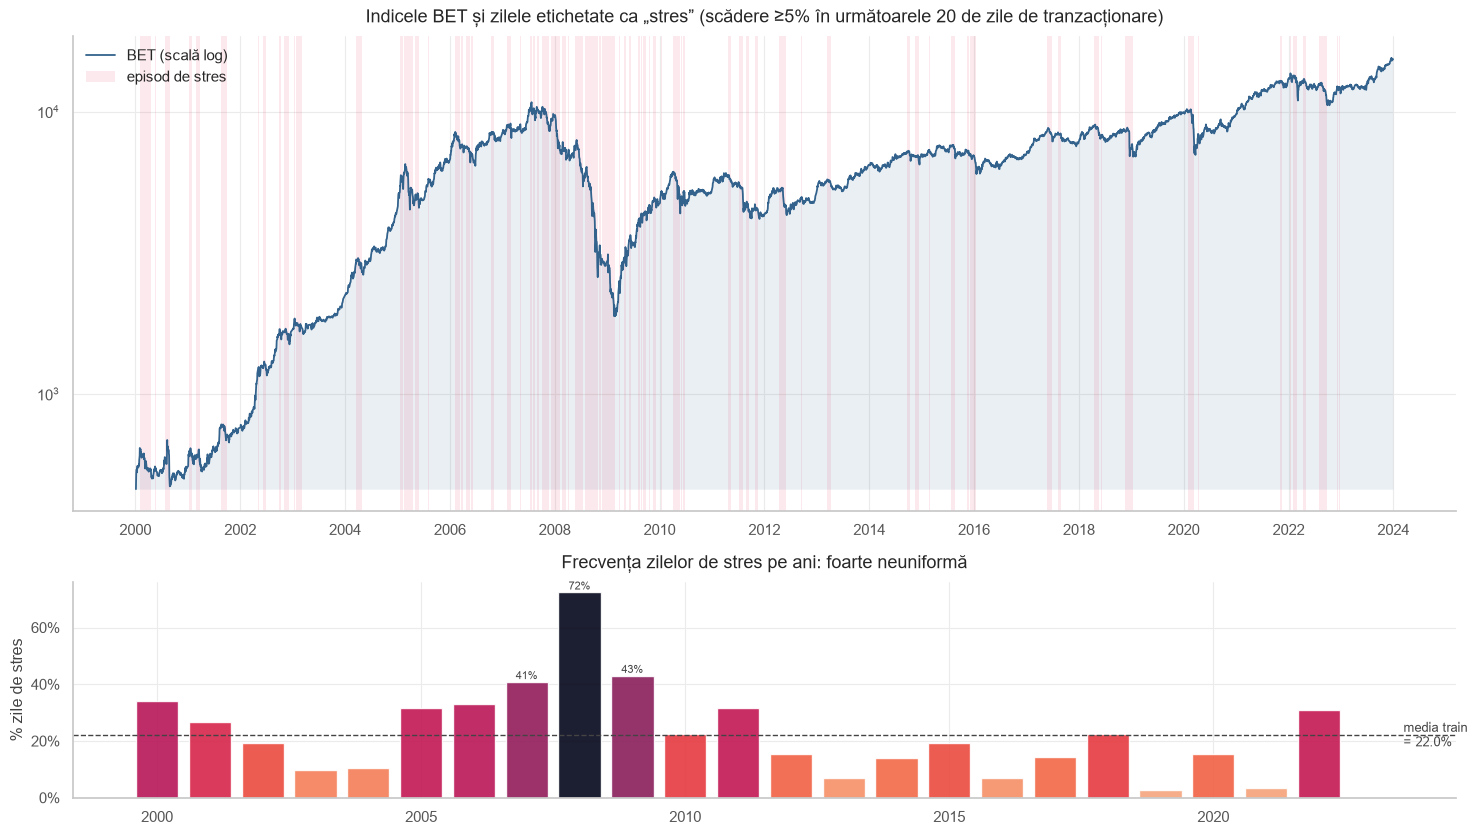

In [49]:
y_tr_cal = y.loc[:TRAIN_END]
fig, axes = plt.subplots(2, 1, figsize=(15, 8.5), gridspec_kw={'height_ratios': [2.2, 1]})
ax = axes[0]
linie(ax, bet.loc[:TRAIN_END], SERII[0], label='BET (scală log)', alpha_fill=0.10)
ax.set_yscale('log')
umbreste_stres(ax, y_tr_cal)
ax.legend(loc='upper left')
ax.set_title('Indicele BET și zilele etichetate ca „stres” (scădere ≥5% în următoarele 20 de zile de tranzacționare)')
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax = axes[1]
rata_an = y_tr_cal.groupby(y_tr_cal.index.year).mean()
ax.bar(rata_an.index, rata_an.values, color=CMAP_SECV(0.15 + 0.85 * rata_an.values / rata_an.max()), width=0.8, alpha=0.9)
ax.axhline(HISTORICAL_STRESS_RATE, color=C_TEXT, ls='--', lw=1)
ax.text(rata_an.index.max() + 0.6, HISTORICAL_STRESS_RATE, f'media train\n= {HISTORICAL_STRESS_RATE:.1%}', color=C_TEXT, fontsize=9, va='center')
for an_, v_ in rata_an.items():
    if v_ > 0.35:
        ax.text(an_, v_ + 0.01, f'{v_:.0%}', ha='center', fontsize=8, color=C_TEXT)
ax.set_ylabel('% zile de stres'); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Frecvența zilelor de stres pe ani: foarte neuniformă')
plt.tight_layout(); plt.show()

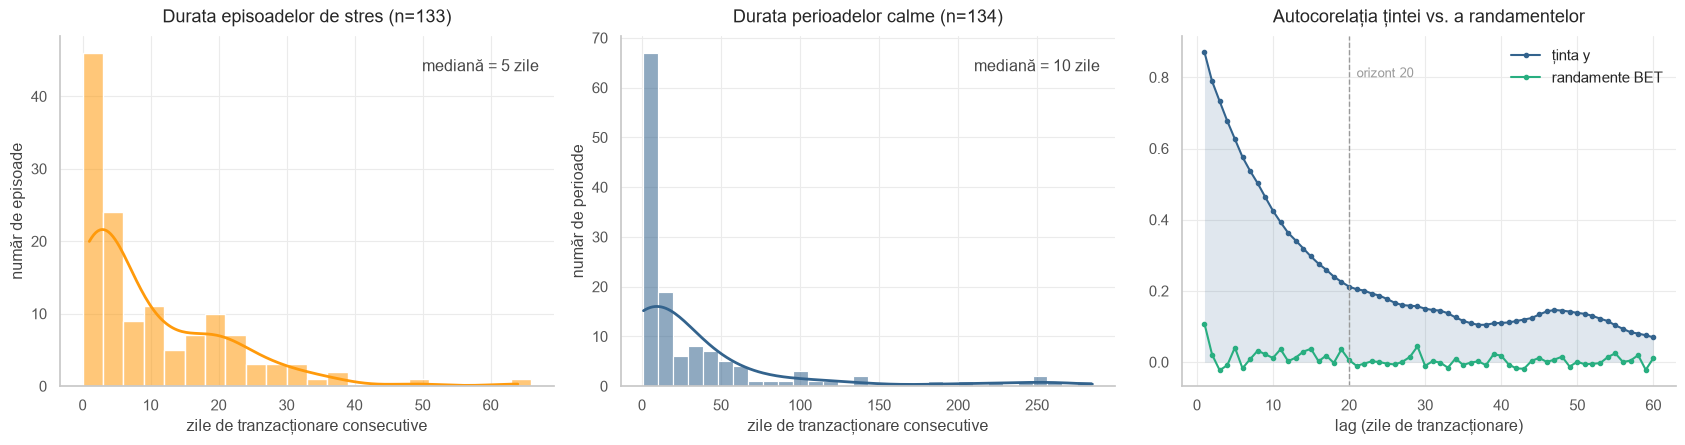

Episoade: 133, durată medie 9.9 zile; P(y_t=1 | y_(t-1)=1) = 0.90


In [50]:
# Structura episoadelor (doar din țintă, pe zilele de tranzacționare din train)
y_td = y.loc[:TRAIN_END].reindex(bet.index).dropna().astype(int)
episoade = y_td.groupby((y_td != y_td.shift()).cumsum()).agg(['first', 'size'])
durate = episoade.loc[episoade['first'] == 1, 'size']
calm = episoade.loc[episoade['first'] == 0, 'size']

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
sns.histplot(durate, bins=np.arange(0, durate.max() + 5, 3), kde=True, color=SERII[2], alpha=0.55, ax=ax, line_kws={'lw': 2})
ax.set_title(f'Durata episoadelor de stres (n={len(durate)})'); ax.set_xlabel('zile de tranzacționare consecutive'); ax.set_ylabel('număr de episoade')
ax.text(0.97, 0.9, f'mediană = {durate.median():.0f} zile', transform=ax.transAxes, ha='right', color=C_TEXT)
ax = axes[1]
sns.histplot(calm, bins=30, kde=True, color=SERII[0], alpha=0.55, ax=ax, line_kws={'lw': 2})
ax.set_title(f'Durata perioadelor calme (n={len(calm)})'); ax.set_xlabel('zile de tranzacționare consecutive'); ax.set_ylabel('număr de perioade')
ax.text(0.97, 0.9, f'mediană = {calm.median():.0f} zile', transform=ax.transAxes, ha='right', color=C_TEXT)
ax = axes[2]
lags = np.arange(1, 61)
acf_y = [y_td.autocorr(l) for l in lags]
acf_r = [np.log(bet).diff().autocorr(l) for l in lags]
ax.plot(lags, acf_y, color=SERII[0], marker='o', ms=3, label='ținta y')
ax.fill_between(lags, acf_y, color=SERII[0], alpha=0.15, lw=0)
ax.plot(lags, acf_r, color=SERII[1], marker='o', ms=3, label='randamente BET')
ax.axvline(20, color=C_GRI, ls='--', lw=1); ax.text(21, 0.8, 'orizont 20', color=C_GRI, fontsize=9)
ax.set_title('Autocorelația țintei vs. a randamentelor'); ax.set_xlabel('lag (zile de tranzacționare)'); ax.legend()
plt.tight_layout(); plt.show()
print(f"Episoade: {len(durate)}, durată medie {durate.mean():.1f} zile; P(y_t=1 | y_(t-1)=1) = {(y_td.shift() * y_td).sum() / y_td.shift().sum():.2f}")

Ținta este **puternic autocorelată** (ferestrele de 20 de zile se suprapun), de aceea validarea e walk-forward, cu pauză.

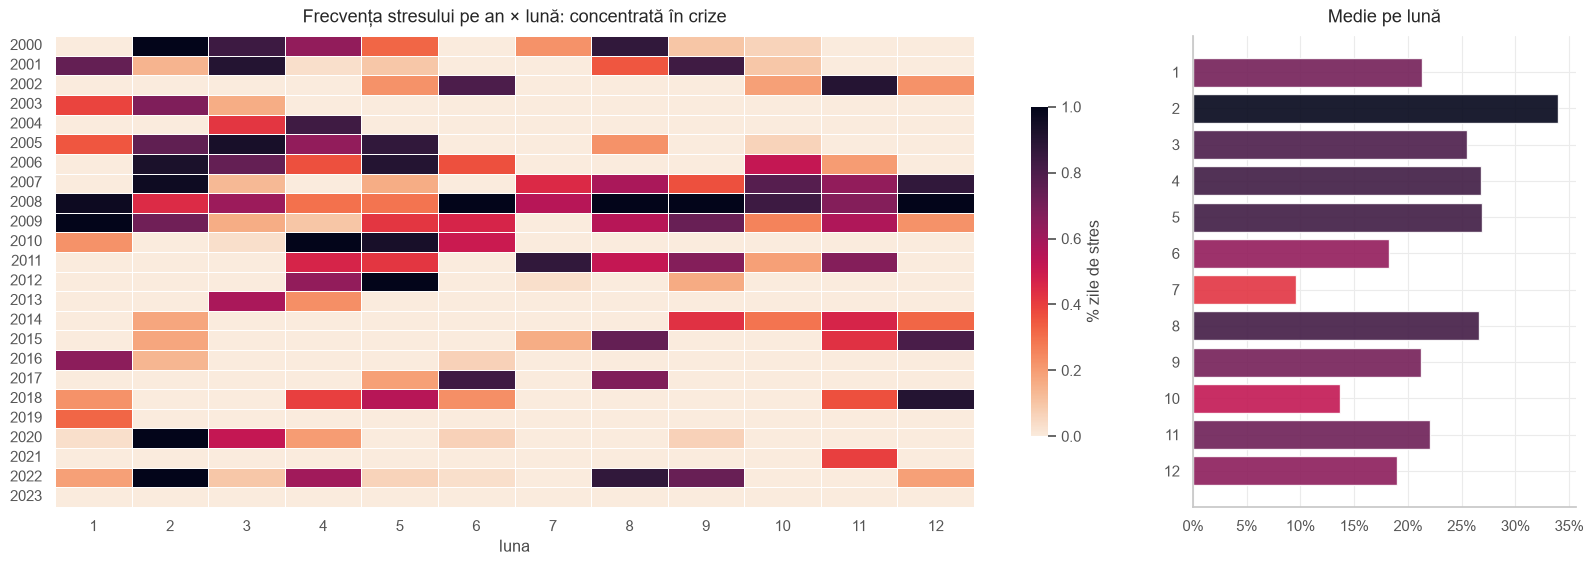

In [51]:
sezon = pd.DataFrame({'y': y_tr_cal, 'an': y_tr_cal.index.year, 'luna': y_tr_cal.index.month})
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={'width_ratios': [3, 1]})
sns.heatmap(sezon.pivot_table(index='an', columns='luna', values='y', aggfunc='mean'), cmap=CMAP_SECV, vmin=0, vmax=1,
            ax=axes[0], linewidths=0.6, linecolor='white', cbar_kws={'label': '% zile de stres', 'shrink': 0.7})
axes[0].set_title('Frecvența stresului pe an × lună: concentrată în crize'); axes[0].set_xlabel('luna'); axes[0].set_ylabel('')
luna_m = sezon.groupby('luna').y.mean()
axes[1].barh(luna_m.index, luna_m.values, color=CMAP_SECV(0.2 + 0.8 * luna_m.values / luna_m.max()), alpha=0.9)
axes[1].invert_yaxis(); axes[1].set_title('Medie pe lună'); axes[1].set_yticks(range(1, 13))
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()

### 📊 4.4 Indicatori-cheie, cu episoadele de stres suprapuse

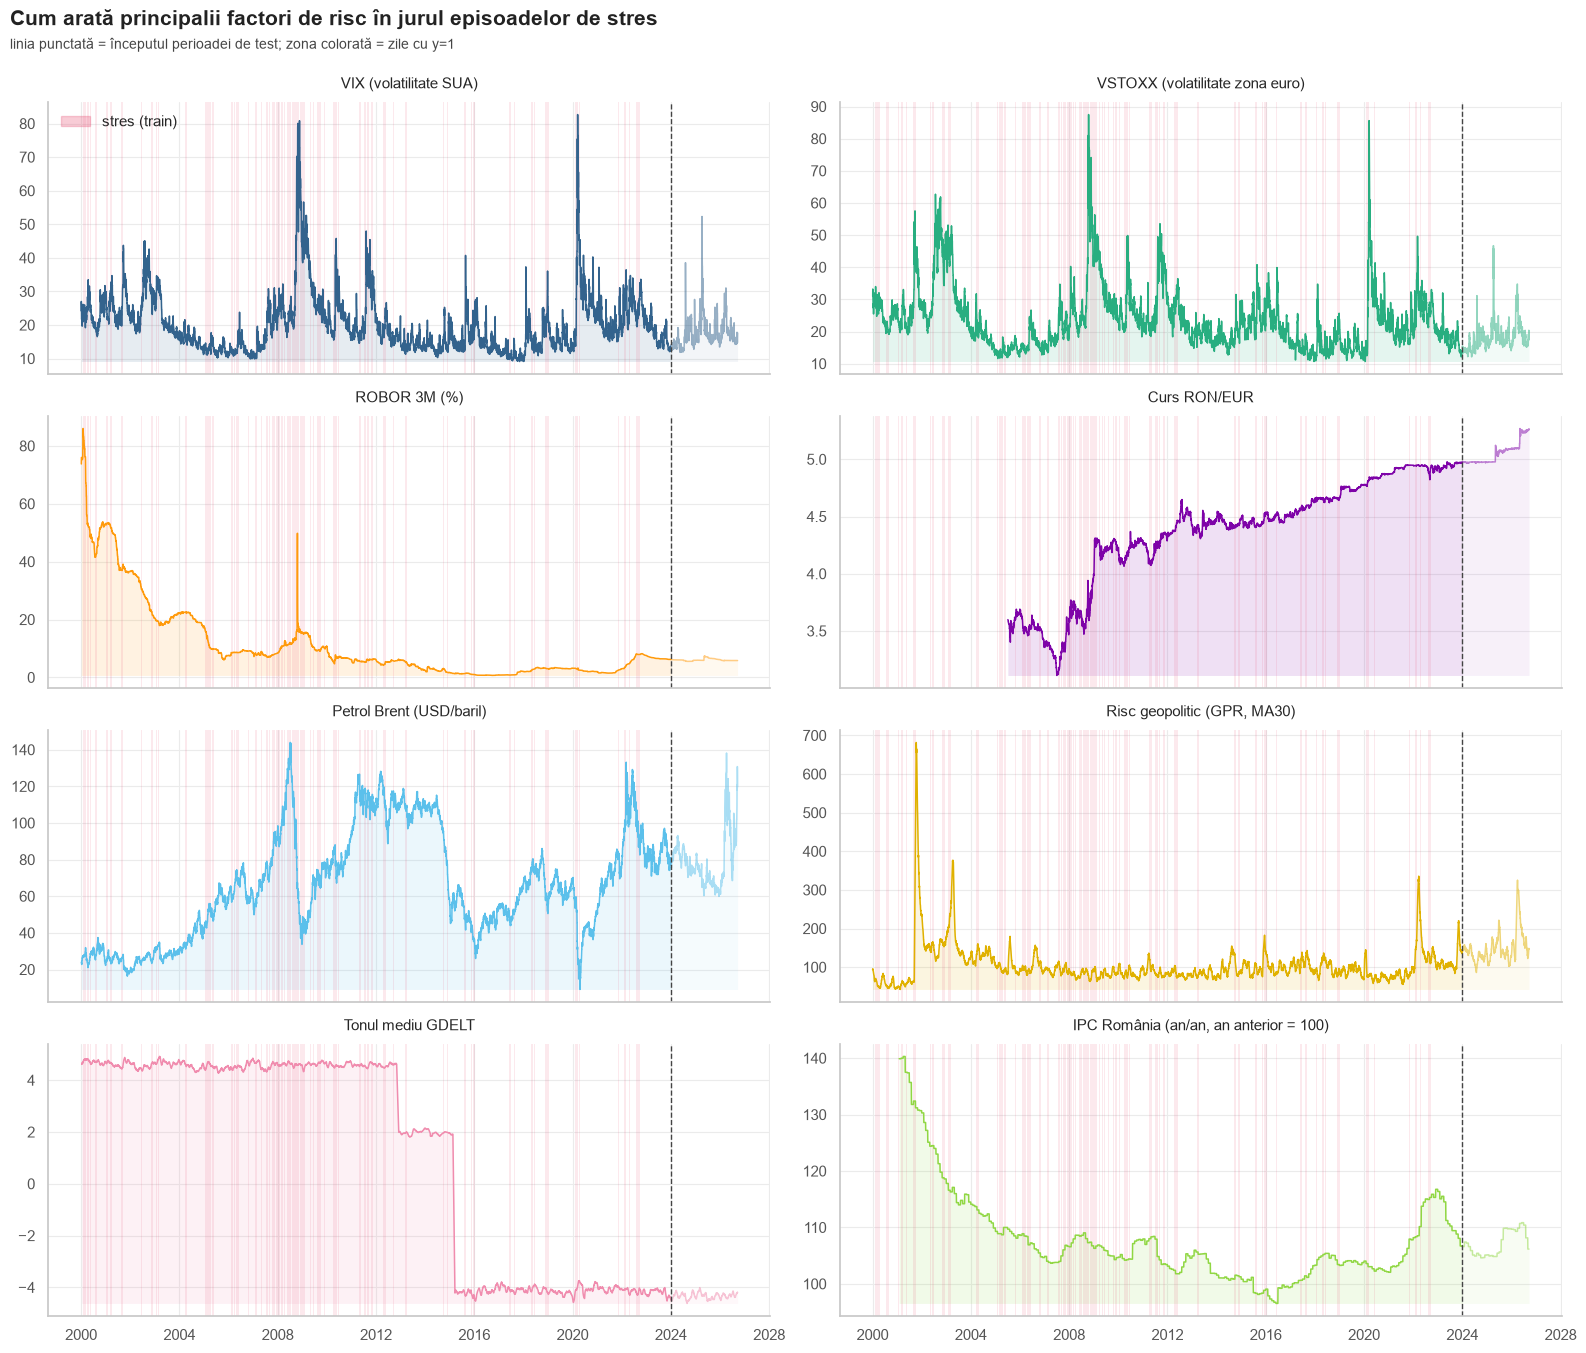

In [52]:
cheie = [('VIX_Close', 'VIX (volatilitate SUA)'), ('VSTOXX_Close', 'VSTOXX (volatilitate zona euro)'),
         ('ROBOR_3M', 'ROBOR 3M (%)'), ('FX_RON_EUR', 'Curs RON/EUR'),
         ('DCOILBRENTEU', 'Petrol Brent (USD/baril)'), ('GPRD_MA30', 'Risc geopolitic (GPR, MA30)'),
         ('GDELT_Avg_Tone', 'Tonul mediu GDELT'), ('CPI_102E', 'IPC România (an/an, an anterior = 100)')]
fig, axes = plt.subplots(4, 2, figsize=(16, 13), sharex=True)
for ax, (c, nume), col in zip(axes.flat, cheie, SERII):
    s = panou[c].ffill(limit=40) if FRECVENTA[c] in ('lunară', 'trimestrială') else panou[c].ffill(limit=5)
    if c == 'GDELT_Avg_Tone':
        s = s.rolling(30, min_periods=10).mean()
    linie(ax, s.loc[:TRAIN_END], col, baza=s.min(), lw=1.1)
    linie(ax, s.loc[TEST_START:], col, baza=s.min(), lw=1.1, alpha=0.5, alpha_fill=0.06)
    umbreste_stres(ax, y_tr_cal)
    ax.axvline(TEST_START, color=C_TEXT, ls='--', lw=1)
    ax.set_title(nume, fontsize=11)
axes[0, 0].legend(handles=[Patch(color=C_STRES, alpha=0.3, label='stres (train)')], loc='upper left')
titlu(fig, 'Cum arată principalii factori de risc în jurul episoadelor de stres', 'linia punctată = începutul perioadei de test; zona colorată = zile cu y=1')
plt.tight_layout(); plt.show()

⚠️ Tonul GDELT are o ruptură metodologică (GDELT 1.0 → 2.0), de aceea modelul folosește doar abaterea lui (`GDELT_ton_soc`).

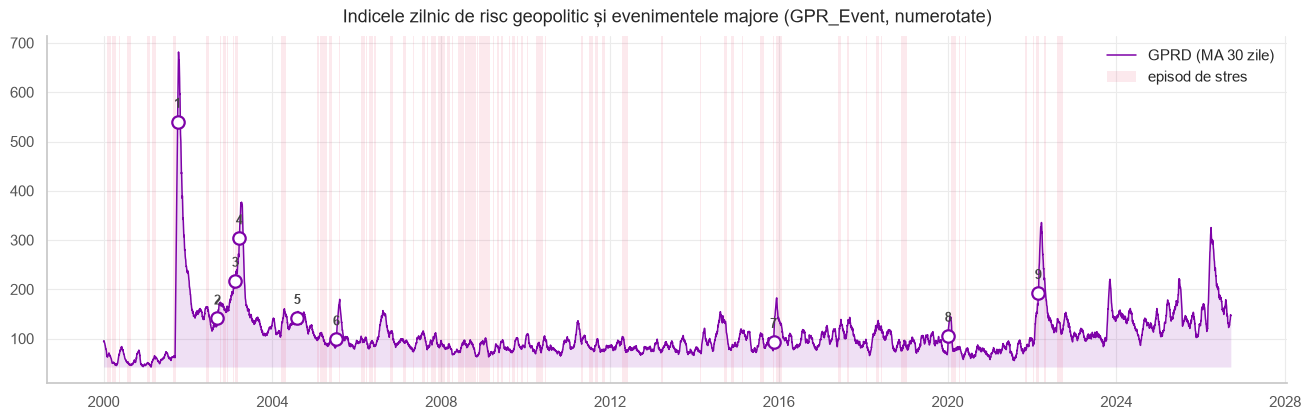

,eveniment,prima_zi
1,U.S. Invades Afghanistan,2001-10-03
2,Bush Seeks UN Approval for Iraq War; Putin Thr...,2002-09-13
3,War Fears U.S./Iraq; Terrorism in UK; Tension ...,2003-02-14
4,Beginning of the Iraq War,2003-03-21
5,Terrorist Threats in New York and Washington,2004-08-03
6,London Bombings 7/7,2005-07-08
7,Paris Terrorist Attacks,2015-11-17
8,U.S. / Iran Tensions Escalate,2020-01-07
9,Russia / Ukraine Tensions,2022-02-25


In [53]:
ev = panou['GPR_Event'].dropna().astype(str).str.strip()
ev = ev[ev != '']
prim_eveniment = ev.groupby(ev).apply(lambda s: s.index.min()).sort_values()
fig, ax = plt.subplots(figsize=(16, 4.5))
linie(ax, panou['GPRD_MA30'], SERII[3], label='GPRD (MA 30 zile)', alpha_fill=0.12, lw=1.1)
umbreste_stres(ax, y_tr_cal)
for i, (nume_ev, d_ev) in enumerate(prim_eveniment.items(), start=1):
    yv = panou['GPRD_MA30'].loc[d_ev]
    ax.scatter(d_ev, yv, s=80, color='white', edgecolor=SERII[3], zorder=5, lw=1.6)
    ax.annotate(str(i), xy=(d_ev, yv), xytext=(0, 10), textcoords='offset points', ha='center', fontsize=9, fontweight='bold', color=C_TEXT)
ax.set_title('Indicele zilnic de risc geopolitic și evenimentele majore (GPR_Event, numerotate)'); ax.legend(loc='upper right')
plt.show()
display(pd.DataFrame({'eveniment': prim_eveniment.index, 'prima_zi': prim_eveniment.dt.date.values}, index=range(1, len(prim_eveniment) + 1)))

### 📊 4.5 De ce aliniem la data publicării (dezagregare temporală)
| Metodă | Idee | Leakage? |
|---|---|---|
| **A. ffill simplu** | valoarea lunii se aplică de la data de referință | da: e „văzută” înainte de publicare |
| **B. ffill la publicare** | valoarea se aplică de la data publicării (**folosită în model**) | nu |
| **C. interpolare liniară** | linie dreaptă între două luni | da: folosește valoarea următoare |
| **D. extrapolare cauzală** | continuă trendul ultimelor două publicări | nu (dar zgomotoasă) |

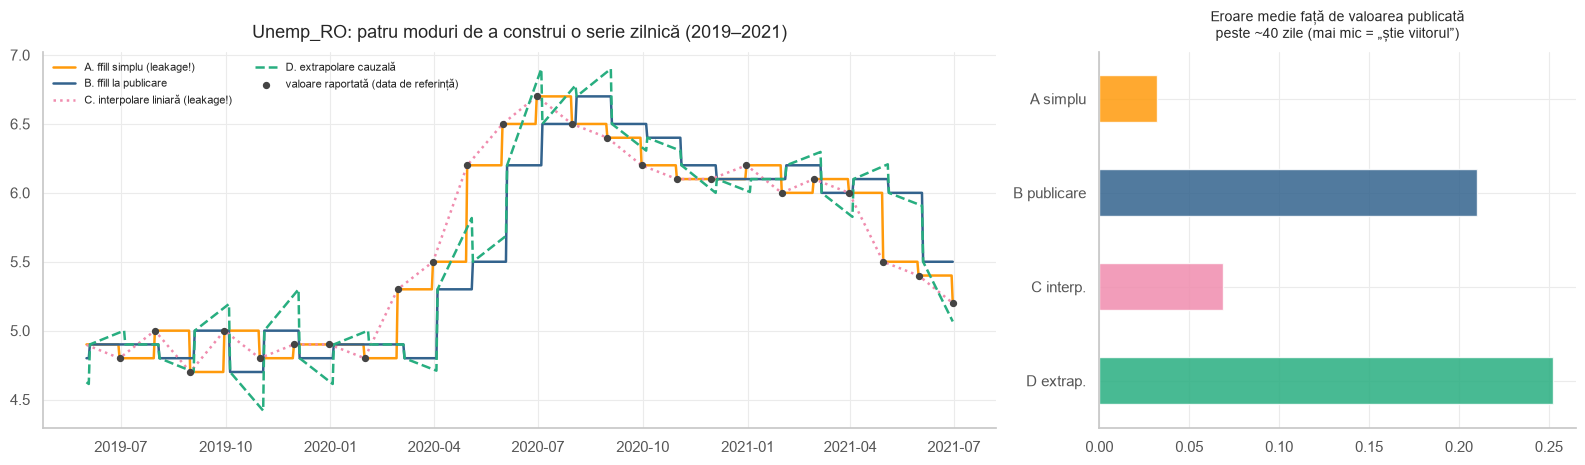

Lipsă după aliniere (train, %):
HPI_YoY                     43.8
HPI_QoQ                     40.7
EUROSTOXX_Close             30.2
FX_RON_USD                  22.9
FX_RON_EUR                  22.9
STOXX600_Close              18.0
MSCI_EM_Close               13.7
RO_EXPORTS_CRUDE_OIL_EUR    12.7


In [54]:
var_demo, dec_demo = 'Unemp_RO', DECALAJ_PUBLICARE['Unemp_RO']
idx_cal = panou.index
A = panou[var_demo].ffill()
B = aliniaza_la_publicare(panou[var_demo], dec_demo, idx_cal)
C_interp = panou[var_demo].interpolate(method='time', limit_area='inside')
obs_pub = panou[var_demo].dropna()
obs_pub.index = obs_pub.index + pd.Timedelta(days=dec_demo)
panta = obs_pub.diff() / obs_pub.index.to_series().diff().dt.days
zile_de_la_pub = idx_cal.to_series() - aliniaza_la_publicare(pd.Series(obs_pub.index, index=obs_pub.index - pd.Timedelta(days=dec_demo)), dec_demo, idx_cal)
D = B + aliniaza_la_publicare(panta.set_axis(panta.index - pd.Timedelta(days=dec_demo)), dec_demo, idx_cal) * zile_de_la_pub.dt.days

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [2, 1]})
fereastra = slice('2019-06-01', '2021-06-30')
ax = axes[0]
for s, nume, col, ls in [(A, 'A. ffill simplu (leakage!)', SERII[2], '-'), (B, 'B. ffill la publicare', SERII[0], '-'),
                         (C_interp, 'C. interpolare liniară (leakage!)', SERII[6], ':'), (D, 'D. extrapolare cauzală', SERII[1], '--')]:
    ax.plot(s.loc[fereastra], label=nume, color=col, ls=ls, lw=1.8)
ax.scatter(panou[var_demo].dropna().loc[fereastra].index, panou[var_demo].dropna().loc[fereastra], color=C_TEXT, s=18, zorder=5, label='valoare raportată (data de referință)')
ax.legend(fontsize=8, ncol=2); ax.set_title(f'{var_demo}: patru moduri de a construi o serie zilnică (2019–2021)')
ax = axes[1]
urmatoarea_publicare = B.shift(-40)
erori = {nume: (s - urmatoarea_publicare).abs().loc['2002':'2023'].mean()
         for s, nume in [(A, 'A simplu'), (B, 'B publicare'), (C_interp, 'C interp.'), (D, 'D extrap.')]}
pd.Series(erori).plot.barh(ax=ax, color=[SERII[2], SERII[0], SERII[6], SERII[1]], alpha=0.85)
ax.invert_yaxis()
ax.set_title('Eroare medie față de valoarea publicată\npeste ~40 zile (mai mic = „știe viitorul”)', fontsize=10)
plt.tight_layout(); plt.show()
print('Lipsă după aliniere (train, %):')
print((panou_aliniat.loc[:TRAIN_END, ZILNICE + COLOANE_RARE].isna().mean() * 100).sort_values(ascending=False).head(8).round(1).to_string())

Variantele A și C par mai bune doar pentru că **au acces la viitor**; de aceea modelul folosește varianta B.

## 5. Feature engineering
Toate transformările folosesc doar trecutul (`diff`, `rolling`, `ewm`). Nu construim variabile pe care selecția le elimină sigur
(variabile din BET, care lipsește în test; niveluri `_nivel`, `GPRC_*`, topicuri NLP, număr de documente).

### 5.1 Piețe (zile lucrătoare)

In [55]:
log_ret = lambda s, h: np.log(s.where(s > 0)).diff(h)
vol = lambda s, w: np.log(s.where(s > 0)).diff().rolling(w, min_periods=int(w * 0.7)).std() * np.sqrt(252)
dd = lambda s, w: s / s.rolling(w, min_periods=int(w * 0.5)).max() - 1
zsc = lambda s, w: (s - s.rolling(w, min_periods=int(w * 0.5)).mean()) / s.rolling(w, min_periods=int(w * 0.5)).std()


def rsi(s, n=14):
    """RSI Wilder: medii exponențiale cu alpha = 1/n."""
    d = s.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, min_periods=n, adjust=False).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, min_periods=n, adjust=False).mean()
    return 100 - 100 / (1 + up / dn)          # dn = 0 -> inf -> 100; inf-urile rămase devin NaN la asamblare


def ppo(s, f=12, sl=26, sig=9):
    """MACD normalizat (Percentage Price Oscillator) și histograma lui."""
    m = (s.ewm(span=f, min_periods=f, adjust=False).mean() /
         s.ewm(span=sl, min_periods=sl, adjust=False).mean() - 1) * 100
    return m, m - m.ewm(span=sig, min_periods=sig, adjust=False).mean()


def variabile_piata(zl):
    """Randamente, volatilitate, drawdown, z-score, dobânzi, mărfuri și indicatori tehnici (RSI, PPO)."""
    F = {}
    for c, n in [('EUROSTOXX_Close', 'EUROSTOXX'), ('STOXX600_Close', 'STOXX600'), ('DAX_Close', 'DAX'),
                 ('SP500_Close', 'SP500'), ('NASDAQ100_Close', 'NASDAQ'), ('MSCI_EM_Close', 'MSCI_EM')]:
        s = zl[c]
        F[f'{n}_ret_5z'] = log_ret(s, 5)
        F[f'{n}_ret_20z'] = log_ret(s, 20)
        F[f'{n}_vol_20z'] = vol(s, 20)
        F[f'{n}_drawdown_250z'] = dd(s, 250)
    for c, n in [('VIX_Close', 'VIX'), ('VSTOXX_Close', 'VSTOXX'), ('MOVE_Close', 'MOVE')]:
        s = zl[c]
        F[f'{n}_chg_5z'] = log_ret(s, 5)
        F[f'{n}_chg_20z'] = log_ret(s, 20)
        F[f'{n}_z_250z'] = zsc(s, 250)
    F['VIX_term_VSTOXX'] = zl['VSTOXX_Close'] - zl['VIX_Close']
    # Curs valutar
    F['RONEUR_ret_5z'] = log_ret(zl['FX_RON_EUR'], 5)
    F['RONEUR_ret_20z'] = log_ret(zl['FX_RON_EUR'], 20)
    F['RONEUR_ret_60z'] = log_ret(zl['FX_RON_EUR'], 60)
    F['RONEUR_vol_20z'] = vol(zl['FX_RON_EUR'], 20)
    F['RONEUR_z_250z'] = zsc(zl['FX_RON_EUR'], 250)
    F['RONUSD_ret_20z'] = log_ret(zl['FX_RON_USD'], 20)
    F['USDEUR_ret_20z'] = log_ret(zl['FX_USD_EUR'], 20)
    # Dobânzi
    for c in ('ROBOR_ON', 'ROBOR_3M', 'ROBOR_12M'):
        F[f'{c}_chg_20z'] = zl[c].diff(20)
    F['ROBOR_3M_z_250z'] = zsc(zl['ROBOR_3M'], 250)
    F['ROBOR_panta_12M_ON'] = zl['ROBOR_12M'] - zl['ROBOR_ON']
    F['ROBOR_ROBID_spread_3M'] = zl['ROBOR_3M'] - zl['ROBID_3M']
    F['ROBOR_ON_vol_20z'] = zl['ROBOR_ON'].diff().rolling(20, min_periods=14).std()
    # Energie și mărfuri
    for c, n in [('DCOILBRENTEU', 'BRENT'), ('Gold_Close', 'AUR'), ('Copper_Close', 'CUPRU')]:
        F[f'{n}_ret_20z'] = log_ret(zl[c], 20)
    F['BRENT_ret_5z'] = log_ret(zl['DCOILBRENTEU'], 5)
    F['BRENT_ret_60z'] = log_ret(zl['DCOILBRENTEU'], 60)
    F['BRENT_vol_20z'] = vol(zl['DCOILBRENTEU'], 20)
    F['CUPRU_AUR_ret_60z'] = log_ret(zl['Copper_Close'] / zl['Gold_Close'], 60)
    # Indicatori tehnici
    for c, n in [('STOXX600_Close', 'STOXX600'), ('SP500_Close', 'SP500'),
                 ('MSCI_EM_Close', 'MSCI_EM'), ('DCOILBRENTEU', 'BRENT')]:
        F[f'{n}_rsi14'] = rsi(zl[c])
        F[f'{n}_ppo'], F[f'{n}_ppo_hist'] = ppo(zl[c])
    return pd.DataFrame(F)


F_piata = variabile_piata(zl)

### 5.2 Geopolitică și macroeconomie (calendar complet)

In [56]:
def variabile_geo_macro(cal, panou):
    """Riscul geopolitic (GPR, GDELT) și seriile macro, aliniate la data publicării."""
    F = {}
    F['GPRD_log'] = np.log1p(cal['GPRD'])
    F['GPRD_MA7'] = cal['GPRD_MA7']
    F['GPRD_MA30'] = cal['GPRD_MA30']
    F['GPRD_z_365z'] = zsc(cal['GPRD_MA7'], 365)
    F['GPRD_ACT_THREAT_ratio_30z'] = (cal['GPRD_ACT'].rolling(30).mean() / cal['GPRD_THREAT'].rolling(30).mean())
    # Doar abaterea tonului GDELT: nivelul are o ruptură metodologică (GDELT 1.0 -> 2.0)
    F['GDELT_ton_soc'] = cal['GDELT_Avg_Tone'].rolling(7, min_periods=4).mean() - cal['GDELT_Avg_Tone'].rolling(90, min_periods=45).mean()
    F['GDELT_goldstein_30z'] = cal['GDELT_Goldstein_Scale'].rolling(30, min_periods=15).mean()
    F['GDELT_conflict_z_365z'] = zsc(np.log1p(cal['GDELT_Conflict_Event_Count']).rolling(7, min_periods=4).mean(), 365)
    are_eveniment = cal['GPR_Event'].astype(str).str.strip().replace({'nan': '', 'None': ''}).ne('').astype(float)
    F['GPR_eveniment_30z'] = are_eveniment.rolling(30, min_periods=1).max()

    L = lambda c: panou[c].dropna()            # seria la frecvența ei naturală (data de referință)
    macro = lambda serie, sursa: aliniaza_la_publicare(serie, DECALAJ_PUBLICARE.get(sursa, DECALAJ_IMPLICIT), cal.index)
    exp_t, imp_t = L('RO_EXPORTS_TOTAL_EUR'), L('RO_IMPORTS_TOTAL_EUR')
    F['IPC_RO_anual'] = macro(L('CPI_102E') - 100, 'CPI_102E')
    F['IPC_RO_lunar'] = macro(L('CPI_102A') - 100, 'CPI_102A')
    F['IPC_RO_anual_chg3'] = macro((L('CPI_102E') - 100).diff(3), 'CPI_102E')
    F['HICP_UE_anual'] = macro(L('HICP_EU_YOY'), 'HICP_EU_YOY')
    F['INFL_diferential_RO_UE'] = macro((L('CPI_102E') - 100).sub(L('HICP_EU_YOY'), fill_value=np.nan), 'CPI_102E')
    F['GSCPI'] = macro(L('GSCPI'), 'GSCPI')
    F['GSCPI_chg3'] = macro(L('GSCPI').diff(3), 'GSCPI')
    F['Somaj_RO'] = macro(L('Unemp_RO'), 'Unemp_RO')
    F['Somaj_RO_chg12'] = macro(L('Unemp_RO').diff(12), 'Unemp_RO')
    F['Somaj_UE'] = macro(L('Unemp_EU'), 'Unemp_EU')
    F['Comert_acoperire_exp_imp'] = macro((exp_t / imp_t).rolling(3).mean(), 'RO_EXPORTS_TOTAL_EUR')
    F['Export_crestere_anuala'] = macro(np.log(exp_t.rolling(3).sum()).diff(12), 'RO_EXPORTS_TOTAL_EUR')
    F['Import_energie_pondere'] = macro(((L('RO_IMPORTS_CRUDE_OIL_EUR').reindex(imp_t.index).fillna(0) + L('RO_IMPORTS_NATURAL_GAS_EUR').reindex(imp_t.index).fillna(0)) / imp_t).rolling(3).mean(), 'RO_IMPORTS_TOTAL_EUR')
    F['PIB_RO_anual'] = macro(L('GDP_RO_YoY'), 'GDP_RO_YoY')
    F['PIB_RO_trim'] = macro(L('GDP_RO_QoQ'), 'GDP_RO_QoQ')
    F['PIB_RO_surpriza'] = macro(L('GDP_RO_YoY').diff(), 'GDP_RO_YoY')
    F['Datorie_gov_RO'] = macro(L('GOV_Debt_RO'), 'GOV_Debt_RO')
    F['HPI_anual'] = macro(L('HPI_YoY'), 'HPI_YoY')
    return pd.DataFrame(F)


F_geo_macro = variabile_geo_macro(cal, panou)

### 5.3 Text (NLP)
Reparăm encoding-ul, numărăm cuvintele din lexicoane bilingve (EN + RO) și agregăm zilnic. Un document devine disponibil
**a doua zi** după publicare (nu știm ora publicării).

In [57]:
STOP_RO = """acest această aceasta aceste acestea acesta aceea acel acea acele ale alte altor anul are asupra avea avut
care cea cel cele celor ceea cât cum când dar decât din dintre după este față fiind fost iar însă între mai mult multe
nici noi nostru numai până pentru prin sau sunt sub spre tot toate unei unui unor vor fie dacă luna lunii""".split()
STOP_ALTE = """les des que los las der die und das del por para une dans est sur pour mit von den dem zur ist nicht sich auch
http https www com html php pdf europa web contact title explained""".split()
STOP = sorted(set(ENGLISH_STOP_WORDS) | set(STOP_RO) | set(STOP_ALTE))

LEXICOANE = {
    'negativ': ['crisis', 'crises', 'decline', 'loss', 'losses', 'weak', 'recession', 'default', 'stress', 'turmoil', 'downturn',
                'contagion', 'shock', 'deteriorat', 'slowdown', 'fragil', 'vulnerab', 'tension', 'war', 'sanction', 'insolven',
                'bankrupt', 'panic', 'adverse', 'downgrad', 'collapse', 'distress', 'severe', 'worsen',
                'criz', 'scăder', 'pierder', 'recesiun', 'tensiun', 'război', 'vulnerab', 'dezechilibr', 'încetinir',
                'șoc', 'insolvenț', 'falimen', 'sancțiun', 'deteriorar', 'negativ', 'contracți'],
    'pozitiv': ['growth', 'recover', 'improv', 'stabl', 'strong', 'resilien', 'confiden', 'gain', 'expansion', 'robust',
                'optimis', 'upturn', 'favourab', 'favorab', 'creșter', 'redresar', 'stabil', 'îmbunătăț', 'robust',
                'favorabil', 'consolidar', 'încreder', 'pozitiv'],
    'incertitudine': ['uncertain', 'unclear', 'unpredict', 'volatil', 'ambigu', 'doubt', 'fluctuat', 'risk', 'risks',
                      'incertitudin', 'volatilit', 'risc', 'riscuri', 'imprevizib', 'fluctuați'],
    'hawkish': ['tighten', 'hike', 'hikes', 'overheat', 'hawkish', 'restrictive', 'inflationary', 'inflați', 'majorar', 'restrictiv'],
    'dovish': ['easing', 'accommodat', 'stimulus', 'dovish', 'cut', 'cuts', 'relaxar', 'reducer', 'stimul'],
}
LEX_TOATE = ['lex_negativ', 'lex_pozitiv', 'lex_incertitudine', 'lex_ton_net', 'lex_hawk_dove']


def repara_text(s):
    """Repară textul dublu-codat (UTF-8 citit ca cp1252/latin-1) și unifică diacriticele cu sedilă."""
    if not isinstance(s, str):
        return ''
    if 'Ã' in s or 'Å' in s or 'â€' in s:
        for enc in ('cp1252', 'latin-1'):
            try:
                s = s.encode(enc).decode('utf-8')
                break
            except (UnicodeEncodeError, UnicodeDecodeError):
                continue
    return s.replace('ş', 'ș').replace('ţ', 'ț').replace('Ş', 'Ș').replace('Ţ', 'Ț')


def scoruri_lexicon(nlp_raw):
    """Pe fiecare document: apariții la 1000 de cuvinte pentru fiecare lexicon, plus tonul net și hawkish − dovish."""
    nlp = nlp_raw.copy()
    nlp['publication_date'] = pd.to_datetime(nlp['publication_date'])
    nlp['text'] = nlp['text'].fillna('')
    nlp['text_curat'] = (nlp['title'].fillna('') + '. ' + nlp['text']).map(repara_text).str.lower()
    nlp['grup'] = np.where(nlp['institution'].isin(['BNR', 'INSSE', 'GDELT']), 'RO', 'Global')
    vect = CountVectorizer(token_pattern=r'(?u)\b[^\W\d_]{3,}\b', min_df=5, max_df=0.6, stop_words=STOP, dtype=np.int32)
    dtm = vect.fit_transform(nlp['text_curat'])
    vocab = np.array(vect.get_feature_names_out())
    n_tokens = np.asarray(dtm.sum(axis=1)).ravel() + 1
    for nume, prefixe in LEXICOANE.items():
        coloane = np.where(np.array([any(t.startswith(p) for p in prefixe) for t in vocab]))[0]
        nlp[f'lex_{nume}'] = np.asarray(dtm[:, coloane].sum(axis=1)).ravel() / n_tokens * 1000
    nlp['lex_ton_net'] = nlp['lex_pozitiv'] - nlp['lex_negativ']
    nlp['lex_hawk_dove'] = nlp['lex_hawkish'] - nlp['lex_dovish']
    nlp['data_disponibil'] = nlp['publication_date'].dt.normalize() + pd.Timedelta(days=1)
    return nlp, dtm, vocab


def agregare_zilnica(df, coloane, sufix, halflife, index):
    """Medie exponențială (pe zile calendaristice) a scorurilor; zilele fără documente nu aduc informație nouă."""
    g = df.groupby('data_disponibil')
    sume = g[coloane].sum().reindex(index, fill_value=0)
    nr = g.size().reindex(index, fill_value=0)
    out = sume.ewm(halflife=halflife).mean().div(nr.ewm(halflife=halflife).mean().replace(0, np.nan), axis=0)
    out.columns = [f'TXT_{sufix}_{c}_hl{halflife}' for c in coloane]
    return out


nlp, DTM, vocab = scoruri_lexicon(nlp_raw)
F_text = pd.concat([agregare_zilnica(nlp, LEX_TOATE, 'GLOBAL', 30, cal.index),
                    agregare_zilnica(nlp, ['lex_negativ', 'lex_incertitudine', 'lex_ton_net'], 'GLOBAL', 7, cal.index),
                    agregare_zilnica(nlp[nlp.grup == 'RO'], LEX_TOATE, 'RO', 45, cal.index)], axis=1)
F_text['TXT_GLOBAL_soc_negativ'] = F_text['TXT_GLOBAL_lex_negativ_hl7'] - F_text['TXT_GLOBAL_lex_negativ_hl30']

### 📊 5.3.1 Datele textuale: ce documente avem și ce spun

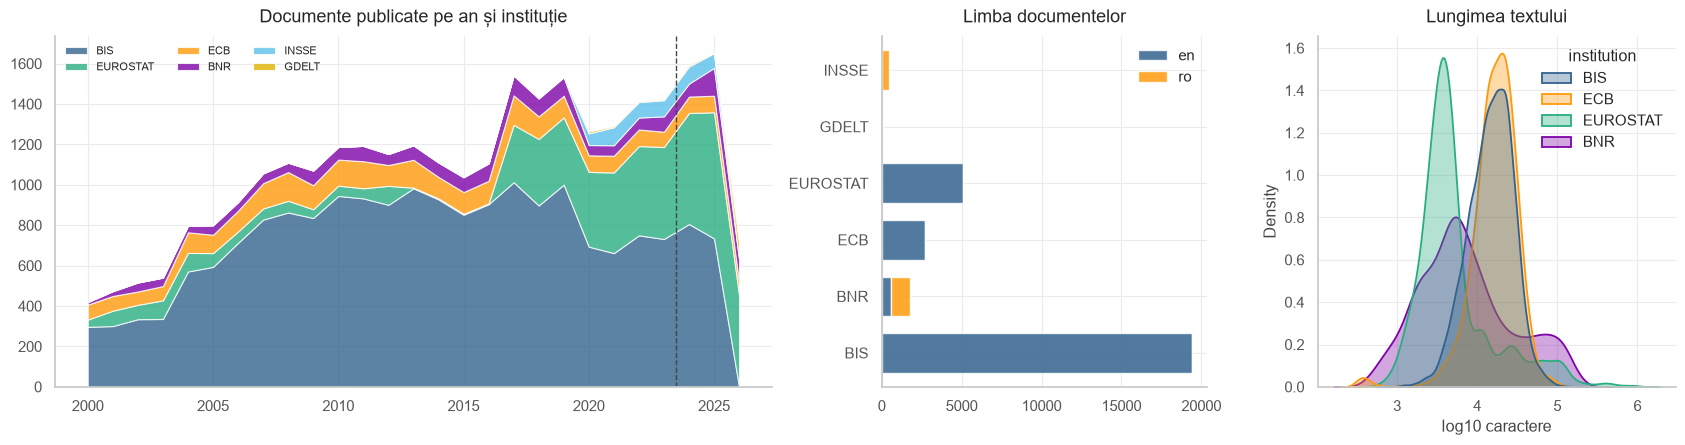

Titluri cu encoding stricat: 272  ex: "Birgir Ã\x8dsleifur Gunnarsson: Update on Iceland's economy"


In [58]:
nlp_eda = nlp.assign(n_caractere=nlp['text'].str.len())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [2.2, 1, 1.1]})
ax = axes[0]
ct = nlp_eda.groupby([nlp_eda.publication_date.dt.year, 'institution']).size().unstack(fill_value=0)
ct = ct[ct.sum().sort_values(ascending=False).index]
ax.stackplot(ct.index, ct.T.values, labels=ct.columns, colors=SERII[:ct.shape[1]], alpha=0.8, edgecolor='white', lw=0.8)
ax.axvline(TEST_START.year - 0.5, color=C_TEXT, ls='--', lw=1)
ax.legend(loc='upper left', ncol=3, fontsize=8); ax.set_title('Documente publicate pe an și instituție')
ax = axes[1]
nlp_eda.groupby(['institution', 'language']).size().unstack(fill_value=0).plot.barh(stacked=True, ax=ax, color=[SERII[0], SERII[2]], width=0.7, alpha=0.85)
ax.set_title('Limba documentelor'); ax.set_ylabel(''); ax.legend(title='')
ax = axes[2]
lung = nlp_eda.loc[nlp_eda.institution.isin(ct.columns[:4]), ['institution', 'n_caractere']].copy()
lung['log10 caractere'] = np.log10(lung['n_caractere'].clip(lower=50))
sns.kdeplot(data=lung, x='log10 caractere', hue='institution', fill=True, common_norm=False, alpha=ALFA,
            palette=dict(zip(ct.columns[:4], SERII[:4])), linewidth=1.3, ax=ax)
ax.set_title('Lungimea textului')
plt.tight_layout(); plt.show()
mask_moj = nlp_raw['title'].str.contains('Ã|Å|â€', regex=True, na=False)
print(f"Titluri cu encoding stricat: {mask_moj.sum()}  ex: {nlp_raw.loc[mask_moj, 'title'].iloc[0][:70]!r}")

Cuvintele dominante ale fiecărui topic LSA:
  topic_0: inflation, rate, euro, stability, risk, markets, rates, term, area
  topic_1: eurostat, statistics, news, user, index, glossary, lang, products, false
  topic_2: inflation, prices, outlook, rate, rates, price, demand, oil, target
  topic_3: ind, domain, inactive, freshness, extractions, domains, stopped, dec, series
  topic_4: euro, ecb, european, area, union, council, governing, eurosystem, europe
  topic_5: federal, paper, does, example, question, economics, journal, reserve, different
  topic_6: bnr, perioada, termen, inflației, sută, româniei, false, monetară, creștere
  topic_7: liquidity, lending, credit, loans, funding, assets, regulatory, supervisory, risk


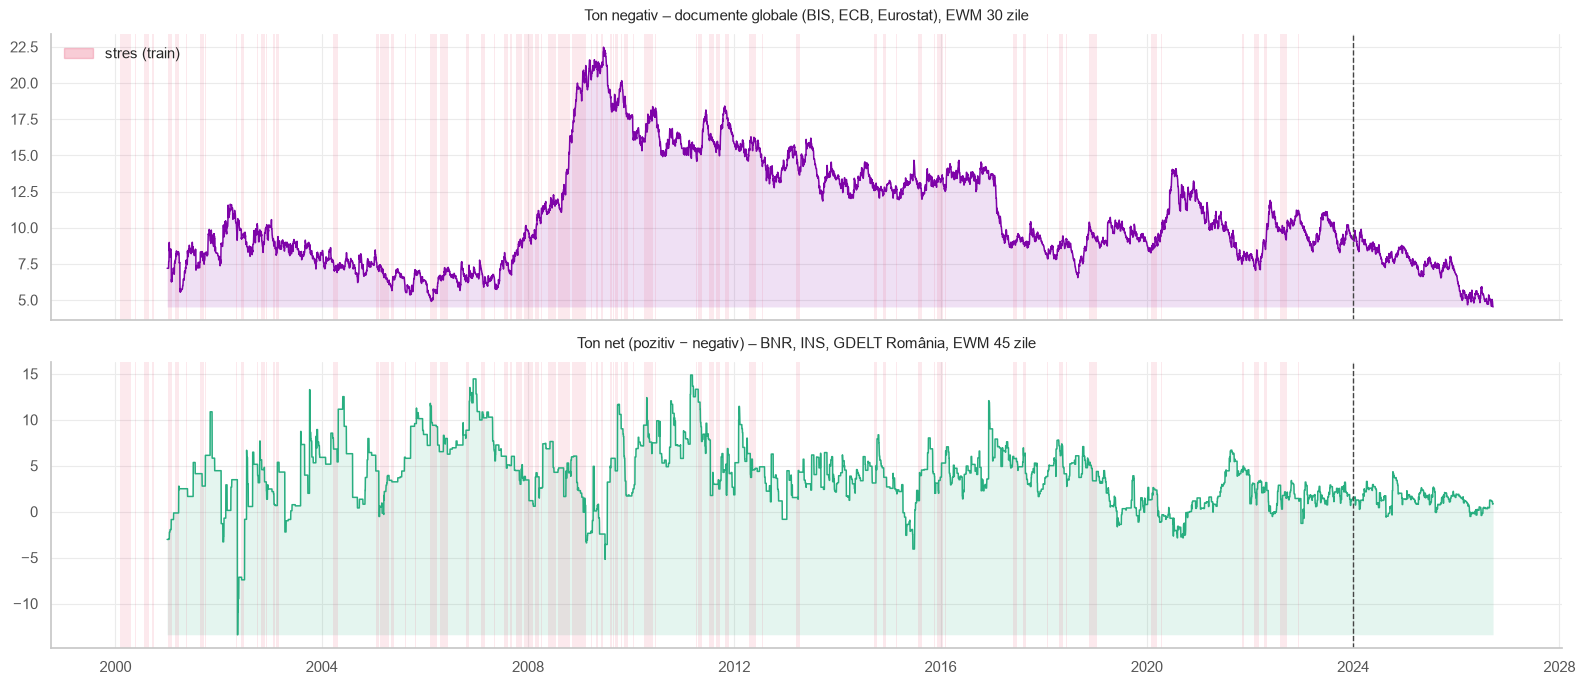

In [59]:
# Topicuri latente (LSA), învățate doar pe documentele din train. Modelul NU le folosește (au trend în timp).
mask_fit = (nlp['publication_date'] <= TRAIN_END).values
tf_eda = TfidfTransformer(sublinear_tf=True).fit(DTM[mask_fit])
svd_eda = TruncatedSVD(n_components=8, random_state=SEED).fit(tf_eda.transform(DTM)[mask_fit])
print('Cuvintele dominante ale fiecărui topic LSA:')
for k, comp in enumerate(svd_eda.components_):
    print(f"  topic_{k}: " + ', '.join(vocab[np.argsort(comp)[::-1][:9]]))

fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
for ax, (c, nume, col) in zip(axes, [('TXT_GLOBAL_lex_negativ_hl30', 'Ton negativ – documente globale (BIS, ECB, Eurostat), EWM 30 zile', SERII[3]),
                                     ('TXT_RO_lex_ton_net_hl45', 'Ton net (pozitiv − negativ) – BNR, INS, GDELT România, EWM 45 zile', SERII[1])]):
    linie(ax, F_text[c].loc['2001':], col, lw=1.1)
    umbreste_stres(ax, y_tr_cal)
    ax.axvline(TEST_START, color=C_TEXT, ls='--', lw=1)
    ax.set_title(nume, fontsize=11)
axes[0].legend(handles=[Patch(color=C_STRES, alpha=0.3, label='stres (train)')], loc='upper left')
plt.tight_layout(); plt.show()

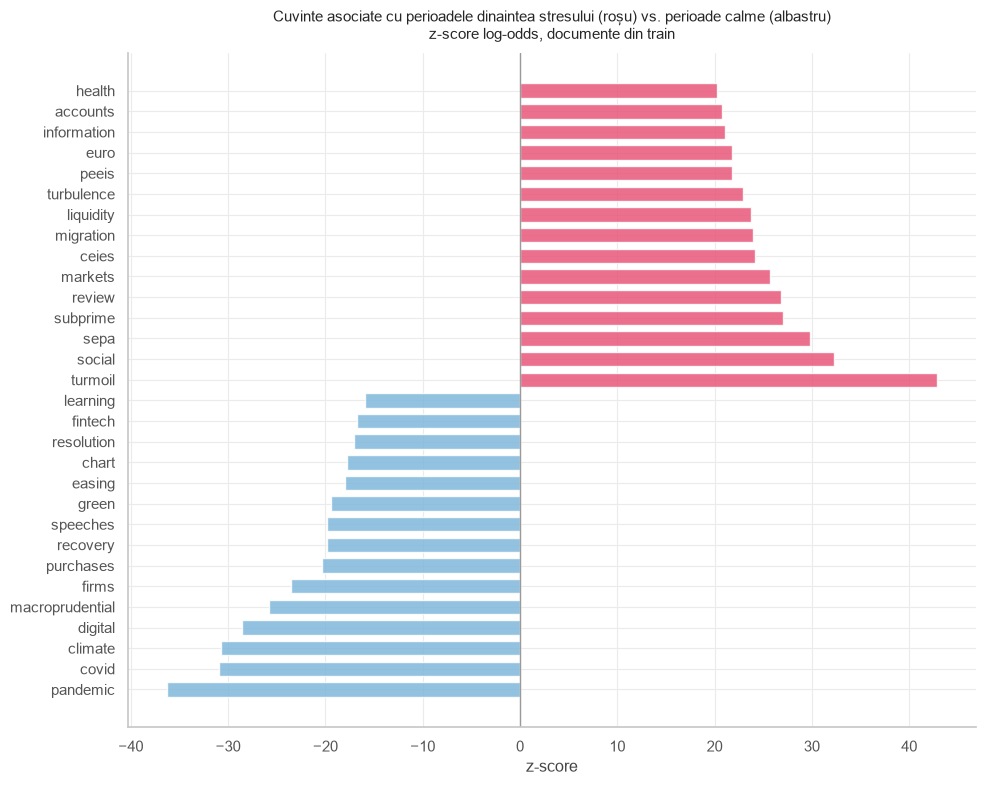

In [60]:
# Ce cuvinte apar mai des în documentele publicate ÎNAINTE de stres? (log-odds cu prior Dirichlet informativ, doar train)
eticheta_doc = y.reindex(nlp['publication_date'].dt.normalize()).values
cnt_s = np.asarray(DTM[(eticheta_doc == 1) & mask_fit].sum(axis=0)).ravel().astype(float)
cnt_c = np.asarray(DTM[(eticheta_doc == 0) & mask_fit].sum(axis=0)).ravel().astype(float)
prior = (cnt_s + cnt_c) / (cnt_s + cnt_c).sum() * 2000
a0 = prior.sum()
delta = (np.log((cnt_s + prior) / (cnt_s.sum() + a0 - cnt_s - prior)) - np.log((cnt_c + prior) / (cnt_c.sum() + a0 - cnt_c - prior)))
zscore_cuv = pd.Series(delta / np.sqrt(1 / (cnt_s + prior) + 1 / (cnt_c + prior)), index=vocab)
zscore_cuv = zscore_cuv[(cnt_s + cnt_c) > 300]
top_cuv = pd.concat([zscore_cuv.nsmallest(15), zscore_cuv.nlargest(15)])
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top_cuv.index, top_cuv.values, color=[C_NORMAL if v < 0 else C_STRES for v in top_cuv.values], height=0.7, alpha=0.85)
ax.axvline(0, color=C_GRI, lw=1)
ax.set_title('Cuvinte asociate cu perioadele dinaintea stresului (roșu) vs. perioade calme (albastru)\nz-score log-odds, documente din train', fontsize=11)
ax.set_xlabel('z-score')
plt.tight_layout(); plt.show()

Atenție la interpretare: multe cuvinte reflectă **perioada** (2008–2009, 2020 au vocabular specific), nu un semnal cauzal.

### 5.4 Asamblare + abateri față de ultimul an
Variabilele cu trend lent (corelație Spearman cu timpul > 0.5 în train) și tonul textelor primesc o versiune `_z365`:
abaterea față de media ultimelor 365 de zile, calculată doar din trecut.

In [61]:
def z_trecut(s, w=365):
    """Abaterea standardizată față de ultimele w zile (doar trecut)."""
    m = s.rolling(w, min_periods=int(w * 0.5)).mean()
    sd = s.rolling(w, min_periods=int(w * 0.5)).std()
    return (s - m) / sd.replace(0, np.nan)


X_baza = pd.concat([F_piata.reindex(cal.index).ffill(limit=4), F_geo_macro, F_text], axis=1)   # weekend = vineri
X_baza = X_baza.replace([np.inf, -np.inf], np.nan)

idx_train = y.loc[TRAIN_START:TRAIN_END].dropna().index
idx_test = test['Date'].values
y_train = y.loc[idx_train].astype(int)

X_baza_train = X_baza.loc[idx_train]
timp = pd.Series(np.arange(len(X_baza_train)), index=X_baza_train.index)
trend = pd.Series({c: X_baza_train[c].corr(timp, method='spearman')
                   for c in X_baza.columns if X_baza_train[c].nunique() > 5}).abs()
CU_TREND = [c for c in X_baza.columns if trend.get(c, 0) > 0.5 or (c.startswith('TXT_') and '_lex_' in c)]

X_cu_z = X_baza.copy()
for c in CU_TREND:
    X_cu_z[f'{c}_z365'] = z_trecut(X_baza[c]).clip(-6, 6)
X_cu_z = X_cu_z.replace([np.inf, -np.inf], np.nan)
X_train_toate = X_cu_z.loc[idx_train]
print(f"{X_cu_z.shape[1]} variabile construite, dintre care {len(CU_TREND)} versiuni _z365")

130 variabile construite, dintre care 22 versiuni _z365


### 📊 5.5 EDA pe variabilele construite
Pentru comparație includem și variabilele pe care modelul nu le folosește (din BET, niveluri, `GPRC_*`): le refacem aici,
separat, doar pentru grafice.

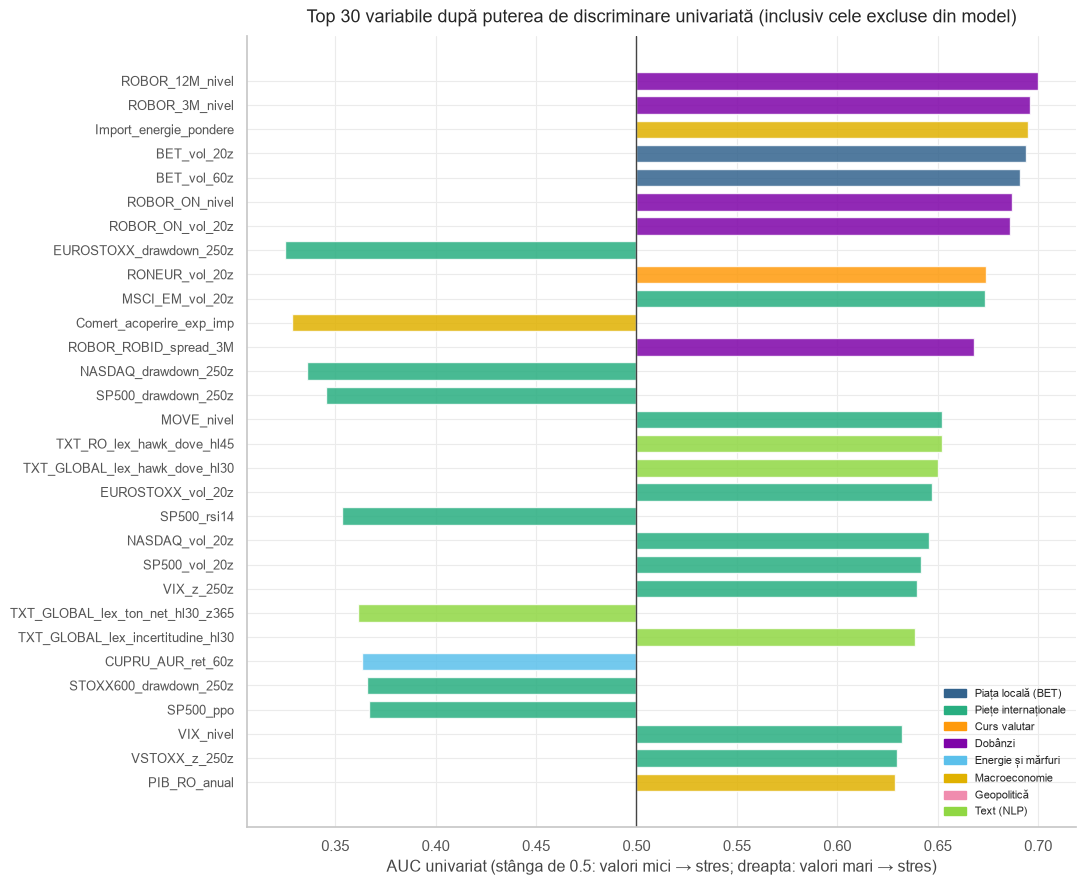

In [62]:
def variabile_doar_eda():
    "Variabilele din original pe care selecția le elimina sigur (BET, niveluri, GPRC) – doar pentru grafice."
    b = bet.reindex(cal.index).ffill(limit=5)
    b = b[b.index.dayofweek < 5]
    E = {f'BET_ret_{h}z': log_ret(b, h) for h in (1, 5, 20, 60)}
    E.update({'BET_vol_20z': vol(b, 20), 'BET_vol_60z': vol(b, 60), 'BET_vol_ratio_20_120': vol(b, 20) / vol(b, 120),
              'BET_drawdown_250z': dd(b, 250), 'BET_dist_ma200': b / b.rolling(200, min_periods=100).mean() - 1,
              'BET_dist_min20': b / b.rolling(20, min_periods=10).min() - 1,
              'BET_corr_STOXX_60z': np.log(b).diff().rolling(60, min_periods=40).corr(np.log(zl['STOXX600_Close']).diff())})
    for c, n in [('VIX_Close', 'VIX'), ('VSTOXX_Close', 'VSTOXX'), ('MOVE_Close', 'MOVE'),
                 ('ROBOR_ON', 'ROBOR_ON'), ('ROBOR_3M', 'ROBOR_3M'), ('ROBOR_12M', 'ROBOR_12M')]:
        E[f'{n}_nivel'] = zl[c]
    G = {'GPRC_medie_tari': cal[[c for c in cal.columns if c.startswith('GPRC_')]].mean(axis=1)}
    G.update({f'GPRC_{t}': cal[f'GPRC_{t}'] for t in ('RUS', 'UKR', 'HUN', 'POL', 'TUR', 'USA', 'DEU')})
    return pd.concat([pd.DataFrame(E).reindex(cal.index).ffill(limit=4), pd.DataFrame(G)], axis=1).replace([np.inf, -np.inf], np.nan)


X_eda = pd.concat([X_cu_z, variabile_doar_eda()], axis=1)
X_eda_train, X_eda_test = X_eda.loc[idx_train], X_eda.loc[idx_test]
CAT_EDA = {c: categorie_variabila(c) for c in X_eda.columns}

auc_uni = {}
for c in X_eda.columns:
    s = X_eda_train[c]; mm = s.notna()
    if mm.sum() > 500 and s[mm].nunique() > 5:
        auc_uni[c] = roc_auc_score(y_train[mm], s[mm])
auc_uni = pd.Series(auc_uni)
top_auc = auc_uni.reindex((auc_uni - 0.5).abs().sort_values(ascending=False).index[:30])

fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(range(len(top_auc)), top_auc.values - 0.5, left=0.5, color=[CULOARE_CAT[CAT_EDA[c]] for c in top_auc.index], height=0.72, alpha=0.85)
ax.set_yticks(range(len(top_auc))); ax.set_yticklabels(top_auc.index, fontsize=9); ax.invert_yaxis()
ax.axvline(0.5, color=C_TEXT, lw=1)
ax.set_xlabel('AUC univariat (stânga de 0.5: valori mici → stres; dreapta: valori mari → stres)')
ax.legend(handles=[Patch(color=CULOARE_CAT[k], label=k) for k in CATEGORII], loc='lower right', fontsize=8)
ax.set_title('Top 30 variabile după puterea de discriminare univariată (inclusiv cele excluse din model)')
plt.tight_layout(); plt.show()

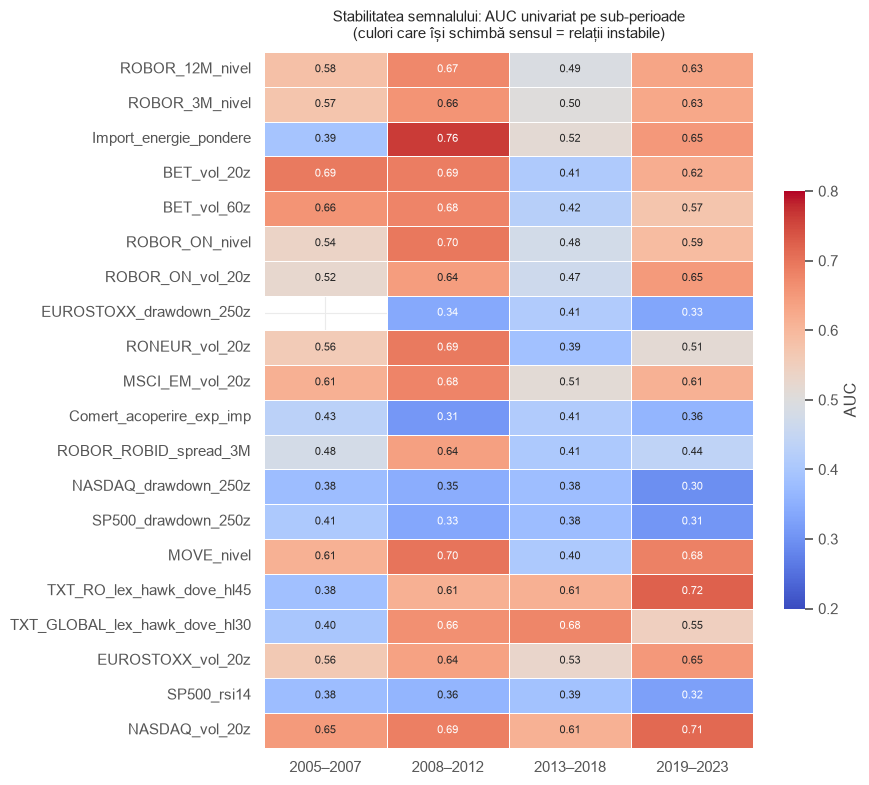

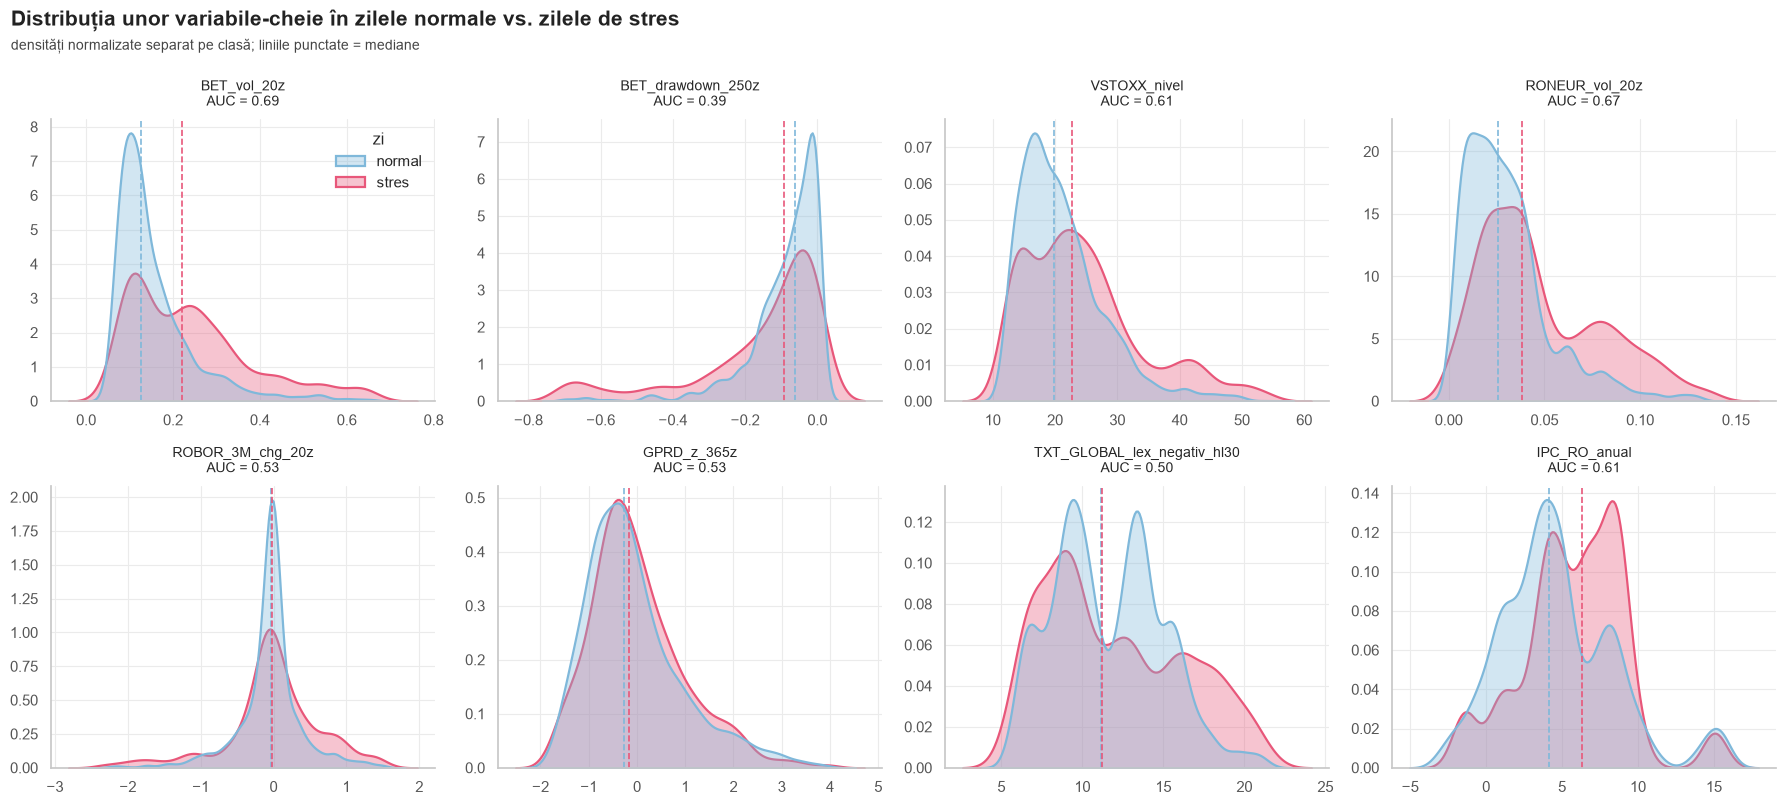

In [63]:
perioade = {'2005–2007': ('2005', '2007'), '2008–2012': ('2008', '2012'), '2013–2018': ('2013', '2018'), '2019–2023': ('2019', '2023')}
stab_top = pd.DataFrame({p_: {c: (roc_auc_score(y_train.loc[a:b][X_eda_train.loc[a:b, c].notna()], X_eda_train.loc[a:b, c].dropna())
                                  if X_eda_train.loc[a:b, c].notna().sum() > 200 and y_train.loc[a:b][X_eda_train.loc[a:b, c].notna()].nunique() == 2 else np.nan)
                              for c in top_auc.index[:20]} for p_, (a, b) in perioade.items()})
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(stab_top, cmap=CMAP_DIV, center=0.5, vmin=0.2, vmax=0.8, annot=True, fmt='.2f', annot_kws={'size': 8},
            linewidths=0.5, linecolor=SUPRAFATA, ax=ax, cbar_kws={'label': 'AUC', 'shrink': 0.6})
ax.set_title('Stabilitatea semnalului: AUC univariat pe sub-perioade\n(culori care își schimbă sensul = relații instabile)', fontsize=11)
plt.tight_layout(); plt.show()

alese = ['BET_vol_20z', 'BET_drawdown_250z', 'VSTOXX_nivel', 'RONEUR_vol_20z', 'ROBOR_3M_chg_20z', 'GPRD_z_365z', 'TXT_GLOBAL_lex_negativ_hl30', 'IPC_RO_anual']
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, c in zip(axes.flat, alese):
    dist = pd.DataFrame({'v': X_eda_train[c], 'zi': y_train.map({0: 'normal', 1: 'stres'})}).dropna()
    lo, hi = dist.v.quantile([0.01, 0.99])
    dist = dist[(dist.v >= lo) & (dist.v <= hi)]
    sns.kdeplot(data=dist, x='v', hue='zi', fill=True, common_norm=False, alpha=ALFA, palette=PALETA_Y,
                hue_order=['normal', 'stres'], linewidth=1.6, ax=ax, legend=(c == alese[0]))
    for eticheta, culoare in PALETA_Y.items():
        ax.axvline(dist.loc[dist.zi == eticheta, 'v'].median(), color=culoare, ls='--', lw=1.2)
    ax.set_title(f"{c}\nAUC = {auc_uni.get(c, np.nan):.2f}", fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
titlu(fig, 'Distribuția unor variabile-cheie în zilele normale vs. zilele de stres', 'densități normalizate separat pe clasă; liniile punctate = mediane')
plt.tight_layout(); plt.show()

**Event study:** aliniem debuturile de episoade (prima zi cu y=1 după cel puțin 60 de zile calme) și urmărim media variabilelor
standardizate. Un sistem de avertizare are nevoie de variabile care se mișcă **înainte** de ziua 0.

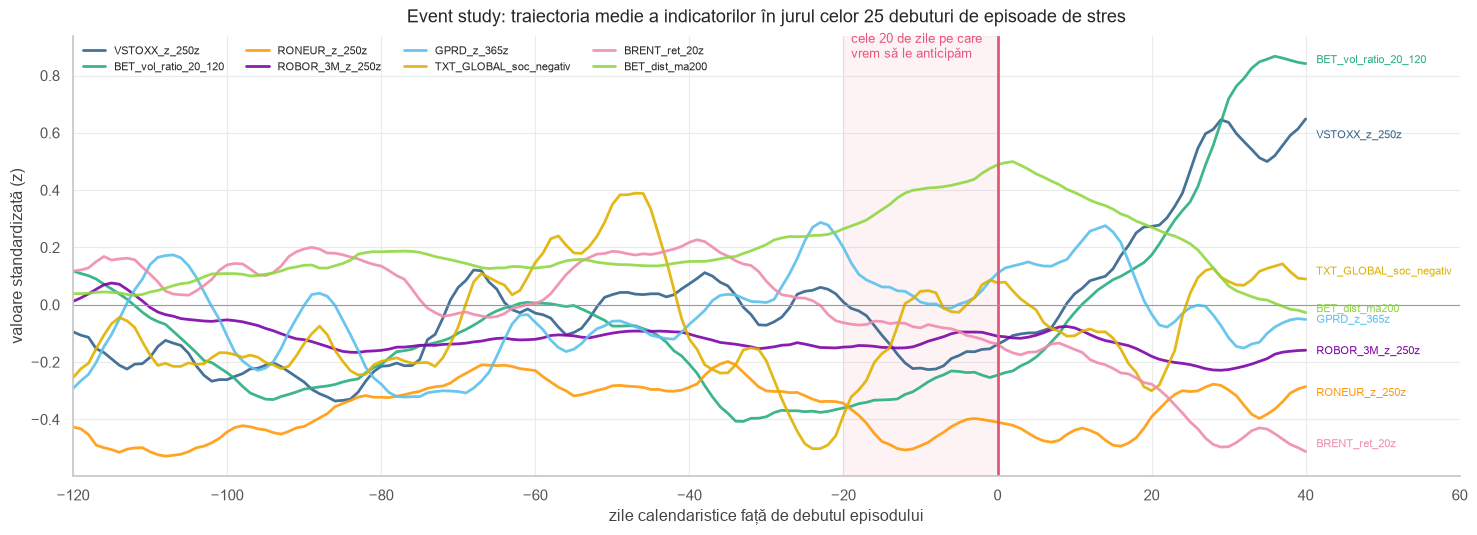

In [64]:
debut = y_train[(y_train == 1) & (y_train.shift(1) == 0) & (y_train.rolling(60).sum().shift(1) == 0)].index
debut = debut[debut.dayofweek < 5]
var_es = ['VSTOXX_z_250z', 'BET_vol_ratio_20_120', 'RONEUR_z_250z', 'ROBOR_3M_z_250z', 'GPRD_z_365z', 'TXT_GLOBAL_soc_negativ', 'BRENT_ret_20z', 'BET_dist_ma200']
Z_es = (X_eda_train[var_es] - X_eda_train[var_es].mean()) / X_eda_train[var_es].std()
traiect = pd.DataFrame({k: Z_es.reindex(debut + pd.Timedelta(days=k)).mean() for k in range(-120, 41)}).T

fig, ax = plt.subplots(figsize=(15, 5.5))
for i, c in enumerate(var_es):
    ax.plot(traiect.index, traiect[c].rolling(5, center=True, min_periods=1).mean(), color=SERII[i], lw=2, alpha=0.9, label=c)
    ax.text(41, traiect[c].iloc[-5:].mean(), ' ' + c, color=SERII[i], fontsize=8, va='center')
ax.axvline(0, color=C_STRES, lw=2); ax.axhline(0, color=C_GRI, lw=0.8)
ax.axvspan(-20, 0, color=C_STRES, alpha=0.07)
ax.text(-19, ax.get_ylim()[1] * 0.92, 'cele 20 de zile pe care\nvrem să le anticipăm', fontsize=9, color=C_STRES)
ax.set_xlim(-120, 60)
ax.set_xlabel('zile calendaristice față de debutul episodului'); ax.set_ylabel('valoare standardizată (z)')
ax.set_title(f'Event study: traiectoria medie a indicatorilor în jurul celor {len(debut)} debuturi de episoade de stres')
ax.legend(ncol=4, fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

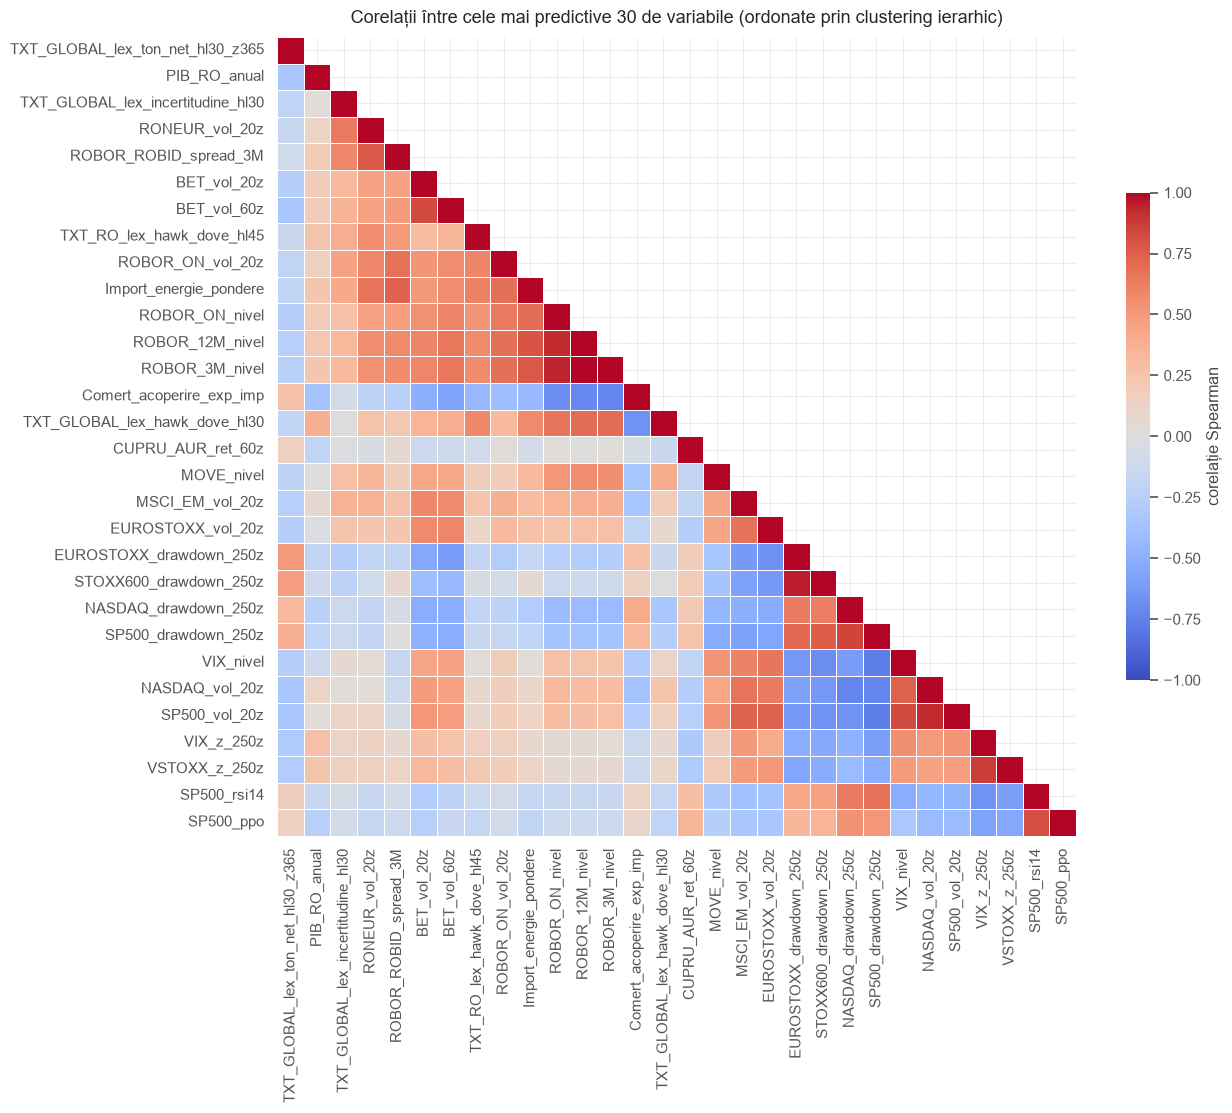

In [65]:
sel_top = top_auc.index[:30]
corr_top = X_eda_train[sel_top].corr(method='spearman')
ordine_c = leaves_list(linkage(1 - corr_top.abs().fillna(0).values[np.triu_indices(len(sel_top), 1)], 'average'))
corr_top = corr_top.iloc[ordine_c, ordine_c]
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr_top, mask=np.triu(np.ones_like(corr_top, dtype=bool), k=1), cmap=CMAP_DIV, center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.4, linecolor=SUPRAFATA, ax=ax, cbar_kws={'label': 'corelație Spearman', 'shrink': 0.6})
ax.set_title('Corelații între cele mai predictive 30 de variabile (ordonate prin clustering ierarhic)')
plt.tight_layout(); plt.show()

**Adversarial validation:** un clasificator încearcă să deosebească rândurile din train (2015–2023) de cele din test.
AUC ≈ 0.5 → distribuții similare; AUC ≈ 1 → testul arată altfel (de obicei din cauza variabilelor cu trend).

AUC adversarial train(2015–2023) vs test, toate variabilele: 1.000


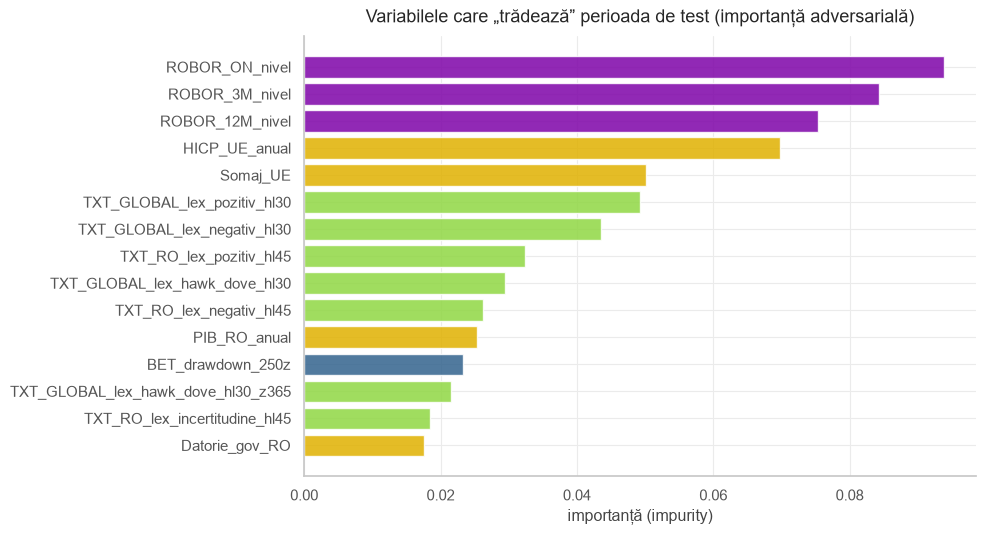

In [66]:
Xa = pd.concat([X_eda_train.loc['2015':], X_eda_test])
ya = np.r_[np.zeros(len(X_eda_train.loc['2015':])), np.ones(len(X_eda_test))]
Xa_imp = Xa.fillna(Xa.median())
et = ExtraTreesClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.3, n_jobs=-1, random_state=SEED)
p_adv = cross_val_predict(et, Xa_imp, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
imp_adv = pd.Series(et.fit(Xa_imp, ya).feature_importances_, index=Xa.columns).sort_values(ascending=False).head(15)
print(f"AUC adversarial train(2015–2023) vs test, toate variabilele: {roc_auc_score(ya, p_adv):.3f}")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(imp_adv.index[::-1], imp_adv.values[::-1], color=[CULOARE_CAT[CAT_EDA[c]] for c in imp_adv.index[::-1]], alpha=0.85)
ax.set_title('Variabilele care „trădează” perioada de test (importanță adversarială)'); ax.set_xlabel('importanță (impurity)')
plt.tight_layout(); plt.show()

## 6. Selecția variabilelor (doar pe train)
1. excludem nivelurile (au trend, „trădează” perioada) și originalele cu trend (înlocuite de `_z365`);
2. păstrăm doar variabilele al căror AUC are **același sens** în toate sub-perioadele (minimum 3) și efect mediu > 0.03;
3. din perechile cu |corelație Spearman| > 0.7 păstrăm varianta cu efect mai mare.

In [67]:
COLOANE_NIVEL = ['GPRD_log', 'GPRD_MA7', 'GPRD_MA30', 'IPC_RO_anual', 'HICP_UE_anual', 'INFL_diferential_RO_UE', 'Somaj_RO',
                 'Somaj_UE', 'PIB_RO_anual', 'PIB_RO_trim', 'Datorie_gov_RO', 'HPI_anual', 'GSCPI',
                 'Comert_acoperire_exp_imp', 'Import_energie_pondere']


def auc_subperioade(x, y_):
    """AUC − 0.5 pe fiecare sub-perioadă (NaN dacă sunt prea puține date sau o singură clasă)."""
    rez = []
    for a, b in SUBPERIOADE:
        s_, yy = x.loc[a:b], y_.loc[a:b]
        mm = s_.notna()
        rez.append(roc_auc_score(yy[mm], s_[mm]) - 0.5 if mm.sum() >= 200 and yy[mm].nunique() == 2 else np.nan)
    return rez


auc_sub = pd.DataFrame({c: auc_subperioade(X_train_toate[c], y_train) for c in X_train_toate.columns},
                       index=[f'{a}–{b}' for a, b in SUBPERIOADE]).T
acelasi_semn = auc_sub.fillna(0).ge(0).all(axis=1) | auc_sub.fillna(0).le(0).all(axis=1)
efect_mediu = auc_sub.abs().mean(axis=1)
este_nivel = pd.Series(auc_sub.index.isin(COLOANE_NIVEL), index=auc_sub.index)
are_trend = pd.Series(auc_sub.index.isin(CU_TREND), index=auc_sub.index)
selectat = ~este_nivel & ~are_trend & (auc_sub.notna().sum(axis=1) >= 3) & acelasi_semn & (efect_mediu > 0.03)
FEATURES_STABILE = list(auc_sub.index[selectat])

# Filtrul de corelație: greedy, în ordinea efectului (cea mai puternică variabilă dintr-un grup rămâne)
corr_abs = X_train_toate[FEATURES_STABILE].corr(method='spearman').abs()
pastrate = []
for c in efect_mediu.loc[FEATURES_STABILE].sort_values(ascending=False).index:
    if c in SCOATE_MANUAL:
        continue
    if not any(corr_abs.loc[c, k] > PRAG_CORR for k in pastrate):
        pastrate.append(c)
FEATURES = [c for c in FEATURES_STABILE if c in pastrate]   # ordinea coloanelor contează pentru LightGBM

X_train = X_train_toate[FEATURES]
X_test = X_cu_z.loc[idx_test, FEATURES]
print(f"Variabile în model: {len(FEATURES)}")

Variabile în model: 25


### 📊 6.1 Ce a rămas după selecție

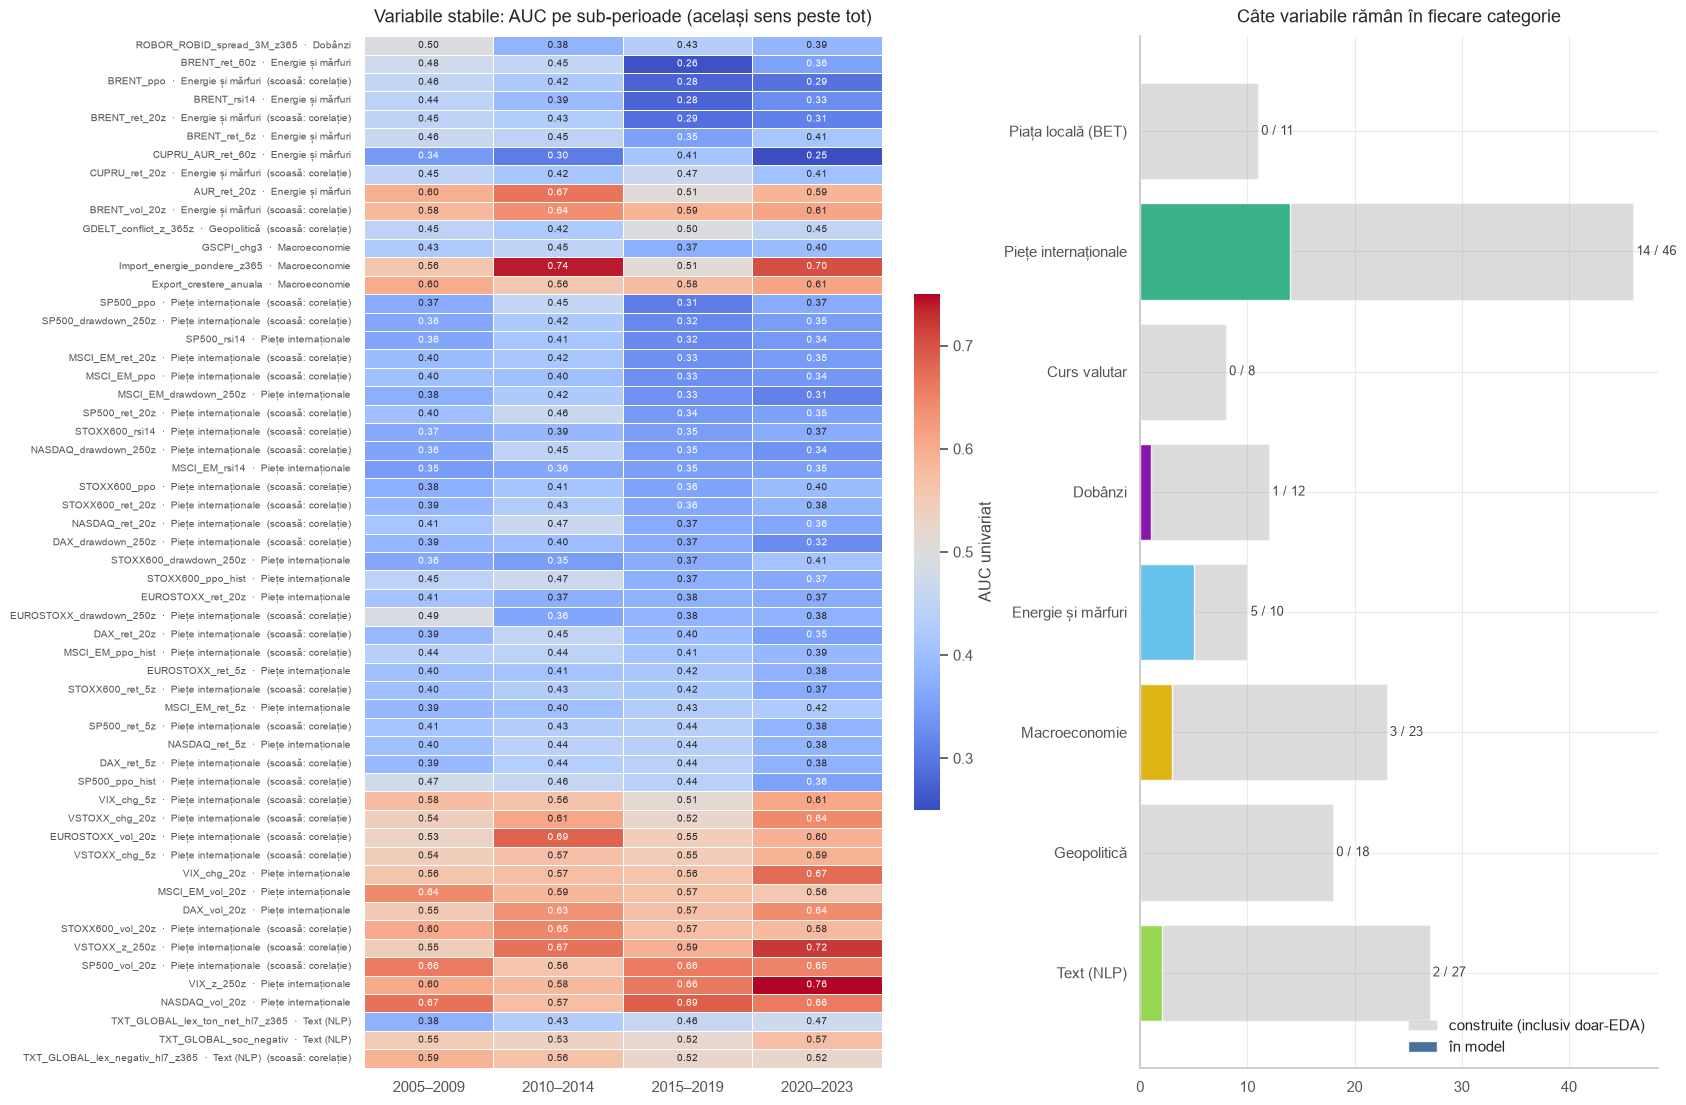

,redundantă_cu
variabilă_scoasă,
EUROSTOXX_vol_20z,DAX_vol_20z
EUROSTOXX_drawdown_250z,STOXX600_drawdown_250z
STOXX600_ret_5z,EUROSTOXX_ret_5z
STOXX600_ret_20z,EUROSTOXX_ret_20z
STOXX600_vol_20z,DAX_vol_20z
DAX_ret_5z,EUROSTOXX_ret_5z
DAX_ret_20z,EUROSTOXX_ret_20z
DAX_drawdown_250z,STOXX600_drawdown_250z
SP500_ret_5z,NASDAQ_ret_5z


AUC adversarial: toate variabilele 1.000 -> variabile stabile 1.000


In [68]:
fig, axes = plt.subplots(1, 2, figsize=(17, max(11, 0.2 * len(FEATURES_STABILE))), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
h_sel = auc_sub.loc[FEATURES_STABILE].copy()
h_sel['cat'] = [CAT_EDA[c] for c in h_sel.index]
h_sel = h_sel.sort_values(['cat', '2015–2019'])
sns.heatmap(h_sel.iloc[:, :4] + 0.5, cmap=CMAP_DIV, center=0.5, vmin=0.25, vmax=0.75, annot=True, fmt='.2f', annot_kws={'size': 7},
            linewidths=0.4, linecolor='white', ax=ax, yticklabels=True, cbar_kws={'label': 'AUC univariat', 'shrink': 0.5})
ax.set_yticklabels([f"{c}  ·  {CAT_EDA[c]}{'' if c in FEATURES else '  (scoasă: corelație)'}" for c in h_sel.index], fontsize=7.5)
ax.set_title('Variabile stabile: AUC pe sub-perioade (același sens peste tot)')
ax = axes[1]
tab = pd.DataFrame({'construite': pd.Series(CAT_EDA).value_counts(),
                    'în model': pd.Series({c: CAT_EDA[c] for c in FEATURES}).value_counts()}).reindex(CATEGORII).fillna(0)
y_pos = np.arange(len(tab))
ax.barh(y_pos, tab['construite'], color=C_GRI, alpha=0.35, label='construite (inclusiv doar-EDA)')
ax.barh(y_pos, tab['în model'], color=[CULOARE_CAT[c] for c in tab.index], alpha=0.9, label='în model')
ax.set_yticks(y_pos); ax.set_yticklabels(tab.index); ax.invert_yaxis()
for i, (t_tot, t_sel) in enumerate(zip(tab['construite'], tab['în model'])):
    ax.text(t_tot + 0.3, i, f'{int(t_sel)} / {int(t_tot)}', va='center', fontsize=9, color=C_TEXT)
ax.legend(loc='lower right'); ax.set_title('Câte variabile rămân în fiecare categorie')
plt.tight_layout(); plt.show()

scoase_corr = {c: ('manual' if c in SCOATE_MANUAL else max(FEATURES, key=lambda k: corr_abs.loc[c, k]))
               for c in FEATURES_STABILE if c not in FEATURES}
display(pd.DataFrame({'redundantă_cu': scoase_corr}).rename_axis('variabilă_scoasă'))

p_adv_sel = cross_val_predict(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.3, n_jobs=-1, random_state=SEED),
                              Xa_imp[FEATURES_STABILE], ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
print(f"AUC adversarial: toate variabilele {roc_auc_score(ya, p_adv):.3f} -> variabile stabile {roc_auc_score(ya, p_adv_sel):.3f}")

## 7. Validare și modele
* **walk-forward**: pentru fiecare an antrenăm pe tot ce e înainte, cu o pauză de `GAP_ZILE`;
* trei modele de bază: regresie logistică, gradient boosting (LightGBM), model de supraviețuire în timp discret (hazard).

In [69]:
def scor_datasprint(y_true, y_prob, prag, rata_baseline=HISTORICAL_STRESS_RATE):
    """Replica metricii oficiale: 0.625·F2 + 0.25·AUC + 0.125·BSS."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.clip(np.asarray(y_prob, dtype=float), 0, 1)
    f2 = fbeta_score(y_true, (y_prob >= prag).astype(int), beta=2, zero_division=0)
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
    brier = np.mean((y_prob - y_true) ** 2)
    brier_base = np.mean((rata_baseline - y_true) ** 2)
    bss = 1 - brier / brier_base
    return 0.625 * f2 + 0.25 * auc + 0.125 * bss


def prag_optim_f2(y_true, y_prob, grila=np.linspace(0.02, 0.8, 157)):
    """Pragul care maximizează F2."""
    y_true = np.asarray(y_true).astype(int)
    f2s = np.array([fbeta_score(y_true, (y_prob >= p).astype(int), beta=2, zero_division=0) for p in grila])
    return grila[int(np.argmax(f2s))]


def scor_oof(oof, y_):
    """Scorul oficial pe predicții out-of-fold, cu pragul F2 ales pe aceleași date."""
    m = oof.notna()
    return scor_datasprint(y_[m], oof[m], prag_optim_f2(y_[m], oof[m]))


def fold_uri(index, ani, gap=GAP_ZILE):
    """Pentru fiecare an: (an, poziții train cu pauză de `gap` zile, poziții validare)."""
    for an in ani:
        start, final = pd.Timestamp(f'{an}-01-01'), pd.Timestamp(f'{an}-12-31')
        tr = np.where(index < start - pd.Timedelta(days=gap))[0]
        va = np.where((index >= start) & (index <= final))[0]
        if len(va):
            yield an, tr, va


def clip5(X):
    return np.clip(X, -5, 5)


def model_logistic(C):
    """Imputare cu mediana (învățată pe fold) + standardizare + tăiere outlieri + L2."""
    return make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler(), FunctionTransformer(clip5),
                         LogisticRegression(C=C, max_iter=3000))


class EliminaColoaneGoale:
    """Elimină coloanele aproape goale în fold-ul de antrenare (HistGradientBoosting nu le acceptă; LightGBM da)."""
    def fit(self, X, y=None):
        self.pastreaza_ = (~np.isnan(np.asarray(X, dtype=float))).sum(axis=0) >= 20
        return self
    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.pastreaza_]
    def fit_transform(self, X, y=None):
        return self.fit(X).transform(X)
    def get_params(self, deep=True):
        return {}
    def set_params(self, **p):
        return self


def model_gbm(params=None, seed=SEED):
    """LightGBM cu parametrii dați (sau HistGradientBoosting dacă LightGBM lipsește)."""
    p = dict(GBM_IMPLICIT); p.update(params or {})
    if HAS_LGB:
        return lgb.LGBMClassifier(n_estimators=int(p['n_estimators']), learning_rate=p['learning_rate'], num_leaves=int(p['num_leaves']),
                                  min_child_samples=int(p['min_child_samples']), reg_lambda=p['reg_lambda'],
                                  colsample_bytree=p['colsample_bytree'], subsample=p['subsample'], subsample_freq=1,
                                  random_state=seed, verbose=-1, n_jobs=-1)
    kw = dict(max_iter=int(p['n_estimators']), learning_rate=p['learning_rate'], max_leaf_nodes=int(p['num_leaves']),
              min_samples_leaf=int(p['min_child_samples']), l2_regularization=p['reg_lambda'], early_stopping=False, random_state=seed)
    try:
        hgb = HistGradientBoostingClassifier(max_features=p['colsample_bytree'], **kw)   # sklearn >= 1.4
    except TypeError:
        hgb = HistGradientBoostingClassifier(**kw)
    return make_pipeline(EliminaColoaneGoale(), hgb)

### Modelul de supraviețuire (hazard discret)
`T` = în a câta zi de tranzacționare (1–20) apare prima scădere ≥5% (21 = nu apare). Modelul estimează riscul zilnic
$h_k$ și îl transformă în $P(T \le 20) = 1 - \prod_{k=1}^{20}(1-h_k)$.

In [70]:
def timp_pana_la_stres(bet, prag=-0.05, orizont=20):
    """Ziua primei scăderi ≥5% în următoarele `orizont` zile de tranzacționare (orizont+1 = deloc; NaN = fereastră incompletă)."""
    viit = np.column_stack([bet.shift(-h).values / bet.values - 1 for h in range(1, orizont + 1)])
    atinge = viit <= prag
    T = pd.Series(np.where(atinge.any(axis=1), atinge.argmax(axis=1) + 1, orizont + 1), index=bet.index).astype(float)
    T[bet.shift(-orizont).isna()] = np.nan
    return T


class ModelHazardDiscret:
    """Regresie logistică pe date „zi × orizont”, cu hazard de bază pe grupuri de orizont.
    Indicatorii de orizont sunt înmulțiți cu SCALA_BAZA ca penalizarea L2 să nu-i strivească (altfel P(T<=20) -> 1)."""
    GRUPURI = [(1, 2), (3, 5), (6, 10), (11, 15), (16, 20)]
    SCALA_BAZA = 30.0

    def __init__(self, C=0.05, orizont=20):
        self.C, self.H = C, orizont

    def _baza_k(self, k):
        return self.SCALA_BAZA * np.array([[1.0 if a <= kk <= b else 0.0 for (a, b) in self.GRUPURI[1:]] for kk in k])

    def fit(self, X, T):
        ok = T.notna().values
        X, T = X[ok], T[ok].values
        self.prep = make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler(), FunctionTransformer(clip5)).fit(X)
        Z = self.prep.transform(X)
        durata = np.minimum(T, self.H).astype(int)               # câte zile „la risc” are fiecare observație
        rand = np.repeat(np.arange(len(Z)), durata)
        k = np.concatenate([np.arange(1, d + 1) for d in durata])
        eveniment = (k == T[rand]).astype(int)
        Zpp = np.hstack([Z[rand], self._baza_k(k)])
        self.lr = LogisticRegression(C=self.C, max_iter=5000).fit(Zpp, eveniment)
        return self

    def hazard(self, X):
        Z = self.prep.transform(X)
        beta, alfa = self.lr.coef_[0][:Z.shape[1]], self.lr.coef_[0][Z.shape[1]:]
        eta = Z @ beta + self.lr.intercept_[0]
        B = self._baza_k(np.arange(1, self.H + 1))
        return 1 / (1 + np.exp(-(eta[:, None] + (B @ alfa)[None, :])))

    def predict_proba(self, X):
        p = (1 - np.cumprod(1 - self.hazard(X), axis=1))[:, -1]
        return np.column_stack([1 - p, p])


T_train = timp_pana_la_stres(bet).reindex(X_train.index)   # NaN în weekend -> hazardul se antrenează pe zile de bursă


def oof_predictii(fabrica, ani=ANI_OOF, hazard=False, exclude=ANI_EXCLUSI_TRAIN):
    """Walk-forward: predicții out-of-fold (NaN în afara anilor de validare)."""
    oof = pd.Series(np.nan, index=X_train.index)
    for an, tr, va in fold_uri(X_train.index, ani):
        tr = tr[~X_train.index[tr].year.isin(list(exclude))]
        model = fabrica()
        model.fit(X_train.iloc[tr], T_train.iloc[tr] if hazard else y_train.iloc[tr])
        oof.iloc[va] = model.predict_proba(X_train.iloc[va])[:, 1]
    return oof

### 📊 7.1 Schema de validare și structura la termen a riscului

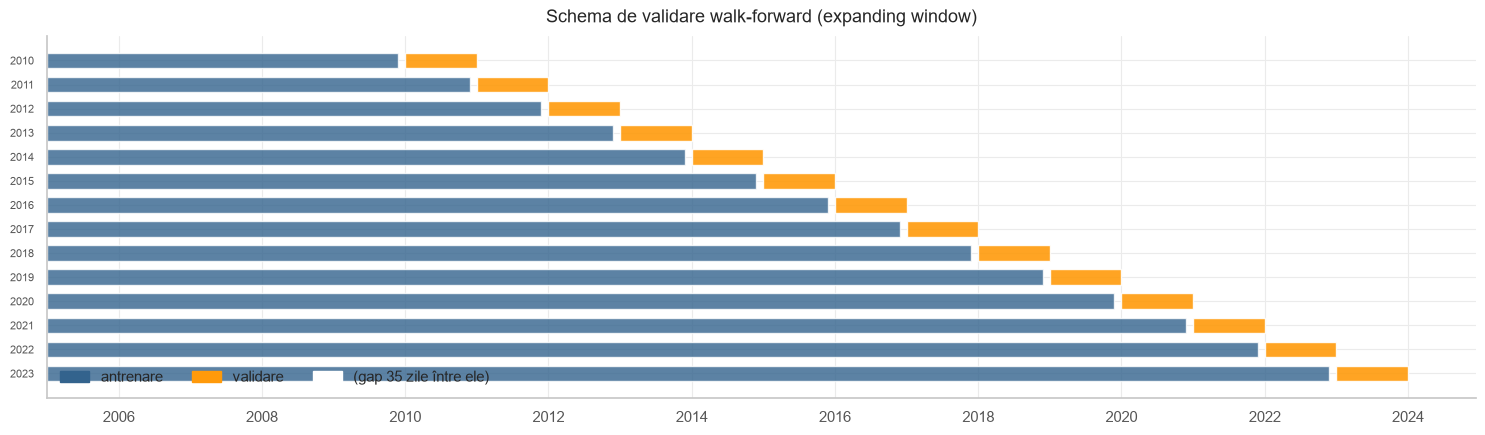

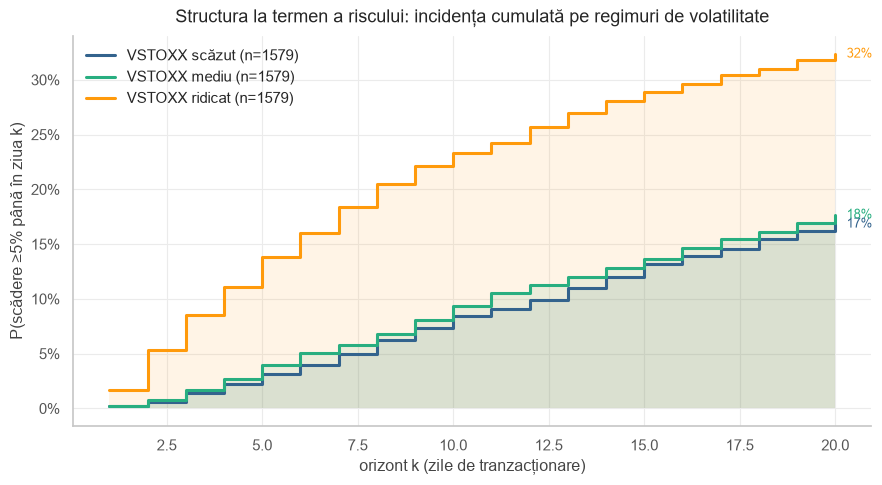

In [71]:
fig, ax = plt.subplots(figsize=(15, 4.5))
for i, (an, tr, va) in enumerate(fold_uri(X_train.index, ANI_OOF)):
    ax.barh(i, (X_train.index[tr[-1]] - X_train.index[0]).days, left=mdates.date2num(X_train.index[0]), color=SERII[0], height=0.65, alpha=0.8)
    ax.barh(i, (X_train.index[va[-1]] - X_train.index[va[0]]).days, left=mdates.date2num(X_train.index[va[0]]), color=SERII[2], height=0.65, alpha=0.9)
ax.xaxis_date(); ax.set_yticks(range(len(ANI_OOF))); ax.set_yticklabels(ANI_OOF, fontsize=8); ax.invert_yaxis()
ax.legend(handles=[Patch(color=SERII[0], label='antrenare'), Patch(color=SERII[2], label='validare'),
                   Patch(color=SUPRAFATA, label=f'(gap {GAP_ZILE} zile între ele)')], loc='lower left', ncol=3)
ax.set_title('Schema de validare walk-forward (expanding window)')
plt.tight_layout(); plt.show()

# Incidența cumulată P(T <= k) pe regimuri de volatilitate (cenzurare doar la 20 de zile -> frecvențe empirice)
regim = pd.qcut(X_eda_train['VSTOXX_nivel'].where(T_train.notna()), 3, labels=['VSTOXX scăzut', 'VSTOXX mediu', 'VSTOXX ridicat'])
fig, ax = plt.subplots(figsize=(9, 5))
for i, (r_nume, Tg) in enumerate(T_train.groupby(regim, observed=True)):
    cum = [(Tg <= k).mean() for k in range(1, 21)]
    ax.step(range(1, 21), cum, where='post', color=SERII[i], lw=2.2, label=f'{r_nume} (n={len(Tg)})')
    ax.fill_between(range(1, 21), cum, step='post', color=SERII[i], alpha=0.10, lw=0)
    ax.text(20.3, cum[-1], f'{cum[-1]:.0%}', color=SERII[i], va='center', fontsize=9)
ax.set_xlabel('orizont k (zile de tranzacționare)'); ax.set_ylabel('P(scădere ≥5% până în ziua k)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Structura la termen a riscului: incidența cumulată pe regimuri de volatilitate'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

## 8. Tuning de hiperparametri
LightGBM: log-loss mediu pe 2015–2022 (Optuna TPE, sau random search dacă Optuna lipsește).
Regresia logistică (și hazardul): `C` ales după log-loss pe aceiași ani.

In [72]:
def logloss_gbm(params):
    """Log-loss mediu walk-forward pe ANI_TUNING pentru un set de hiperparametri LightGBM."""
    pierderi = []
    for an, tr, va in fold_uri(X_train.index, ANI_TUNING):
        m = model_gbm(params).fit(X_train.iloc[tr], y_train.iloc[tr])
        p = np.clip(m.predict_proba(X_train.iloc[va])[:, 1], 1e-4, 1 - 1e-4)
        pierderi.append(log_loss(y_train.iloc[va], p, labels=[0, 1]))
    return float(np.mean(pierderi))


def spatiu_optuna(trial):
    # ordinea apelurilor suggest_* contează pentru reproductibilitatea TPE
    return dict(n_estimators=trial.suggest_int('n_estimators', 100, 600, step=50),
                learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
                num_leaves=trial.suggest_int('num_leaves', 4, 48),
                min_child_samples=trial.suggest_int('min_child_samples', 20, 400, log=True),
                reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 30, log=True),
                colsample_bytree=trial.suggest_float('colsample_bytree', 0.2, 1.0),
                subsample=trial.suggest_float('subsample', 0.5, 1.0))


def spatiu_aleator(rng):
    return dict(n_estimators=int(rng.choice(np.arange(100, 650, 50))), learning_rate=float(np.exp(rng.uniform(np.log(0.01), np.log(0.1)))),
                num_leaves=int(rng.integers(4, 49)), min_child_samples=int(np.exp(rng.uniform(np.log(20), np.log(400)))),
                reg_lambda=float(np.exp(rng.uniform(np.log(1e-3), np.log(30)))), colsample_bytree=float(rng.uniform(0.2, 1.0)),
                subsample=float(rng.uniform(0.5, 1.0)))


if HAS_OPTUNA:
    studiu = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    studiu.enqueue_trial(GBM_IMPLICIT)
    studiu.optimize(lambda tr: logloss_gbm(spatiu_optuna(tr)), n_trials=N_TRIALS_OPTUNA)
    BEST_GBM = dict(GBM_IMPLICIT); BEST_GBM.update(studiu.best_params)
else:
    rng = np.random.default_rng(SEED)
    cel_mai_bun, BEST_GBM = logloss_gbm(GBM_IMPLICIT), dict(GBM_IMPLICIT)
    for _ in range(N_TRIALS_ALEATOR):
        p = spatiu_aleator(rng)
        v = logloss_gbm(p)
        if v < cel_mai_bun:
            cel_mai_bun, BEST_GBM = v, p

logloss_C = {}
for C_ in GRILA_C_LOGISTIC:
    o = oof_predictii(lambda: model_logistic(C=C_), ani=ANI_TUNING, exclude=())
    m = o.notna()
    logloss_C[C_] = log_loss(y_train[m], np.clip(o[m], 1e-4, 1 - 1e-4))
LR_C = min(logloss_C, key=logloss_C.get)
print('LightGBM:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in BEST_GBM.items()}, '| C logistic/hazard:', LR_C)

LightGBM: {'n_estimators': 300, 'learning_rate': 0.0133, 'num_leaves': 24, 'min_child_samples': 31, 'reg_lambda': 21.2583, 'colsample_bytree': 0.569, 'subsample': 0.7679} | C logistic/hazard: 0.001


## 9. Predicții out-of-fold, ansambluri și alegerea modelului
Comparăm pe 2013–2023: LightGBM singur, media celor trei modele, media rangurilor recalibrată izotonic și stacking.
Câștigă cel cu scorul oficial cel mai mare pe validarea în timp.

In [73]:
logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))

OOF = pd.DataFrame(index=X_train.index)
OOF['gbm_tuned'] = oof_predictii(lambda: model_gbm(BEST_GBM))
OOF['logistic'] = oof_predictii(lambda: model_logistic(C=LR_C))
OOF['hazard'] = oof_predictii(lambda: ModelHazardDiscret(C=LR_C), hazard=True)
OOF['medie'] = OOF[BAZA].mean(axis=1)
OOF['rank_avg'] = OOF[BAZA].rank(pct=True).mean(axis=1)

# Stacking și recalibrarea rangurilor, tot walk-forward (meta-modelul vede doar anii anteriori)
OOF['stacking'] = np.nan
OOF['rank_avg_cal'] = np.nan
for an in ANI_META:
    limita = pd.Timestamp(f'{an}-01-01') - pd.Timedelta(days=GAP_ZILE)
    m_va = OOF.index.year == an
    m_tr = (OOF.index < limita) & OOF[BAZA].notna().all(axis=1) & ~OOF.index.year.isin(ANI_EXCLUSI_TRAIN)
    meta = LogisticRegression(C=1.0).fit(logit(OOF.loc[m_tr, BAZA]), y_train[m_tr])
    OOF.loc[m_va, 'stacking'] = meta.predict_proba(logit(OOF.loc[m_va, BAZA]))[:, 1]
    m_tr = (OOF.index < limita) & OOF['rank_avg'].notna()
    iso = IsotonicRegression(out_of_bounds='clip', y_min=0.005, y_max=0.995).fit(OOF.loc[m_tr, 'rank_avg'], y_train[m_tr])
    OOF.loc[m_va, 'rank_avg_cal'] = iso.predict(OOF.loc[m_va, 'rank_avg'])

m_comun = OOF.index.year >= 2013
scoruri = pd.Series({c: scor_oof(OOF.loc[m_comun, c], y_train[m_comun]) for c in CANDIDATI})
MODEL_FINAL = scoruri.idxmax()
print(scoruri.round(4).to_string(), '\nModel final:', MODEL_FINAL)

gbm_tuned       0.4289
medie           0.4592
rank_avg_cal    0.4454
stacking        0.4648 
Model final: stacking


## 10. Antrenarea finală și predicția pe test

In [74]:
M_FIN = ~X_train.index.year.isin(ANI_EXCLUSI_TRAIN)
P_TEST = pd.DataFrame(index=X_test.index)
lr_final = model_logistic(C=LR_C).fit(X_train[M_FIN], y_train[M_FIN])
P_TEST['logistic'] = lr_final.predict_proba(X_test)[:, 1]
gbm_finale = [model_gbm(BEST_GBM, seed=s).fit(X_train[M_FIN], y_train[M_FIN]) for s in SEEDURI_GBM_FINAL]
P_TEST['gbm_tuned'] = np.mean([m.predict_proba(X_test)[:, 1] for m in gbm_finale], axis=0)
hz_final = ModelHazardDiscret(C=LR_C).fit(X_train[M_FIN], T_train[M_FIN])
P_TEST['hazard'] = hz_final.predict_proba(X_test)[:, 1]

m_meta = OOF[BAZA].notna().all(axis=1)
m_meta_st = m_meta & ~OOF.index.year.isin(ANI_EXCLUSI_TRAIN)
meta_final = LogisticRegression(C=1.0).fit(logit(OOF.loc[m_meta_st, BAZA]), y_train[m_meta_st])
P_TEST['stacking'] = meta_final.predict_proba(logit(P_TEST[BAZA]))[:, 1]
P_TEST['medie'] = P_TEST[BAZA].mean(axis=1)
# Rangul unei predicții de test = poziția ei în distribuția OOF a aceluiași model, apoi recalibrare izotonică
OOF_SORTAT = {c: np.sort(OOF.loc[m_meta, c].values) for c in BAZA}
iso_final = IsotonicRegression(out_of_bounds='clip', y_min=0.005, y_max=0.995).fit(OOF.loc[m_meta, BAZA].rank(pct=True).mean(axis=1), y_train[m_meta])
rang_test = np.column_stack([np.searchsorted(OOF_SORTAT[c], P_TEST[c].values) / m_meta.sum() for c in BAZA]).mean(axis=1)
P_TEST['rank_avg_cal'] = iso_final.predict(rang_test)
p_brut = P_TEST[MODEL_FINAL].copy()

## 11. Stratul de decizie

### 11.1 Alertă cu confirmare și histerezis 
Alerta pornește după 2 zile lucrătoare consecutive peste prag și se oprește după 3 zile sub prag. Pragul se alege pe OOF.

In [75]:
def stare_alerta(p, prag, k=ZILE_CONFIRMARE, m=ZILE_IESIRE):
    """Starea de alertă pe zilele lucrătoare (doar trecut); weekendul preia starea de vineri."""
    z = p[p.index.dayofweek < 5]
    activ, sus, jos, st = [], 0, 0, False
    for v in (z >= prag).values:
        sus, jos = (sus + 1, 0) if v else (0, jos + 1)
        if not st and sus >= k:
            st = True
        elif st and jos >= m:
            st = False
        activ.append(st)
    return pd.Series(activ, index=z.index).reindex(p.index).ffill().fillna(False).astype(bool)


def aplica_regula(p, prag):
    """În alertă probabilitatea urcă cel puțin la prag; în afara alertei coboară sub prag."""
    s = stare_alerta(p, prag)
    return pd.Series(np.where(s, np.maximum(p, prag), np.minimum(p, prag - 0.001)), index=p.index)


p_oof, y_oof = OOF.loc[m_comun, MODEL_FINAL], y_train[m_comun]
scor_prag = {t: scor_datasprint(y_oof, aplica_regula(p_oof, t), t) for t in GRILA_PRAG}
PRAG_REGULA = max(scor_prag, key=scor_prag.get)
p_regula = aplica_regula(p_brut, PRAG_REGULA)

### 11.2 Mai puține alerte: 44% → 38% din zile 

In [ ]:
def prag_la_procent(procent, set_ref):
    """Bisecție: pragul la care setul de alertă (intersectat cu set_ref) acoperă `procent` din zile."""
    lo_, hi_ = float(PRAG_REGULA), float(p_brut.max())
    for _ in range(50):
        mid = (lo_ + hi_) / 2
        lo_, hi_ = (lo_, mid) if (stare_alerta(p_brut, mid) & set_ref).mean() < procent else (mid, hi_)
    return (lo_ + hi_) / 2


def muta_minim(p, set_alerta, prag):
    """Mută doar zilele aflate pe partea greșită a pragului, imediat peste/sub el, păstrând ordinea."""
    q = p.copy()
    sus_ = set_alerta & (q < prag);  q[sus_] = prag + E_MUTARE * (1 + q[sus_])
    jos_ = ~set_alerta & (q >= prag); q[jos_] = prag - E_MUTARE * (2 - q[jos_])
    return q


set_regula = p_regula >= PRAG_REGULA
p_scara, set_prev, seturi_scara = p_regula.copy(), set_regula, {}
for proc in SCARA:
    t_ = prag_la_procent(proc, set_regula)
    s_ = stare_alerta(p_brut, t_) & set_prev
    seturi_scara[proc] = (t_, s_)
    set_prev = s_
for proc in SCARA:
    t_, s_ = seturi_scara[proc]
    p_scara = muta_minim(p_scara, s_, t_)
    assert ((p_scara >= t_) == s_).all()
set_40 = seturi_scara[0.40][1]

set_38 = stare_alerta(p_brut, prag_la_procent(PROCENT_FINAL, set_40)) & set_40
if p_scara[set_38].min() > p_scara[~set_38].max():
    PRAG_38 = (p_scara[set_38].min() + p_scara[~set_38].max()) / 2
else:
    PRAG_38 = float(np.quantile(p_scara, 1 - set_38.mean()))
p_38 = muta_minim(p_scara, set_38, PRAG_38)
assert ((p_38 >= PRAG_38) == set_38).all() and (set_38 <= set_40).all()

### 11.3 Ordonare blend + probabilități recalibrate pe grupuri 
Setul de alertă nu se schimbă. În fiecare grup (alertă / fără alertă) valorile se reordonează după stacking + 0.5·LightGBM,
apoi grupul se rescalează la media țintă.

In [ ]:
set_alerta = p_38 >= PRAG_38
blend = (P_TEST['stacking'].rank(pct=True) + 0.5 * P_TEST['gbm_tuned'].rank(pct=True)) / 1.5

p_blend = p_38.copy()
for g in (set_alerta, ~set_alerta):
    idx_g = p_38.index[g]
    p_blend[blend.reindex(idx_g).sort_values(kind='mergesort').index] = np.sort(p_38[idx_g].values)
assert ((p_blend >= PRAG_38) == set_alerta).all()

p_recal = p_blend.copy()
for g, mu in ((set_alerta, MU_ALERTA), (~set_alerta, MU_REST)):
    r_ = p_blend[g] / p_blend[g].mean()
    p_recal[g] = (mu * (1 + SPREAD * (r_ - 1))).clip(1e-4, 0.999)
PRAG_FINAL = float((p_recal[set_alerta].min() + p_recal[~set_alerta].max()) / 2)   
assert p_recal[set_alerta].min() > PRAG_FINAL > p_recal[~set_alerta].max()

### 11.4 Tăiere fină după LightGBM 
Scoatem din alertă ~10 rânduri: zilele lucrătoare cele mai slabe după LightGBM, împreună cu weekendurile lor.

In [78]:
alerta_recal = p_recal >= PRAG_FINAL
rang_gbm = P_TEST['gbm_tuned'].rank(pct=True)
zile_lucr = alerta_recal.index[(alerta_recal.index.dayofweek < 5) & alerta_recal.values]
unitate = {}
for d in zile_lucr:                         # zi lucrătoare + zilele de weekend în alertă care urmează imediat
    u_ = [d]; nx = d + pd.Timedelta(days=1)
    while nx in alerta_recal.index and nx.dayofweek >= 5 and alerta_recal[nx]:
        u_.append(nx); nx += pd.Timedelta(days=1)
    unitate[d] = u_
taiate = []
for d in rang_gbm.reindex(zile_lucr).sort_values().index:
    if len(taiate) >= RANDURI_DE_TAIAT:
        break
    taiate += unitate[d]
taiate = pd.DatetimeIndex(taiate)

p_taiat = p_recal.copy()
valori_rest = p_recal[~alerta_recal]
p_taiat[taiate] = np.linspace(valori_rest.quantile(0.95), valori_rest.max(), len(taiate))
alerta_taiat = alerta_recal.copy(); alerta_taiat[taiate] = False
assert ((p_taiat >= PRAG_FINAL) == alerta_taiat).all()

### 11.5 Ponderi diferite pentru ordonare în cele două grupuri 

In [79]:
alerta_reord = p_taiat >= PRAG_FINAL
rang_ = {c: P_TEST[c].rank(pct=True) for c in ('stacking', 'gbm_tuned', 'logistic')}
ordonare = {True: rang_['stacking'] + W_GBM_ALERTA * rang_['gbm_tuned'], False: rang_['logistic']}

p_reordonat = p_taiat.copy()
for in_alerta, g in ((True, alerta_reord), (False, ~alerta_reord)):
    idx_g = p_taiat.index[g]
    p_reordonat[ordonare[in_alerta].reindex(idx_g).sort_values(kind='mergesort').index] = np.sort(p_taiat[idx_g].values)
assert ((p_reordonat >= PRAG_FINAL) == alerta_reord).all()

### 11.6 Memorie de 5 zile + probabilități pe profilul de risc
Zilele fără alertă se ordonează și după maximul rangului logistic din ultimele 5 zile (doar trecut). În fiecare grup,
probabilitatea urmează profilul de risc observat pe validare (la jumătate de forță), cu media grupului păstrată.

In [80]:
alerta_final = p_reordonat >= PRAG_FINAL
medii = {True: p_reordonat[alerta_final].mean(), False: p_reordonat[~alerta_final].mean()}
r_log = rang_['logistic']
ordonare_profil = {True: rang_['stacking'] + W_GBM_ALERTA * rang_['gbm_tuned'],
                   False: r_log.rank(pct=True) + r_log.rolling(MEMORIE_ZILE).max().rank(pct=True)}

p_final = p_reordonat.copy()
for in_alerta, g in ((True, alerta_final), (False, ~alerta_final)):
    idx_g = p_reordonat.index[g]
    r_ = ordonare_profil[in_alerta].reindex(idx_g).rank(method='first', pct=True).values
    rel = np.interp(r_, CENTRE, 1 + FORTA_PROFIL * (PROFIL[in_alerta] - 1))
    p_final[idx_g] = medii[in_alerta] * rel / rel.mean()
assert p_final[alerta_final].min() > PRAG_FINAL > p_final[~alerta_final].max(), 'pragul trebuie să separe grupurile'

## 12. Salvarea `submission.csv` și verificarea

In [81]:
submisie = pd.DataFrame({
    'Date': DATE_SUBMISIE_ORIGINALE.values,
    'stress_probability_20d': p_final.reindex(sample_sub['Date']).values,
    'stress_threshold': PRAG_FINAL,
})
assert len(submisie) == len(sample_sub) and list(submisie.columns) == list(sample_sub.columns)
assert submisie['stress_probability_20d'].between(0, 1).all() and submisie['stress_probability_20d'].notna().all()
submisie.to_csv(FISIER_SUBMISIE, index=False)
print(f"{FISIER_SUBMISIE}: {submisie.shape} | alerte {alerta_final.sum()} ({alerta_final.mean():.1%}) | prag {PRAG_FINAL:.5f}")

submission.csv: (992, 3) | alerte 369 (37.2%) | prag 0.12135


## 13. 📊 Diagnosticele modelelor

In [83]:
import math
from sklearn.metrics import precision_recall_curve
from sklearn.inspection import permutation_importance


def metrici_detaliate(y_true, y_prob, prag, rata_baseline=HISTORICAL_STRESS_RATE):
    "Componentele metricii oficiale (scor, F2, AUC, BSS, Brier)."
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.clip(np.asarray(y_prob, dtype=float), 0, 1)
    f2 = fbeta_score(y_true, (y_prob >= prag).astype(int), beta=2, zero_division=0)
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
    brier = np.mean((y_prob - y_true) ** 2)
    bss = 1 - brier / np.mean((rata_baseline - y_true) ** 2)
    return dict(scor=0.625 * f2 + 0.25 * auc + 0.125 * bss, F2=f2, AUC=auc, BSS=bss, Brier=brier)


def curba_f2(y_true, y_prob, grila=np.linspace(0.02, 0.8, 157)):
    "F2 în funcție de prag."
    y_true = np.asarray(y_true).astype(int)
    return pd.Series([fbeta_score(y_true, (y_prob >= p_).astype(int), beta=2, zero_division=0) for p_ in grila], index=grila)


def evaluare(oof, y_):
    "Metricile pe predicții OOF, cu pragul F2 optim ales pe aceleași date."
    m_ = oof.notna()
    prag = prag_optim_f2(y_[m_], oof[m_])
    r = metrici_detaliate(y_[m_], oof[m_], prag)
    r['prag_F2'] = prag
    r['logloss'] = log_loss(y_[m_], np.clip(oof[m_], 1e-4, 1 - 1e-4))
    return pd.Series(r)


OOF_DIAG = OOF.loc[m_comun, BAZA + ['medie', 'rank_avg_cal', 'stacking']].copy()
OOF_DIAG['constant'] = HISTORICAL_STRESS_RATE      # baseline: aceeași probabilitate în fiecare zi
comp = pd.DataFrame({c: evaluare(OOF_DIAG[c], y_train[m_comun]) for c in OOF_DIAG.columns}).T
print('Model final ales:', MODEL_FINAL)
display(comp.sort_values('scor', ascending=False).round(4))

Model final ales: stacking


,scor,F2,AUC,BSS,Brier,prag_F2,logloss
stacking,0.4648,0.4497,0.6762,0.1177,0.1039,0.055,0.3540
medie,0.4592,0.4608,0.6822,0.0051,0.1172,0.180,0.3970
logistic,0.4566,0.4660,0.6907,-0.0588,0.1247,0.230,0.4168
hazard,0.4497,0.4602,0.6827,-0.0688,0.1259,0.220,0.4208
rank_avg_cal,0.4454,0.4361,0.6365,0.1097,0.1049,0.075,0.3819
gbm_tuned,0.4289,0.4175,0.6437,0.0563,0.1112,0.080,0.3796
constant,0.3840,0.4144,0.5000,0.0000,0.1178,0.020,0.4053


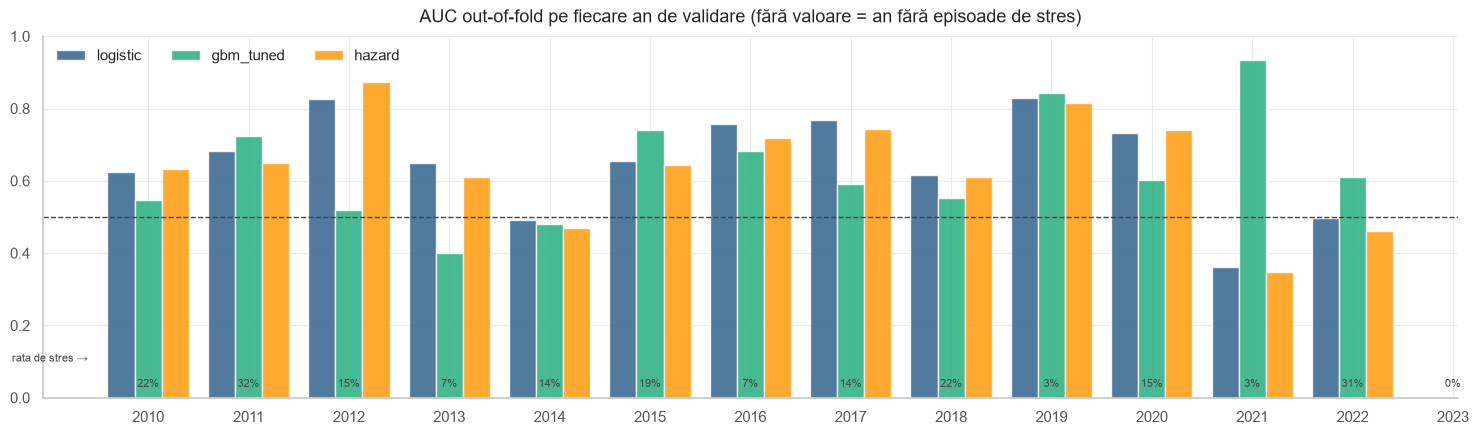

In [84]:
pe_an = []
for an_ in ANI_OOF:
    m_ = OOF.index.year == an_
    yy = y_train[m_]
    rand = {'an': an_, 'rata_stres': yy.mean()}
    for c in BAZA:
        rand[f'AUC_{c}'] = roc_auc_score(yy, OOF.loc[m_, c]) if yy.nunique() == 2 else np.nan
    pe_an.append(rand)
pe_an = pd.DataFrame(pe_an).set_index('an')

fig, ax = plt.subplots(figsize=(15, 4.5))
lat = 0.27
for i, c in enumerate(BAZA):
    ax.bar(pe_an.index + (i - 1) * lat, pe_an[f'AUC_{c}'], width=lat, color=SERII[i], label=c, alpha=0.85)
ax.axhline(0.5, color=C_TEXT, ls='--', lw=1)
for an_, p_ in pe_an['rata_stres'].items():
    ax.text(an_, 0.03, f'{p_:.0%}', ha='center', fontsize=8, color=C_TEXT)
ax.text(pe_an.index.min() - 0.6, 0.1, 'rata de stres →', ha='right', fontsize=8, color=C_TEXT)
ax.set_ylim(0, 1); ax.set_xticks(pe_an.index); ax.legend(ncol=3, loc='upper left')
ax.set_title('AUC out-of-fold pe fiecare an de validare (fără valoare = an fără episoade de stres)')
plt.tight_layout(); plt.show()

Log-loss regresie logistică pe grila C: {0.001: 0.4351, 0.002: 0.4396, 0.005: 0.4483, 0.02: 0.4632, 0.05: 0.473} -> C ales: 0.001


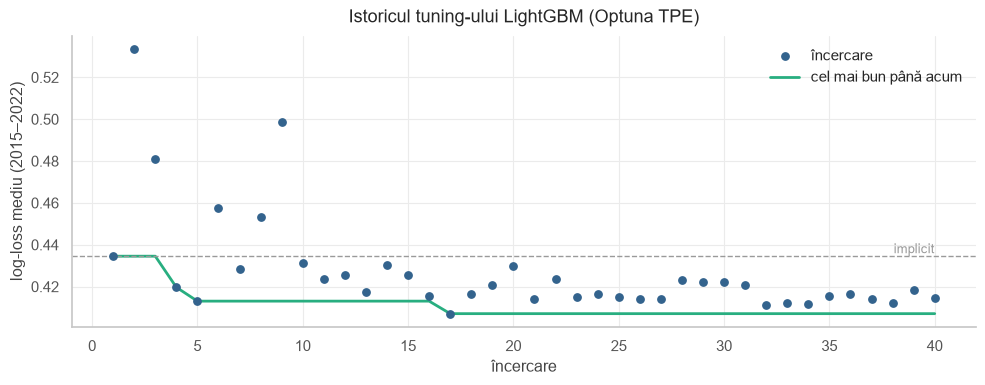

In [85]:
print('Log-loss regresie logistică pe grila C:', {k: round(v, 4) for k, v in logloss_C.items()}, '-> C ales:', LR_C)
if HAS_OPTUNA:
    istoric = [t.value for t in studiu.trials]
    ref = istoric[0]                                    # prima încercare = parametrii impliciți
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(range(1, len(istoric) + 1), istoric, color=SERII[0], s=28, zorder=3, label='încercare')
    ax.plot(range(1, len(istoric) + 1), np.minimum.accumulate(istoric), color=SERII[1], lw=2, label='cel mai bun până acum')
    ax.axhline(ref, color=C_GRI, ls='--', lw=1); ax.text(len(istoric), ref, ' implicit', color=C_GRI, va='bottom', ha='right', fontsize=9)
    ax.set_xlabel('încercare'); ax.set_ylabel('log-loss mediu (2015–2022)')
    ax.set_title('Istoricul tuning-ului LightGBM (Optuna TPE)'); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print('Optuna nu e instalat: s-a folosit random search, al cărui istoric nu e păstrat.')

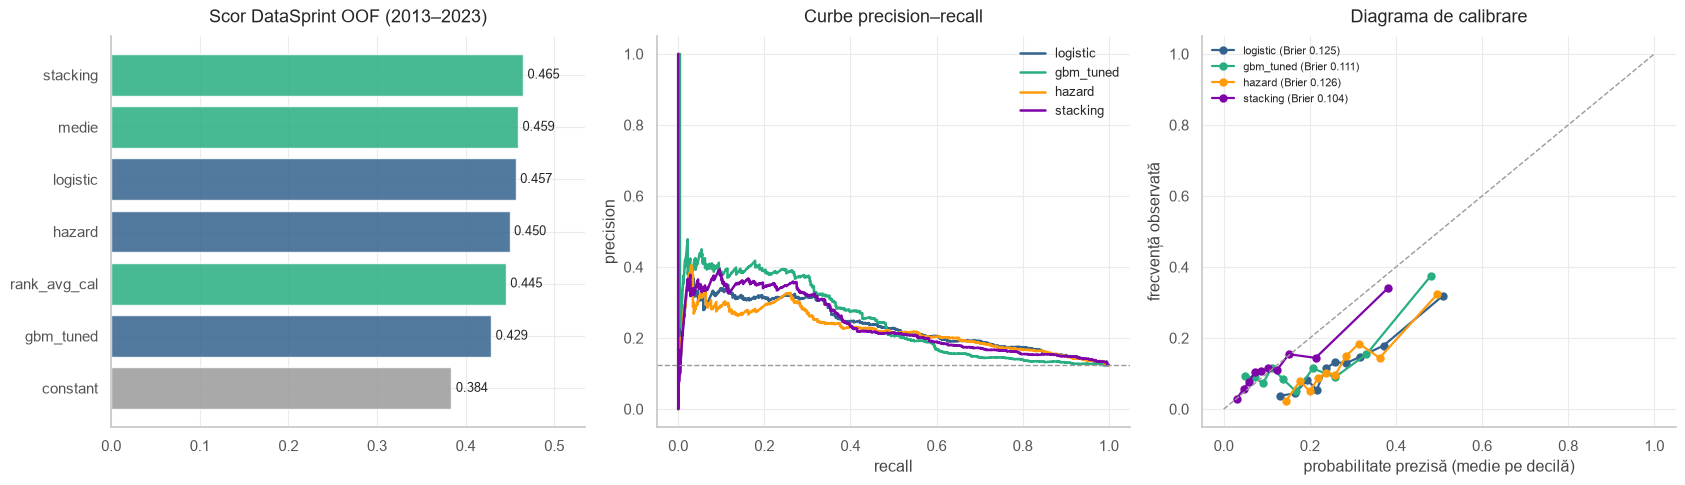

In [86]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
ord_c = comp.sort_values('scor').index
ax.barh(ord_c, comp.loc[ord_c, 'scor'], alpha=0.85,
        color=[C_GRI if i == 'constant' else (SERII[1] if i in ('stacking', 'medie', 'rank_avg_cal') else SERII[0]) for i in ord_c])
for i, v_ in enumerate(comp.loc[ord_c, 'scor']):
    ax.text(v_ + 0.005, i, f'{v_:.3f}', va='center', fontsize=9)
ax.set_xlim(0, comp['scor'].max() * 1.15); ax.set_title('Scor DataSprint OOF (2013–2023)')
ax = axes[1]
for i, c in enumerate(BAZA + ['stacking']):
    pr, rc, _ = precision_recall_curve(y_train[m_comun], OOF.loc[m_comun, c])
    ax.plot(rc, pr, color=SERII[i], lw=1.8, label=c)
ax.axhline(y_train[m_comun].mean(), color=C_GRI, ls='--', lw=1)
ax.set_xlabel('recall'); ax.set_ylabel('precision'); ax.set_title('Curbe precision–recall'); ax.legend(fontsize=9)
ax = axes[2]
for i, c in enumerate(BAZA + ['stacking']):
    cal_df = pd.DataFrame({'p': OOF.loc[m_comun, c], 'y': y_train[m_comun]})
    cal_df['bin'] = pd.qcut(cal_df.p, 10, duplicates='drop')
    g_ = cal_df.groupby('bin', observed=True).mean()
    ax.plot(g_.p, g_.y, marker='o', ms=5, color=SERII[i], lw=1.6, label=f"{c} (Brier {comp.loc[c, 'Brier']:.3f})")
ax.plot([0, 1], [0, 1], color=C_GRI, ls='--', lw=1)
ax.set_xlabel('probabilitate prezisă (medie pe decilă)'); ax.set_ylabel('frecvență observată')
ax.set_title('Diagrama de calibrare'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 13.1 Pragul operațional și nivelurile de risc
Pentru **alerta din dashboard** folosim probabilitatea brută a modelului (fără transformările pentru Kaggle):

| Nivel | Regulă | Interpretare |
|---|---|---|
| 🟢 **Scăzut** | p < prag_alertă | situație normală |
| 🟡 **Moderat** | prag_alertă ≤ p < prag_ridicat | supraveghere: recall mare, alarme false acceptate (logica F2) |
| 🔴 **Ridicat** | p ≥ prag_ridicat | istoric, zilele peste acest prag au fost de stres de cel puțin **2×** mai des decât media |

`prag_alertă` = pragul F2 optim pe OOF. O alertă EWS pornește când nivelul e cel puțin *Moderat* două zile de tranzacționare la rând.

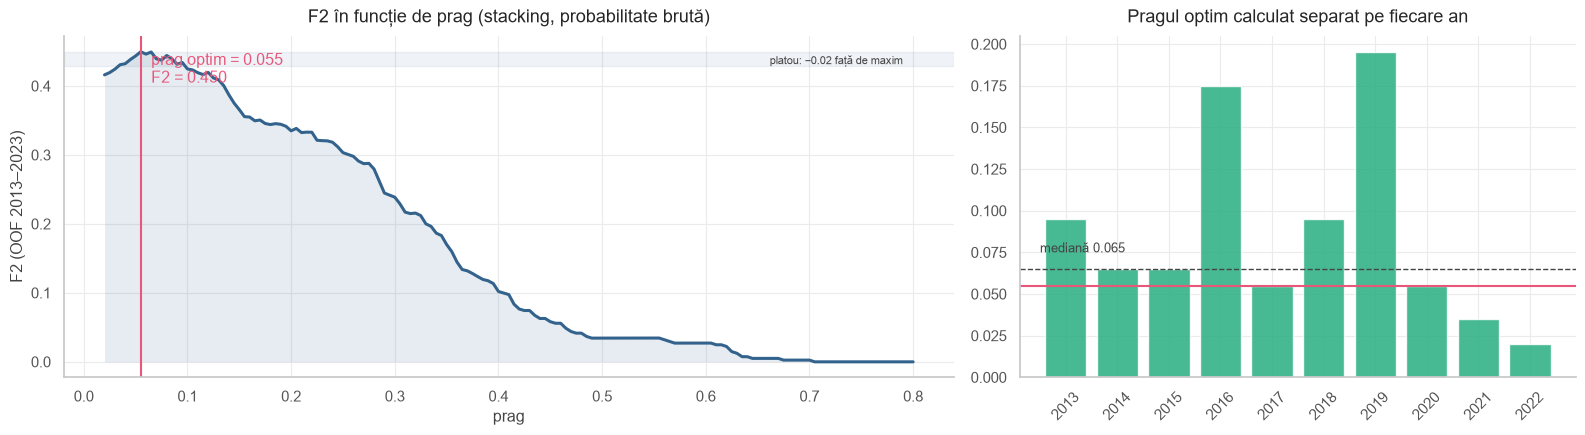

In [87]:
PRAG_ALERTA = prag_optim_f2(y_oof, p_oof)
f2_prag = curba_f2(y_oof, p_oof)
praguri_an = pd.Series({an_: prag_optim_f2(y_oof[p_oof.index.year == an_], p_oof[p_oof.index.year == an_])
                        for an_ in ANI_META if y_oof[p_oof.index.year == an_].sum() > 0})

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
ax.plot(f2_prag.index, f2_prag.values, color=SERII[0], lw=2.2)
ax.fill_between(f2_prag.index, f2_prag.values, color=SERII[0], alpha=0.12, lw=0)
ax.axvline(PRAG_ALERTA, color=C_STRES, lw=1.5)
ax.text(PRAG_ALERTA + 0.01, f2_prag.max(), f'prag optim = {PRAG_ALERTA:.3f}\nF2 = {f2_prag.max():.3f}', color=C_STRES, va='top')
ax.axhspan(f2_prag.max() - 0.02, f2_prag.max(), color=SERII[0], alpha=0.08)
ax.text(0.79, f2_prag.max() - 0.018, 'platou: −0.02 față de maxim', ha='right', fontsize=8, color=C_TEXT)
ax.set_xlabel('prag'); ax.set_ylabel('F2 (OOF 2013–2023)'); ax.set_title(f'F2 în funcție de prag ({MODEL_FINAL}, probabilitate brută)')
ax = axes[1]
ax.bar(praguri_an.index, praguri_an.values, color=SERII[1], alpha=0.85)
ax.axhline(PRAG_ALERTA, color=C_STRES, lw=1.5); ax.axhline(praguri_an.median(), color=C_TEXT, ls='--', lw=1)
ax.text(praguri_an.index.min() - 0.5, praguri_an.median() + 0.01, f'mediană {praguri_an.median():.3f}', fontsize=9, color=C_TEXT)
ax.set_title('Pragul optim calculat separat pe fiecare an'); ax.set_xticks(praguri_an.index); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

In [88]:
# Pragul „Ridicat”: cel mai mic prag cu precizie istorică ≥ 2× rata medie, cu cel puțin 60 de zile peste el (altfel e zgomot)
prev_oof = y_oof.mean()
PRAG_RIDICAT = None
for t_r in np.linspace(PRAG_ALERTA + 0.01, 0.9, 180):
    peste_r = p_oof >= t_r
    if peste_r.sum() < 60:
        break
    if y_oof[peste_r].mean() >= 2 * prev_oof:
        PRAG_RIDICAT = float(t_r)
        break
if PRAG_RIDICAT is None:
    PRAG_RIDICAT = float(max(p_oof.quantile(0.9), PRAG_ALERTA + 0.01))
CULORI_NIVEL = {'Scăzut': '#0ca30c', 'Moderat': '#fab219', 'Ridicat': '#d03b3b'}


def nivel_risc(p):
    "Scăzut / Moderat / Ridicat pe probabilitatea brută."
    return pd.Series(np.select([p >= PRAG_RIDICAT, p >= PRAG_ALERTA], ['Ridicat', 'Moderat'], 'Scăzut'), index=p.index)


def alerte_ews(p, zile_confirmare=2):
    "Alertă confirmată (≥ prag_alertă N zile lucrătoare la rând) și ziua în care pornește."
    peste = (p >= PRAG_ALERTA).astype(int)
    peste = peste[peste.index.dayofweek < 5]
    confirmat = peste.rolling(zile_confirmare).sum() >= zile_confirmare
    return confirmat, confirmat & ~confirmat.shift(1, fill_value=False)


print(f"Prag alertă (F2):  {PRAG_ALERTA:.3f}")
print(f"Prag risc ridicat: {PRAG_RIDICAT:.3f}  (precizie istorică peste prag: {y_oof[p_oof >= PRAG_RIDICAT].mean():.1%} vs. rata medie {prev_oof:.1%})")
niv_oof = nivel_risc(p_oof)
confirmat_oof, _ = alerte_ews(p_oof)
deb_oof = debut[debut >= pd.Timestamp('2013-01-01')]
avans = pd.Series([(d_ - confirmat_oof.loc[d_ - pd.Timedelta(days=30):d_][lambda s_: s_].index.min()).days
                   if confirmat_oof.loc[d_ - pd.Timedelta(days=30):d_].any() else np.nan for d_ in deb_oof], index=deb_oof)
print(f"Episoade 2013–2023: {len(deb_oof)} | cu alertă activă în cele 30 de zile dinainte/la debut: {avans.notna().sum()} "
      f"| avans median: {avans.median():.0f} zile")
print('Distribuția nivelurilor de risc (OOF):', niv_oof.value_counts(normalize=True).round(3).to_dict())
display(pd.crosstab(niv_oof, y_oof.map({0: 'normal', 1: 'stres'}), normalize='index').round(3).rename_axis('nivel risc'))

Prag alertă (F2):  0.055
Prag risc ridicat: 0.182  (precizie istorică peste prag: 24.9% vs. rata medie 12.4%)
Episoade 2013–2023: 15 | cu alertă activă în cele 30 de zile dinainte/la debut: 15 | avans median: 29 zile
Distribuția nivelurilor de risc (OOF): {'Moderat': 0.588, 'Scăzut': 0.223, 'Ridicat': 0.19}


stress_event_20d,normal,stres
nivel risc,,
Moderat,0.886,0.114
Ridicat,0.751,0.249
Scăzut,0.957,0.043


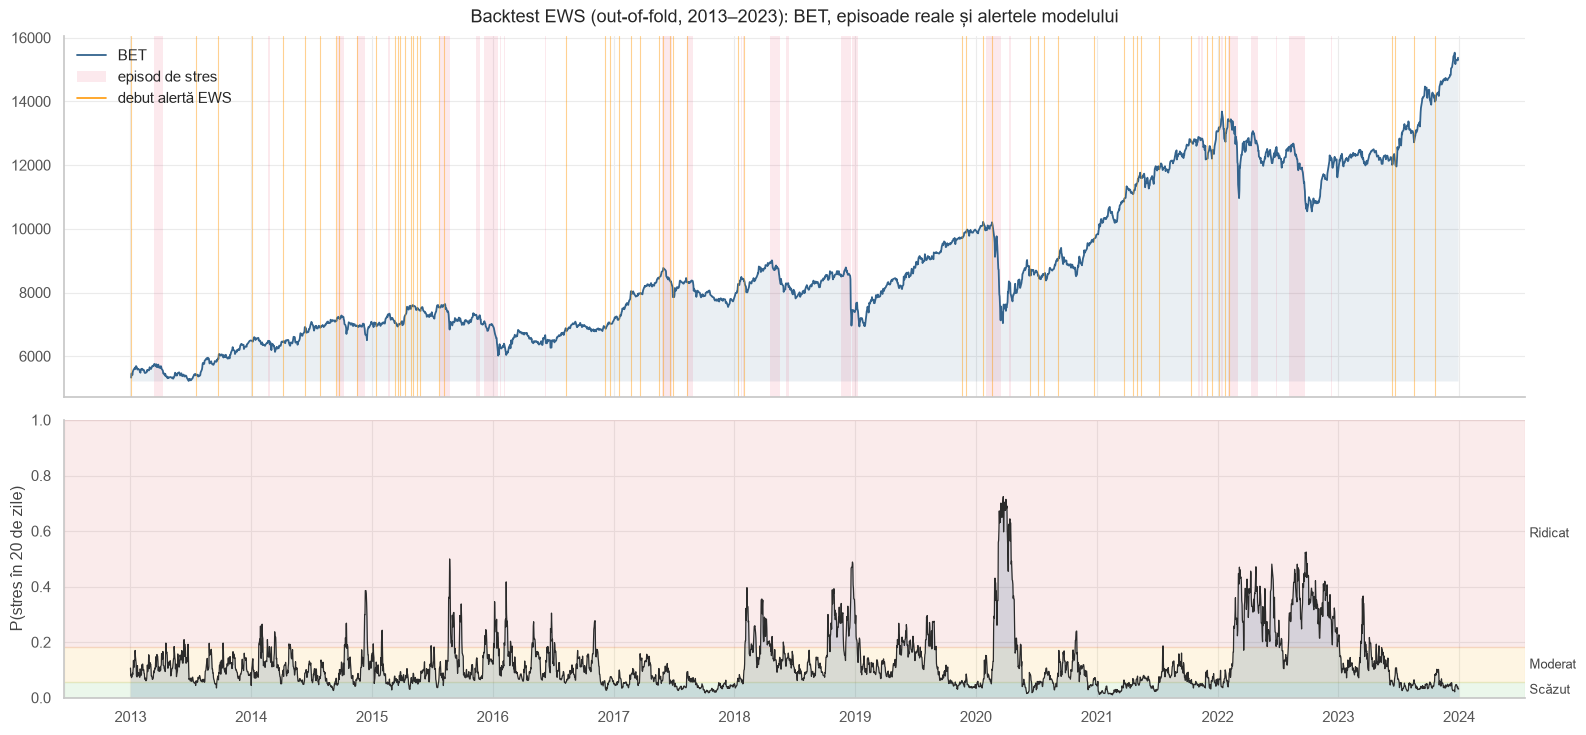

In [89]:
def panou_ews(p, titlu_fig, y_real=None):
    "BET + probabilitatea cu nivelurile de risc + debuturile de alertă EWS."
    fig, axes = plt.subplots(2, 1, figsize=(16, 7.5), sharex=True, gridspec_kw={'height_ratios': [1.3, 1]})
    ax = axes[0]
    linie(ax, bet.loc[p.index.min():p.index.max()], SERII[0], label='BET', alpha_fill=0.10)
    if y_real is not None:
        umbreste_stres(ax, y_real.loc[p.index.min():p.index.max()])
    _, deb = alerte_ews(p)
    for d_ in deb[deb].index:
        ax.axvline(d_, color=SERII[2], lw=0.8, alpha=0.45)
    ax.plot([], [], color=SERII[2], lw=1.2, label='debut alertă EWS')
    ax.legend(loc='upper left'); ax.set_title(titlu_fig)
    ax = axes[1]
    ax.axhspan(0, PRAG_ALERTA, color=CULORI_NIVEL['Scăzut'], alpha=0.08)
    ax.axhspan(PRAG_ALERTA, PRAG_RIDICAT, color=CULORI_NIVEL['Moderat'], alpha=0.12)
    ax.axhspan(PRAG_RIDICAT, 1, color=CULORI_NIVEL['Ridicat'], alpha=0.10)
    ax.plot(p, color='#2b2b2b', lw=0.9)
    ax.fill_between(p.index, p.values, 0, color=SERII[0], alpha=0.18, lw=0)
    for nume_n, (lo, hi) in {'Scăzut': (0, PRAG_ALERTA), 'Moderat': (PRAG_ALERTA, PRAG_RIDICAT), 'Ridicat': (PRAG_RIDICAT, 1)}.items():
        ax.text(1.003, (lo + min(hi, 1.0)) / 2, nume_n, fontsize=9, color=C_TEXT, va='center', transform=ax.get_yaxis_transform())
    ax.set_ylim(0, 1); ax.set_ylabel('P(stres în 20 de zile)')
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout(); plt.show()


panou_ews(p_oof, 'Backtest EWS (out-of-fold, 2013–2023): BET, episoade reale și alertele modelului', y_real=y_train)

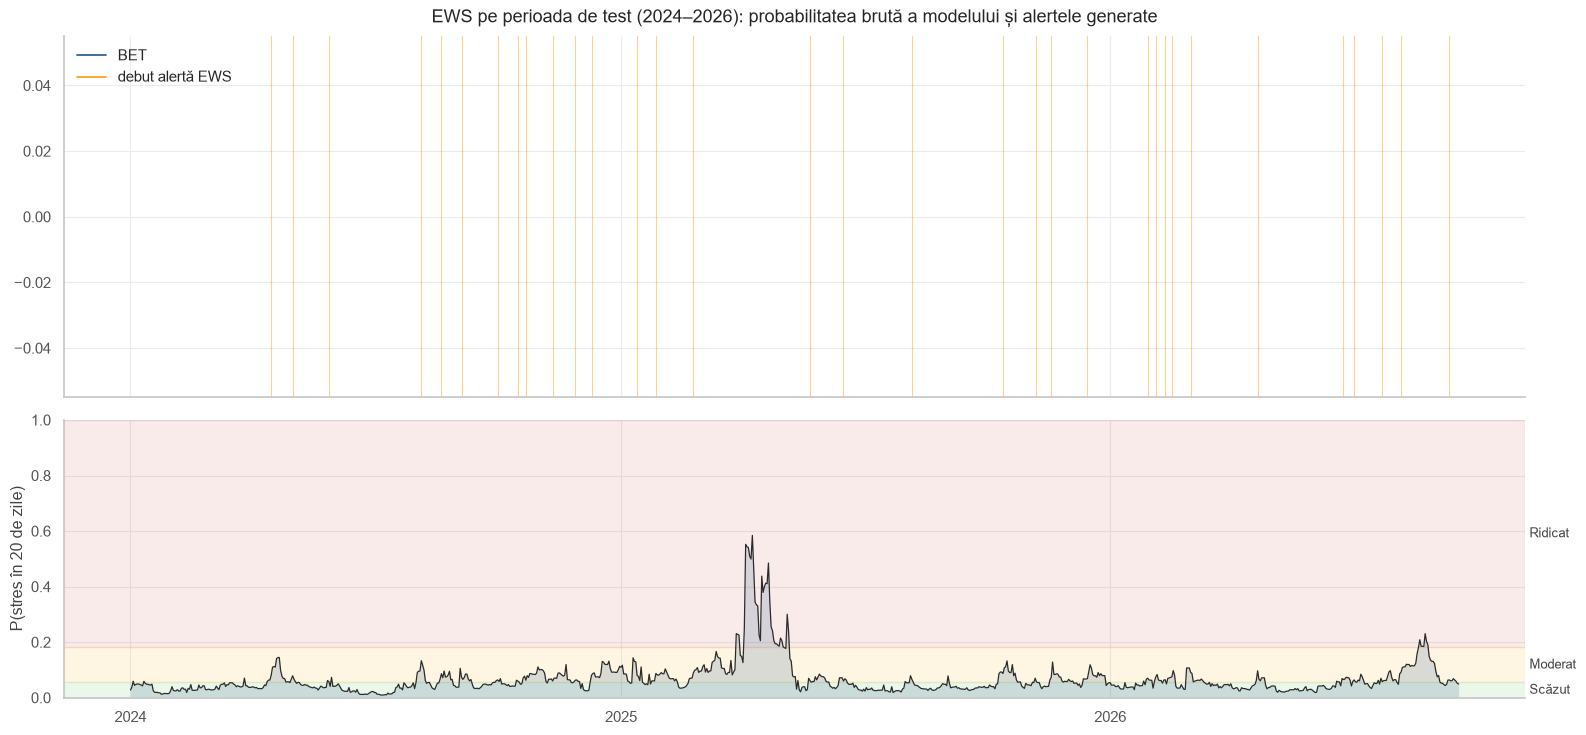

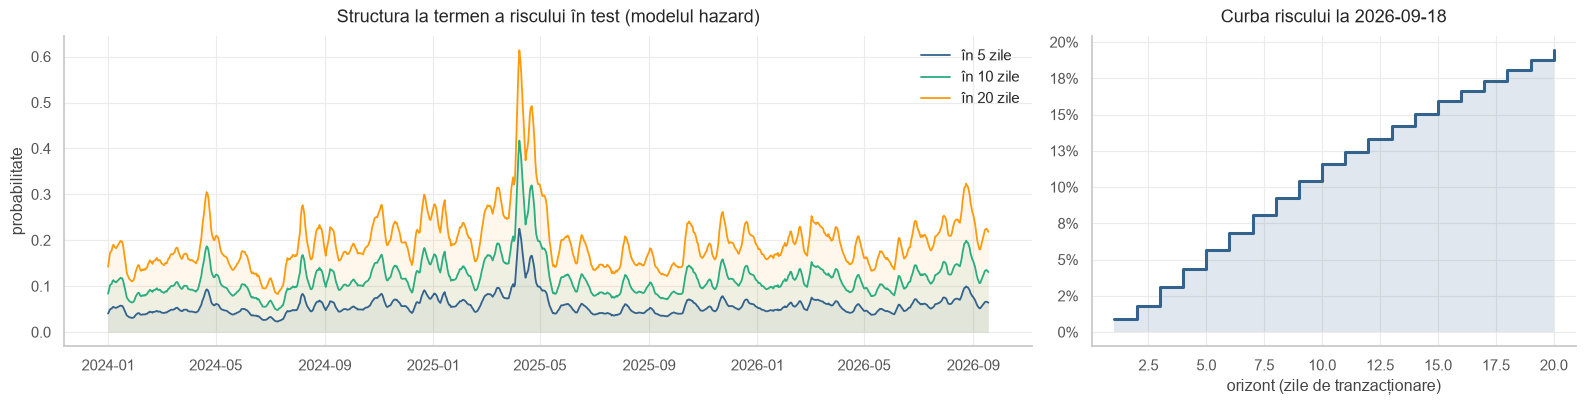

,probabilitate brută,nivel,în alertă Kaggle
2026-09-09,0.048,Scăzut,False
2026-09-10,0.064,Moderat,False
2026-09-11,0.064,Moderat,True
2026-09-12,0.061,Moderat,True
2026-09-13,0.061,Moderat,True
2026-09-14,0.069,Moderat,True
2026-09-15,0.064,Moderat,True
2026-09-16,0.059,Moderat,True
2026-09-17,0.052,Scăzut,True
2026-09-18,0.050,Scăzut,False


In [90]:
p_test_brut = P_TEST[MODEL_FINAL]
panou_ews(p_test_brut, 'EWS pe perioada de test (2024–2026): probabilitatea brută a modelului și alertele generate')

curbe_test = pd.DataFrame(1 - np.cumprod(1 - hz_final.hazard(X_test), axis=1), index=X_test.index,
                          columns=[f'P(T<={k})' for k in range(1, 21)])
ultima = curbe_test.index.max()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
for i, k in enumerate([5, 10, 20]):
    linie(ax, curbe_test[f'P(T<={k})'].rolling(5, min_periods=1).mean(), SERII[i], label=f'în {k} zile', alpha_fill=0.08, baza=0)
ax.set_title('Structura la termen a riscului în test (modelul hazard)'); ax.legend(); ax.set_ylabel('probabilitate')
ax = axes[1]
ax.step(range(1, 21), curbe_test.loc[ultima].values, where='post', color=SERII[0], lw=2.2)
ax.fill_between(range(1, 21), curbe_test.loc[ultima].values, step='post', color=SERII[0], alpha=0.15, lw=0)
ax.set_xlabel('orizont (zile de tranzacționare)'); ax.set_title(f'Curba riscului la {ultima.date()}')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()
display(pd.DataFrame({'probabilitate brută': p_test_brut.tail(10).round(3), 'nivel': nivel_risc(p_test_brut).tail(10),
                      'în alertă Kaggle': alerta_final.tail(10)}))

## 14. 📊 Explicabilitate: ce stă în spatele riscului estimat?
Explicăm **probabilitatea brută** a modelului (`MODEL_FINAL`), nu valorile transformate de stratul de decizie pentru Kaggle.
Patru niveluri, de la global la local:
1. **importanță globală:** coeficienții regresiei logistice și *permutation importance* pentru LightGBM;
2. **SHAP** pentru LightGBM: beeswarm, importanța medie |SHAP|, waterfall pentru o zi, dependence plot;
3. **valori Shapley exacte pe categorii** pentru modelul final (bonusul: riscul descompus pe categorii);
4. **LIME:** un model liniar local în jurul unei singure zile.

In [91]:
rang_oof = lambda B: np.column_stack([np.searchsorted(OOF_SORTAT[c], B[c].values) / m_meta.sum() for c in BAZA]).mean(axis=1)


def predictie_finala(X):
    "Probabilitatea brută a modelului final pentru orice matrice X (folosită de SHAP / Shapley / LIME)."
    p_gbm = np.mean([m_.predict_proba(X)[:, 1] for m_ in gbm_finale], axis=0)
    if MODEL_FINAL == 'gbm_tuned':
        return p_gbm
    B = pd.DataFrame({'logistic': lr_final.predict_proba(X)[:, 1], 'gbm_tuned': p_gbm,
                      'hazard': hz_final.predict_proba(X)[:, 1]})[BAZA]
    if MODEL_FINAL == 'medie':
        return B.mean(axis=1).values
    if MODEL_FINAL == 'stacking':
        return meta_final.predict_proba(logit(B))[:, 1]
    return iso_final.predict(rang_oof(B))


assert np.allclose(predictie_finala(X_test), P_TEST[MODEL_FINAL].values)
zi_max, zi_min = P_TEST[MODEL_FINAL].idxmax(), P_TEST[MODEL_FINAL].idxmin()
mediane = X_train.median()
CAT_MODEL_VAR = {c: CAT_EDA[c] for c in FEATURES}

### 14.1 Importanță globală

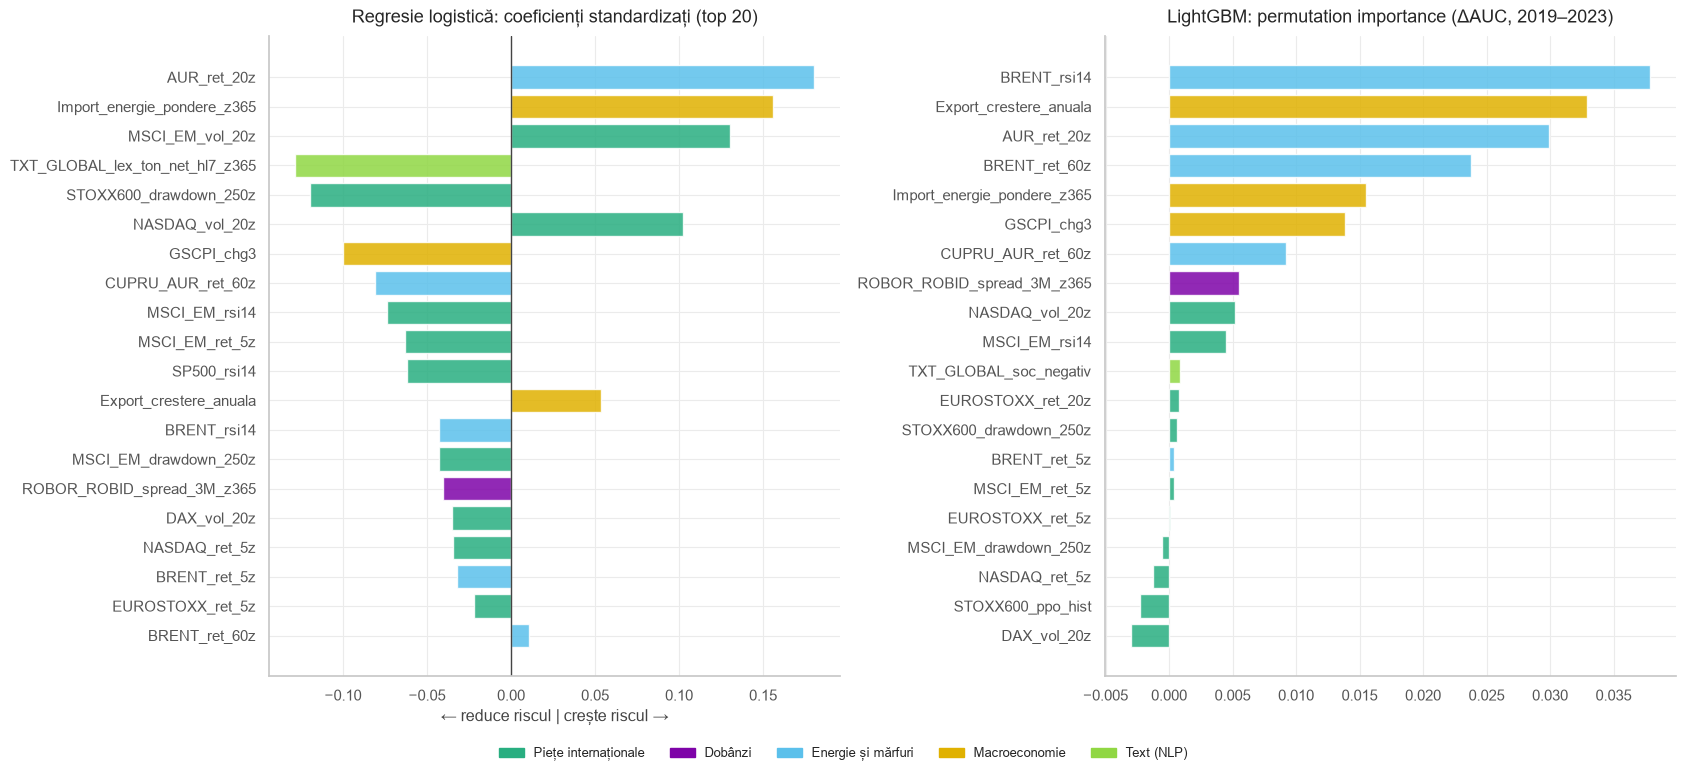

In [92]:
ULTIMII_ANI = X_train.index >= '2019-01-01'
m_fit = X_train.index < pd.Timestamp('2019-01-01') - pd.Timedelta(days=GAP_ZILE)
lr_expl = model_logistic(C=LR_C).fit(X_train[m_fit], y_train[m_fit])
coef = pd.Series(lr_expl[-1].coef_[0], index=FEATURES)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index[:20])
gbm_expl = model_gbm(BEST_GBM).fit(X_train[m_fit], y_train[m_fit])
pi = permutation_importance(gbm_expl, X_train[ULTIMII_ANI], y_train[ULTIMII_ANI], scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(20)

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
ax = axes[0]
ax.barh(top_coef.index[::-1], top_coef.values[::-1], color=[CULOARE_CAT[CAT_MODEL_VAR[c]] for c in top_coef.index[::-1]], alpha=0.85)
ax.axvline(0, color=C_TEXT, lw=1); ax.set_title('Regresie logistică: coeficienți standardizați (top 20)'); ax.set_xlabel('← reduce riscul | crește riscul →')
ax = axes[1]
ax.barh(imp.index[::-1], imp.values[::-1], color=[CULOARE_CAT[CAT_MODEL_VAR[c]] for c in imp.index[::-1]], alpha=0.85)
ax.set_title('LightGBM: permutation importance (ΔAUC, 2019–2023)')
fig.legend(handles=[Patch(color=CULOARE_CAT[k], label=k) for k in CATEGORII if k in CAT_MODEL_VAR.values()],
           loc='lower center', ncol=8, fontsize=9, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()

In [93]:
# Semnificația statistică a coeficienților (p-values), cu aceeași preprocesare ca regresia logistică
try:
    import statsmodels.api as sm
    X_sm = sm.add_constant(lr_expl[:-1].transform(X_train[m_fit]))
    model_sm = sm.Logit(y_train[m_fit].values, X_sm).fit(disp=0)
    display(pd.DataFrame({'Coeficient': model_sm.params, 'P-Value': model_sm.pvalues},
                         index=['Intercept'] + list(FEATURES)).sort_values('P-Value').head(20))
except ImportError:
    print('statsmodels nu este instalat.')

,Coeficient,P-Value
Intercept,-1.186661,2.893549e-221
AUR_ret_20z,0.537436,6.507004e-37
DAX_vol_20z,-0.665105,1.915699e-18
MSCI_EM_vol_20z,0.918813,1.383955e-16
GSCPI_chg3,-0.266875,1.350396e-11
STOXX600_drawdown_250z,-0.618919,1.209974e-10
Import_energie_pondere_z365,0.261612,1.660950e-10
TXT_GLOBAL_lex_ton_net_hl7_z365,-0.299963,5.121798e-09
MSCI_EM_rsi14,-0.390487,7.815104e-08
BRENT_rsi14,-0.356111,2.296429e-07


**Atenție la p-values:** zilele consecutive nu sunt independente (ținta e autocorelată), deci p-values-urile clasice sunt prea optimiste.
Folosește-le ca ordine de mărime, nu ca test riguros. Modelul `statsmodels` nu are regularizare, deci coeficienții diferă de cei din `lr_expl`.

### 14.2 SHAP
Valorile SHAP sunt **aditive**: valoarea de bază + suma contribuțiilor = predicția (pe scara internă a LightGBM).

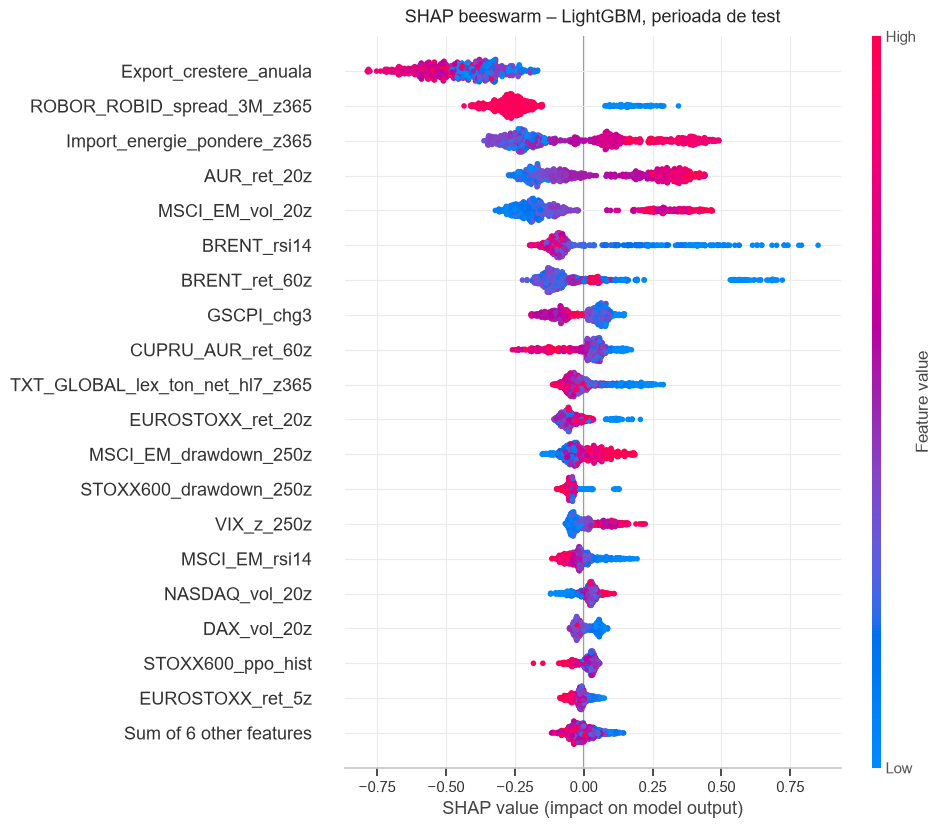

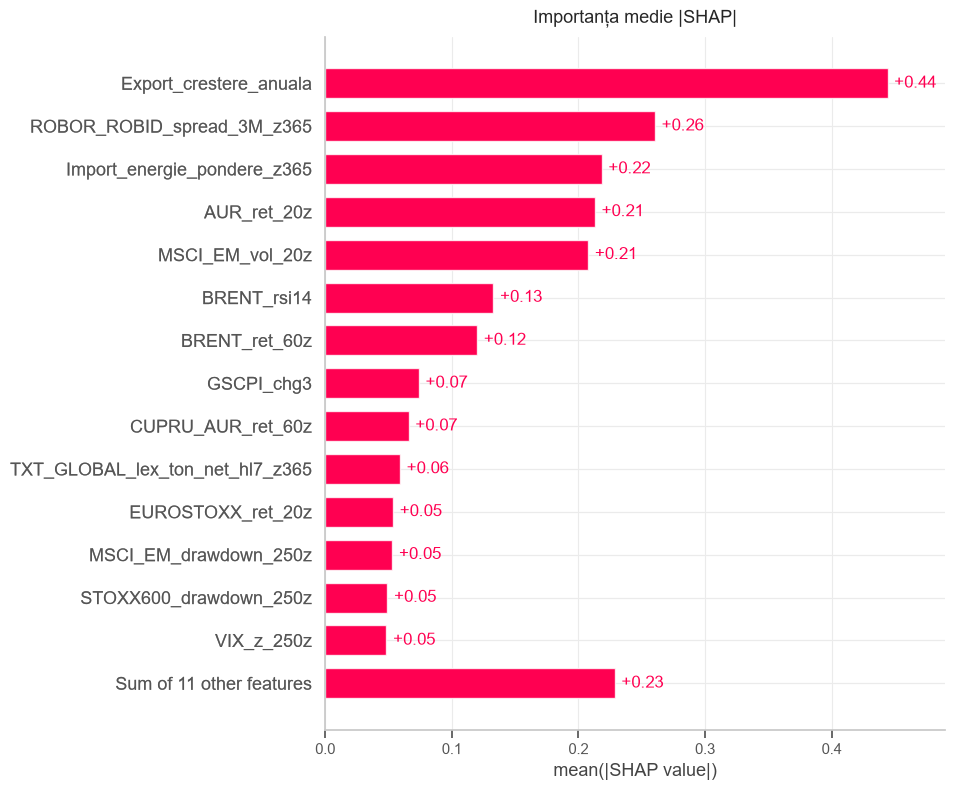

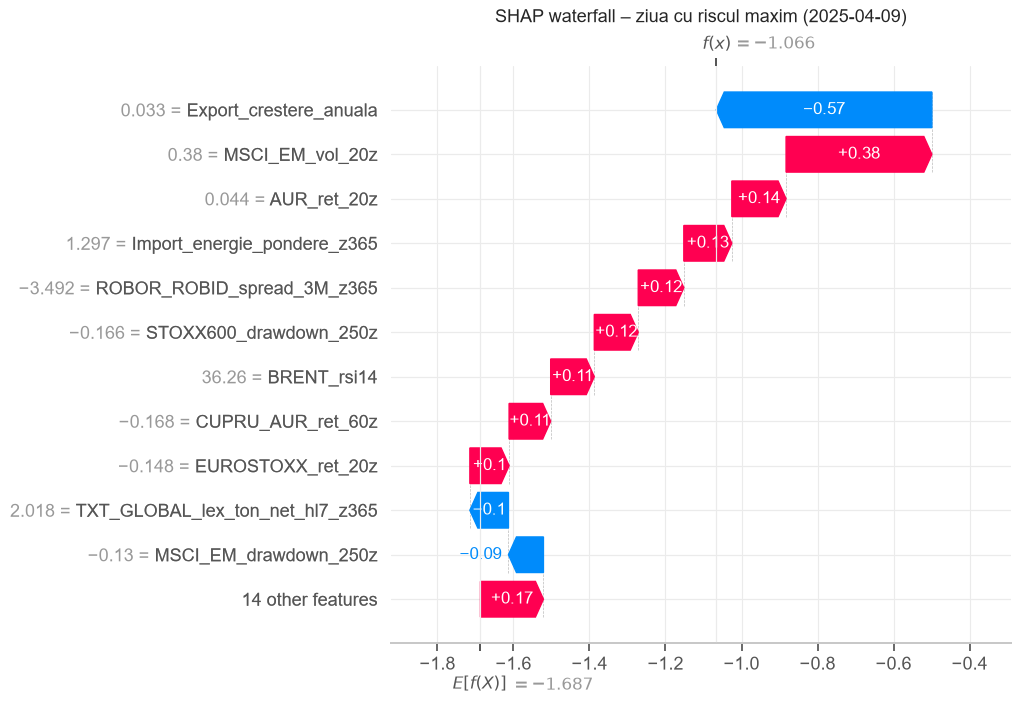

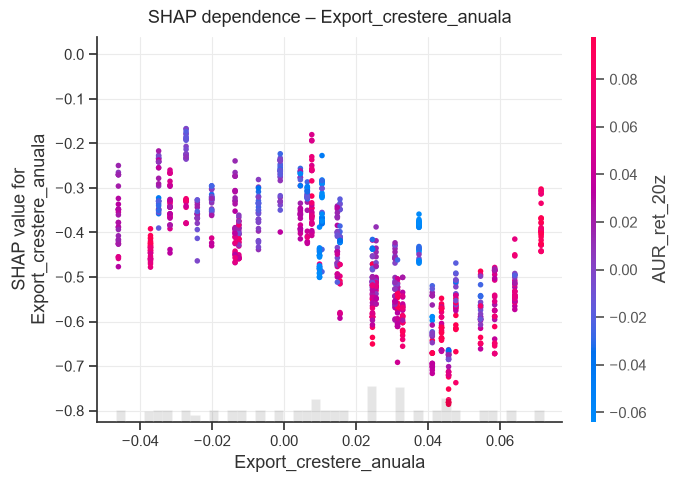

In [94]:
try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

if HAS_SHAP:
    try:
        if HAS_LGB:
            explainer = shap.TreeExplainer(gbm_finale[0])
            sv = explainer(X_test)
            sv_zi = explainer(X_test.loc[[zi_max]])
        else:
            fundal_shap = shap.utils.sample(X_train.loc['2015':].fillna(mediane), 100, random_state=SEED)
            explainer = shap.Explainer(lambda Z: gbm_finale[0].predict_proba(pd.DataFrame(Z, columns=FEATURES))[:, 1], fundal_shap)
            sv = explainer(X_test.fillna(mediane).iloc[::5])
            sv_zi = explainer(X_test.loc[[zi_max]].fillna(mediane))
        if sv.values.ndim == 3:
            sv, sv_zi = sv[:, :, 1], sv_zi[:, :, 1]
        shap.plots.beeswarm(sv, max_display=20, show=False)
        plt.title('SHAP beeswarm – LightGBM, perioada de test'); plt.show()
        shap.plots.bar(sv, max_display=15, show=False)
        plt.title('Importanța medie |SHAP|'); plt.show()
        shap.plots.waterfall(sv_zi[0], max_display=12, show=False)
        plt.title(f'SHAP waterfall – ziua cu riscul maxim ({pd.Timestamp(zi_max).date()})'); plt.show()
        top_f = FEATURES[int(np.abs(sv.values).mean(axis=0).argmax())]
        shap.plots.scatter(sv[:, top_f], color=sv, show=False)
        plt.title(f'SHAP dependence – {top_f}'); plt.show()
    except Exception as e:
        print('SHAP a eșuat:', repr(e)[:300])
else:
    print('Biblioteca shap nu este instalată (pe Kaggle este deja instalată).')

### 14.3 Bonus: descompunerea riscului pe categorii (valori Shapley exacte)
Grupăm variabilele pe categorii și calculăm **valoarea Shapley a fiecărei categorii** pentru modelul final:
$$\phi_c(x) = \sum_{S \subseteq \mathcal{C}\setminus\{c\}} \frac{|S|!\,(G-|S|-1)!}{G!}\,\big[v(S\cup\{c\}) - v(S)\big],\qquad v(S) = \mathbb{E}_{b\,\sim\,\text{fundal}}\big[f(x_S,\, b_{\bar S})\big]$$
* cu G ≤ 8 categorii avem cel mult 256 de coaliții → calculul e **exact**;
* funcționează pentru **orice model**, inclusiv ansamblul final;
* **eficiență:** $\sum_c \phi_c(x) = f(x) - \mathbb{E}[f]$, deci contribuțiile se adună exact la probabilitate;
* interpretare: câte **puncte procentuale** de probabilitate adaugă (sau scad) factorii din categoria *c* în ziua respectivă.


In [95]:
def shapley_pe_categorii(f, X, fundal, grupuri):
    "Valori Shapley exacte pe grupuri de variabile (intervențional, cu distribuție de fundal)."
    nume_g = list(grupuri)
    G, n, m_b = len(nume_g), len(X), len(fundal)
    idx_g = [[X.columns.get_loc(c) for c in grupuri[g]] for g in nume_g]
    Xv, Bv = X.values.astype(float), fundal[X.columns].values.astype(float)
    v = {}
    for masca in range(2 ** G):
        Z = np.repeat(Bv[None, :, :], n, axis=0)               # pornim de la fundal
        for g in range(G):
            if masca >> g & 1:                                  # categoria g „prezentă” -> valorile zilei x
                Z[:, :, idx_g[g]] = Xv[:, None, idx_g[g]]
        v[masca] = np.asarray(f(pd.DataFrame(Z.reshape(n * m_b, -1), columns=X.columns))).reshape(n, m_b).mean(axis=1)
    phi = np.zeros((n, G))
    for g in range(G):
        for masca in range(2 ** G):
            if masca >> g & 1:
                continue
            k = bin(masca).count('1')
            w = math.factorial(k) * math.factorial(G - k - 1) / math.factorial(G)
            phi[:, g] += w * (v[masca | (1 << g)] - v[masca])
    return pd.DataFrame(phi, index=X.index, columns=nume_g), float(v[0].mean())


GRUPURI = {c: [f for f in FEATURES if CAT_MODEL_VAR[f] == c] for c in CATEGORII if c in CAT_MODEL_VAR.values()}
CAT_MODEL = list(GRUPURI)
fundal = X_train.loc['2015':].sample(40, random_state=SEED)
PHI, baza_phi = shapley_pe_categorii(predictie_finala, X_test, fundal, GRUPURI)
print(f"E[f] pe fundal = {baza_phi:.3f} | verificare eficiență, max |Σφ − (f(x) − E[f])| = "
      f"{np.abs(PHI.sum(axis=1).values - (P_TEST[MODEL_FINAL].values - baza_phi)).max():.2e}")

E[f] pe fundal = 0.086 | verificare eficiență, max |Σφ − (f(x) − E[f])| = 1.11e-16


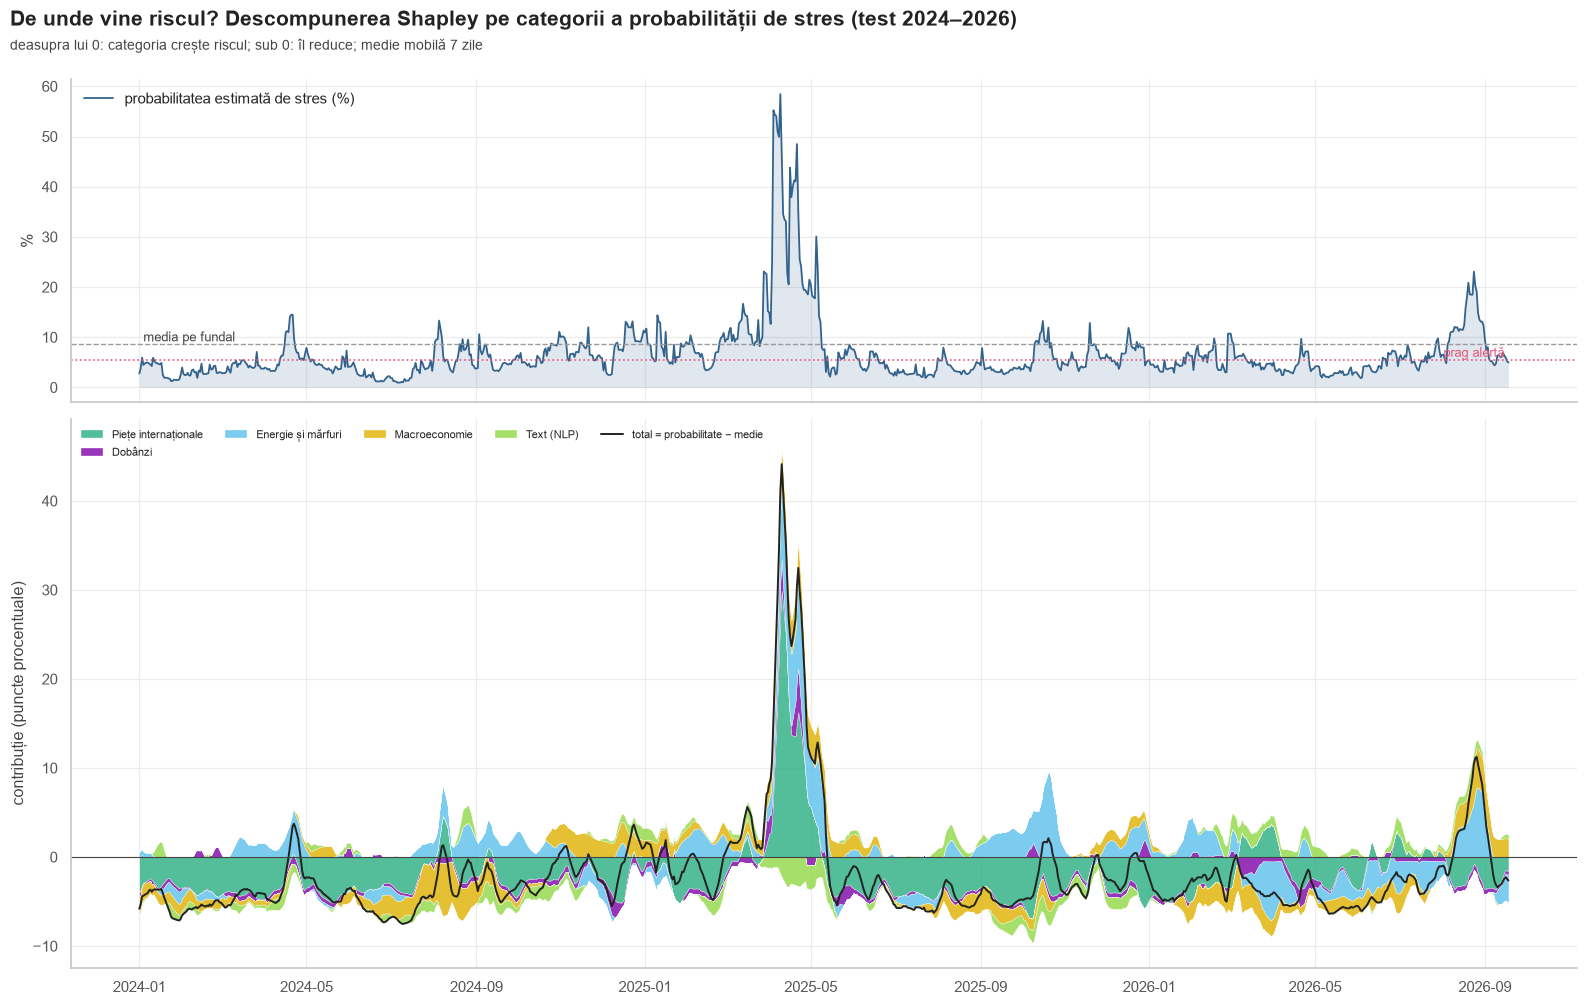

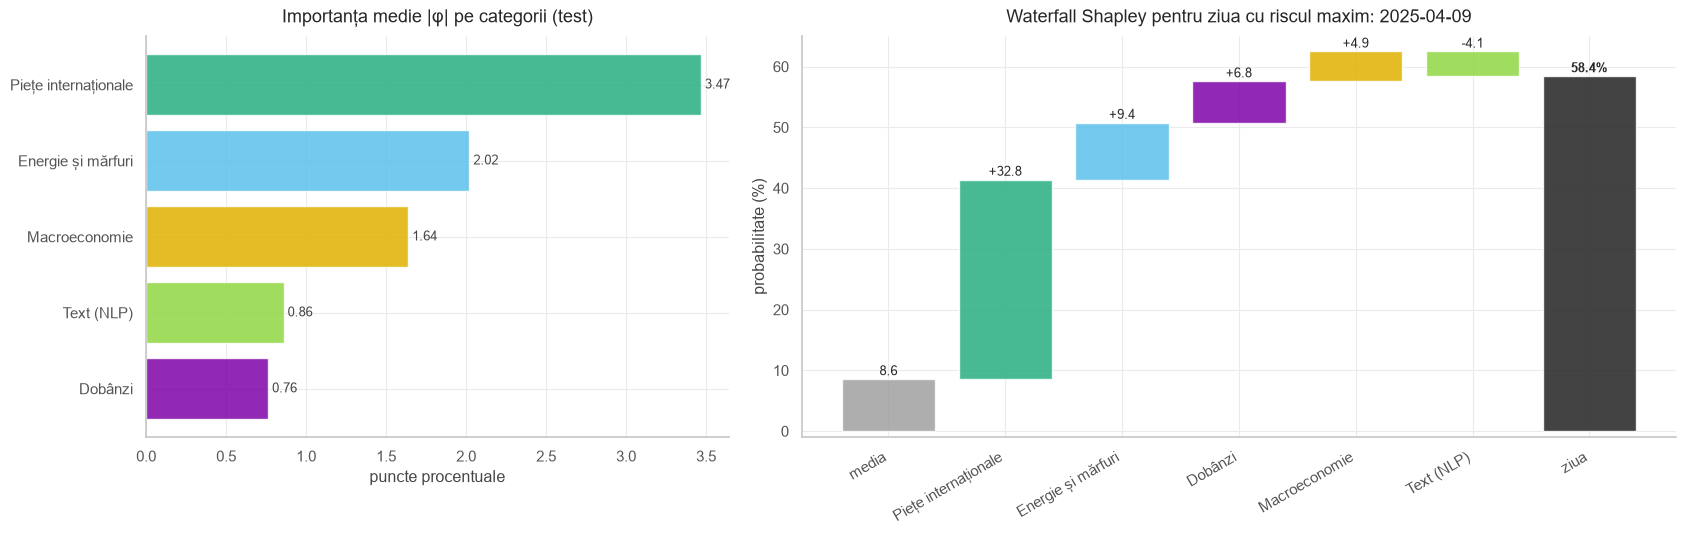

In [96]:
phi_pp = PHI * 100
phi_s = phi_pp.rolling(7, min_periods=1).mean()        # netezire doar pentru vizualizare
fig, axes = plt.subplots(2, 1, figsize=(16, 9.5), sharex=True, gridspec_kw={'height_ratios': [1, 1.7]})
ax = axes[0]
linie(ax, P_TEST[MODEL_FINAL] * 100, SERII[0], label='probabilitatea estimată de stres (%)', alpha_fill=0.15, baza=0)
ax.axhline(baza_phi * 100, color=C_GRI, ls='--', lw=1)
ax.text(P_TEST.index.min(), baza_phi * 100, ' media pe fundal', va='bottom', fontsize=9, color=C_TEXT)
ax.axhline(PRAG_ALERTA * 100, color=C_STRES, ls=':', lw=1.2)
ax.text(P_TEST.index.max(), PRAG_ALERTA * 100, 'prag alertă ', va='bottom', ha='right', fontsize=9, color=C_STRES)
ax.set_ylabel('%'); ax.legend(loc='upper left')
ax = axes[1]
poz, neg = phi_s.clip(lower=0), phi_s.clip(upper=0)
culori = [CULOARE_CAT[c] for c in CAT_MODEL]
ax.stackplot(poz.index, poz[CAT_MODEL].T.values, colors=culori, labels=CAT_MODEL, alpha=0.8, edgecolor='white', lw=0.3)
ax.stackplot(neg.index, neg[CAT_MODEL].T.values, colors=culori, alpha=0.8, edgecolor='white', lw=0.3)
ax.plot(phi_s.sum(axis=1), color='#222222', lw=1.4, label='total = probabilitate − medie')
ax.axhline(0, color=C_TEXT, lw=0.8)
ax.legend(ncol=5, fontsize=8, loc='upper left'); ax.set_ylabel('contribuție (puncte procentuale)')
titlu(fig, 'De unde vine riscul? Descompunerea Shapley pe categorii a probabilității de stres (test 2024–2026)',
      'deasupra lui 0: categoria crește riscul; sub 0: îl reduce; medie mobilă 7 zile')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1, 1.5]})
ax = axes[0]
imp_cat = phi_pp.abs().mean().sort_values()
ax.barh(imp_cat.index, imp_cat.values, color=[CULOARE_CAT[c] for c in imp_cat.index], alpha=0.85)
for i, v_ in enumerate(imp_cat.values):
    ax.text(v_, i, f' {v_:.2f}', va='center', fontsize=9, color=C_TEXT)
ax.set_title('Importanța medie |φ| pe categorii (test)'); ax.set_xlabel('puncte procentuale')
ax = axes[1]
c_zi = phi_pp.loc[zi_max].sort_values(key=np.abs, ascending=False)
cum, nivele = baza_phi * 100, [0, baza_phi * 100]
ax.bar(0, cum, color=C_GRI, alpha=0.8)
ax.text(0, cum + 0.2, f'{cum:.1f}', ha='center', va='bottom', fontsize=9)
for i, (cat_, v_) in enumerate(c_zi.items(), start=1):
    ax.bar(i, v_, bottom=cum, color=CULOARE_CAT[cat_], alpha=0.85)
    ax.text(i, max(cum, cum + v_) + 0.2, f'{v_:+.1f}', ha='center', va='bottom', fontsize=9)
    cum += v_
    nivele.append(cum)
ax.bar(len(c_zi) + 1, cum, color='#222222', alpha=0.85)
ax.text(len(c_zi) + 1, cum + 0.2, f'{cum:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_xticks(range(len(c_zi) + 2)); ax.set_xticklabels(['media'] + list(c_zi.index) + ['ziua'], rotation=30, ha='right')
ax.set_ylim(min(nivele) - 1, max(nivele) + 2.5); ax.set_ylabel('probabilitate (%)')
ax.set_title(f'Waterfall Shapley pentru ziua cu riscul maxim: {pd.Timestamp(zi_max).date()}')
plt.tight_layout(); plt.show()

### 14.4 LIME: explicație locală pentru o singură zi
LIME perturbă observația, vede cum se schimbă predicția și potrivește un model liniar ponderat după apropierea de punctul inițial.
⚠️ LIME e instabil (depinde de perturbări și de lățimea kernelului): compară-l cu SHAP înainte să tragi concluzii.

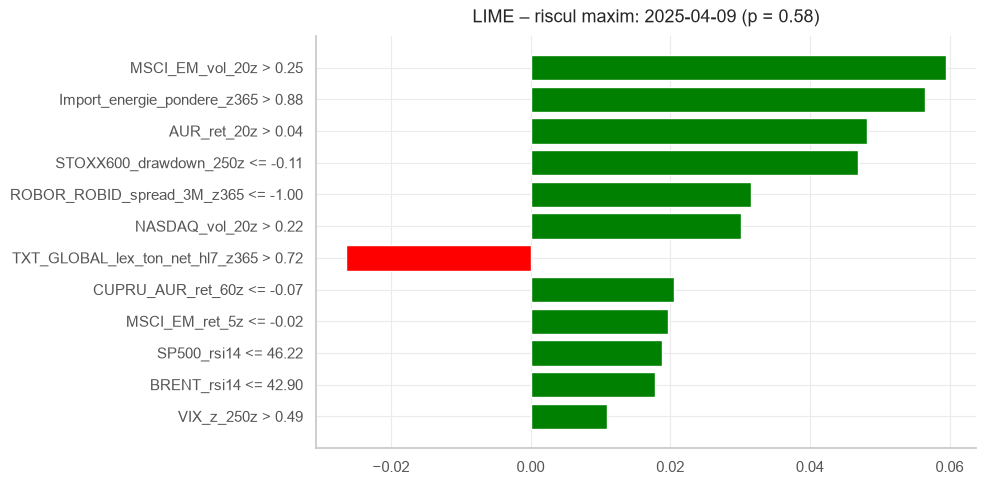

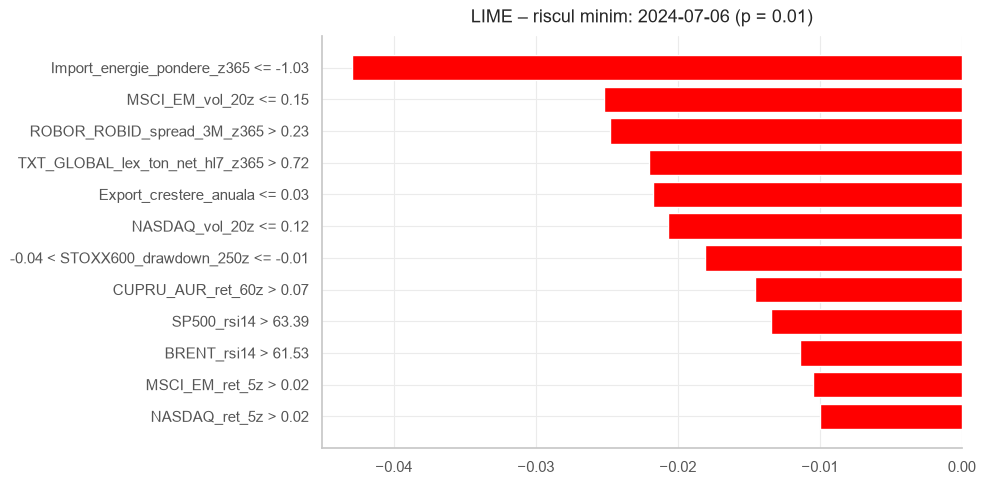

In [97]:
from sklearn.linear_model import Ridge
try:
    from lime.lime_tabular import LimeTabularExplainer
    HAS_LIME = True
except ImportError:
    HAS_LIME = False


def lime_compact(f, x, X_ref, n=3000, latime=0.75, k=12, seed=SEED):
    "LIME pentru date tabulare continue: efectele locale (per +1σ) ale celor mai importante k variabile."
    med, sd = X_ref.median(), X_ref.std().replace(0, 1).fillna(1)
    x0 = x.fillna(med)
    rng_l = np.random.default_rng(seed)
    Z = rng_l.normal(size=(n, len(x0)))
    Z[0] = 0
    yp = np.asarray(f(pd.DataFrame(x0.values + Z * sd.values, columns=x.index)))
    w = np.exp(-np.mean(Z ** 2, axis=1) / latime ** 2)
    top_l = np.argsort(np.abs(Ridge(alpha=1.0).fit(Z, yp, sample_weight=w).coef_))[::-1][:k]
    r = Ridge(alpha=1.0).fit(Z[:, top_l], yp, sample_weight=w)
    return pd.Series(r.coef_, index=x.index[top_l]), r.score(Z[:, top_l], yp, sample_weight=w)


zile = {'riscul maxim': zi_max, 'riscul minim': zi_min}
if HAS_LIME:
    expl_lime = LimeTabularExplainer(X_train.fillna(mediane).values, feature_names=FEATURES, class_names=['normal', 'stres'],
                                     mode='classification', discretize_continuous=True, random_state=SEED)
    f_np = lambda Z: np.column_stack([1 - predictie_finala(pd.DataFrame(Z, columns=FEATURES)),
                                      predictie_finala(pd.DataFrame(Z, columns=FEATURES))])
    for nume, zi in zile.items():
        e = expl_lime.explain_instance(X_test.loc[zi].fillna(mediane).values, f_np, num_features=12, num_samples=3000)
        fig = e.as_pyplot_figure()
        fig.set_size_inches(10, 5)
        plt.title(f'LIME – {nume}: {pd.Timestamp(zi).date()} (p = {P_TEST.loc[zi, MODEL_FINAL]:.2f})')
        plt.tight_layout(); plt.show()
else:
    fig, axes = plt.subplots(1, 2, figsize=(17, 6))
    for ax, (nume, zi) in zip(axes, zile.items()):
        coef_l, r2 = lime_compact(predictie_finala, X_test.loc[zi], X_train.loc['2015':])
        coef_l = coef_l.sort_values() * 100
        ax.barh(coef_l.index, coef_l.values, color=[C_STRES if v_ > 0 else C_NORMAL for v_ in coef_l.values], alpha=0.85)
        ax.axvline(0, color=C_TEXT, lw=0.8)
        ax.set_title(f'{nume}: {pd.Timestamp(zi).date()}  (p = {P_TEST.loc[zi, MODEL_FINAL]:.2f}, R² local = {r2:.2f})', fontsize=11)
        ax.set_xlabel('efectul local al unei creșteri de +1σ (puncte procentuale)')
    titlu(fig, 'LIME: ce împinge riscul în sus (roz) sau în jos (albastru) într-o zi anume',
          'model liniar local ponderat după proximitate; implementare compactă (biblioteca lime nu este instalată)')
    plt.tight_layout(); plt.show()